# Projeto Final — Análise Exploratória de um App de Delivery
### DS-PY-018 · Análise Exploratória de Dados

**Contexto:** vocês são o time de dados de um app de delivery de comida que opera em **São Paulo, Rio de Janeiro e Belo Horizonte**. A diretoria vai planejar 2025 e pediu um diagnóstico de 2024 antes da reunião de orçamento. Ela quer entender três frentes:

1. **Operação** — quando os pedidos acontecem, quanto tempo as entregas levam e o que atrasa uma entrega;
2. **Clientes** — quanto gastam, como avaliam e o que derruba a avaliação;
3. **Alavancas** — qual o efeito real dos **cupons** (inclusive da campanha *"Julho de cupons"*) e da **chuva** sobre o negócio.

A base `delivery_pedidos.csv` (8.058 pedidos, 18 colunas) veio direto do sistema, **sem nenhum tratamento**. Ela tem problemas de qualidade — encontrá-los faz parte do trabalho.

> A diretoria não quer tabelas. Quer **5 achados** confiáveis e **3 recomendações** defendidas com dados.

---

**Entregas:**
1. Este notebook **resolvido e executado do início ao fim** (Etapas 1 a 11), sem erros.
2. Um **repositório Git** contendo: o notebook, um `README.md` (use o `modelo_README.md` desta pasta), a pasta `saidas/` com a base limpa e a figura principal.
3. Uma **apresentação de 7 minutos** na última aula (5 achados + 3 recomendações + 1 limitação), seguida de perguntas.

**Regras:**
- Trabalho individual.
- O notebook precisa **rodar do início ao fim** (*Kernel → Restart & Run All*) com o CSV original em `../dados/` (ou no caminho indicado no README).
- **Toda decisão de limpeza é justificada**: o que foi feito, por quê, e quantas linhas foram afetadas. Nunca preencha um faltante "porque sim".
- Toda resposta numérica vem com **uma frase de interpretação**.

**Hipóteses obrigatórias (Etapa 9):**

| # | Hipótese de negócio | Variáveis |
|---|---|---|
| H1 | Em dias de chuva as entregas demoram mais | `chuva` × `tempo_entrega_min` |
| H2 | Pedidos com cupom têm ticket diferente dos pedidos sem cupom | `cupom` × `valor_pedido` |
| H3 | Quanto mais demorada a entrega, pior a avaliação | `tempo_entrega_min` × `avaliacao` |
| H4 | O ticket varia conforme o tipo de cozinha | `tipo_cozinha` × `valor_pedido` |
| H5 | A forma de pagamento depende da cidade (qui-quadrado de independência) | `cidade` × `forma_pagamento` |
| H6 | Pedidos com cupom estão associados a uma maior proporção de clientes novos, mesmo controlando pelo mês do pedido. | `cupom` x `mes` |

**Prazo e apresentação:** o projeto é apresentado na **última aula do módulo**. Ordem das apresentações ordem alfabetica.

**Critérios de avaliação:** rubrica analítica em [`rubrica_avaliacao.md`](rubrica_avaliacao.md) — uso de DataFrames no Pandas · estatísticas descritivas · sumarização · cálculo de métricas · escolha de visualizações · estilização · validação de hipóteses · granularidade · publicação dos dados · tratamento de dados e reprodutibilidade · comunicação. Leiam a rubrica **antes** de começar: ela diz exatamente o que separa "Proficiente" de "Avançado".

### Dicionário de dados (como o sistema descreve as colunas)

| Coluna | Descrição |
|---|---|
| `pedido_id` | identificador do pedido |
| `data_hora` | data e hora do pedido (`AAAA-MM-DD HH:MM`) |
| `cidade`, `bairro` | local de entrega |
| `restaurante_id` | identificador do restaurante |
| `tipo_cozinha` | Pizza, Japonesa, Hambúrguer, Brasileira, Saudável, Doces |
| `plataforma` | Android, iOS ou Web |
| `forma_pagamento` | Cartão de crédito, Pix, Vale-refeição, Dinheiro |
| `cupom` | se o pedido usou cupom de desconto |
| `cliente_novo` | primeiro pedido do cliente no app |
| `chuva` | choveu na cidade naquele dia |
| `distancia_km` | distância restaurante → cliente |
| `tempo_entrega_min` | minutos entre o pedido e a entrega (o sistema grava `999` quando não há registro) |
| `valor_pedido` | valor dos itens, em R$ (sem a taxa) |
| `taxa_entrega` | taxa de entrega cobrada, em R$ |
| `avaliacao` | nota de 1 a 5 dada pelo cliente (opcional) |
| `pais`, `moeda` | país e moeda da transação |

> ⚠️ O dicionário diz o que a coluna **deveria** conter. A Etapa 2 é sobre descobrir o que ela **de fato** contém.

**Como usar este notebook:** cada etapa tem tarefas numeradas. Células `# Sua solução aqui` são código; células *Sua resposta aqui* são texto (interpretação, decisão ou justificativa). Células de código já preenchidas — como os **checkpoints** ✅ — não devem ser alteradas: se um checkpoint falhar, volte e revise a etapa.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats

sns.set_theme(style="whitegrid")
DADOS = "D:/CAIXA VERSO/AULAS AO VIVO SETEMBRO 2026/Análise Exploratória de Dados/TRABALHO/TRABALHO FINAL/"

---
## Etapa 1 — Perguntas e hipóteses

> Na aula 6 vimos que a EDA começa **antes** do código: sem pergunta, qualquer gráfico parece interessante.

### Tarefa 1.1
Escrevam **5 perguntas de negócio** que a diretoria faria sobre esta base — pelo menos uma de cada frente (operação, clientes, alavancas). Para cada pergunta, indiquem **qual coluna (ou combinação) responde** e **em que granularidade** (pedido, dia, cidade-dia, mês...).

*Sua resposta aqui*
1. Operação - Pergunta: Quando os pedidos acontecem? Coluna: data_hora.      Granularidade: Pedido, agregando por hora, dia da semana ou mês; 
              Pergunta: Quanto tempo as entregas levam? Coluna: cidade, tempo_entrega_min e data (ou mês). Granularidade: Cidade-dia;
              Pergunta: O que atrasa uma entrega? Coluna: chuva, tempo_entrega_min, cidade e data. Granularidade: Cidade-dia, comparando dias com e sem chuva

2. Clientes - Pergunta: Quanto gastam? Coluna: valor_pedido e taxa_entrega. Granularidade: Pedido; 
              Pergunta: Como avaliam? e Pergunta: O que derruba a avaliação? Coluna: tempo_entrega_min e avaliacao. Granularidade: Pedido; comparar as avaliações entre faixas de tempo de entrega

3. Alavancas - Pergunta: Qual o efeito real dos cupons? Coluna: cupom e mes. Granularidade: Pedido, com comparação por mês. 
               Pergunta: E da chuva sobre o negócio? Coluna: chuva, tempo_entrega_min, cidade e data. Granularidade: Cidade-dia, comparando dias com e sem chuva

### Tarefa 1.2
Para cada hipótese obrigatória (H1–H5 do enunciado) escrevam **H0 e H1 estatísticas** e o **teste que pretendem usar**, justificando pelo tipo das variáveis. Depois formulem a **H6** — algo que vocês genuinamente não sabem a resposta.

*Sua resposta aqui*

| H1 | Em dias de chuva as entregas demoram mais | `chuva` (categórica) × `tempo_entrega_min` (quantitativa) | Teste escolhido: teste t bilateral de Welch, aplicado às médias por cidade-dia. É adequado para comparar duas médias sem exigir variâncias iguais; usar cidade-dia também respeita que a chuva é compartilhada pelos pedidos da mesma cidade naquele dia.

| H2 | Pedidos com cupom têm ticket diferente dos pedidos sem cupom | `cupom` (categórica, com/sem cupom) × `valor_pedido` (quantitativa) | Teste: permutação bilateral da diferença entre medianas, adequada aqui por focar na mediana, menos sensível a valores extremos que a média.

| H3 | Quanto mais demorada a entrega, pior a avaliação | `tempo_entrega_min` (quantitativa) × `avaliacao` (ordinal ou numérica, conforme a escala usada) | Teste: teste Mann–Whitney U, apropriado para comparar dois grupos independentes quando a avaliação é ordinal.

| H4 | O ticket varia conforme o tipo de cozinha | `tipo_cozinha` (categórica, com mais de dois grupos) × `valor_pedido` (quantitativa) | Teste: Teste principal: Kruskal–Wallis, adequado para comparar mais de dois grupos quando os valores são assimétricos e podem conter extremos. 
ANOVA complementar: A ANOVA também indica diferença entre médias, mas deve ser interpretada com cautela devido à assimetria e aos valores extremos dos tickets.

| H5 | A forma de pagamento depende da cidade (qui-quadrado de independência) | `cidade` (categórica) × `forma_pagamento` (categórica) | Teste: qui-quadrado de independência de Pearson, apropriado para avaliar associação entre duas variáveis categóricas. 

| H6 | Pedidos com cupom estão associados a uma maior proporção de clientes novos, mesmo controlando pelo mês do pedido. | `cupom` (Explicativa) x `mes` (Explicativa) | Teste: regressão logística com controle pelo mês do pedido; teste de Wald unilateral.

As respostas das análises e sua decições descritas na Etapa 9 — Testes de hipótese.

---
## Etapa 2 — Carga e inspeção

> Ainda **não** mexa nos dados. Esta etapa é um inventário: o que veio, em que formato e com que problemas.

In [2]:
bruto = pd.read_csv(DADOS + "delivery_pedidos.csv", parse_dates=['data_hora']) #Lê o arquivo CSV e armazena os dados em um DataFrame

### Tarefa 2.1
Mostre as 5 primeiras linhas e o resultado de `info()`. Quantas linhas e colunas? Quanta memória a base ocupa?

In [3]:
# Sua solução aqui
bruto.head() #Exibe as primeiras linhas do DataFrame

,pedido_id,data_hora,cidade,bairro,restaurante_id,tipo_cozinha,plataforma,forma_pagamento,cupom,cliente_novo,chuva,distancia_km,tempo_entrega_min,valor_pedido,taxa_entrega,avaliacao,pais,moeda
0,500000,2024-01-01 11:21:00,São Paulo,Tatuapé,R912,Hambúrguer,Android,Pix,Não,False,False,2.68,28,"R$ 44,02",7.40,4.0,Brasil,BRL
1,500001,2024-01-01 20:09:00,São Paulo,Tatuapé,R760,Hambúrguer,Android,Pix,Sim,False,False,3.28,37,45.54,7.94,5.0,Brasil,BRL
2,500002,2024-01-01 11:20:00,São Paulo,Santana,R760,Hambúrguer,Android,cartao credito,Não,False,False,3.19,30,92.28,7.86,5.0,Brasil,BRL
3,500003,2024-01-01 22:14:00,São Paulo,Moema,R338,Saudável,Android,Cartão de crédito,Sim,True,False,2.75,17,39.09,7.46,4.0,Brasil,BRL
4,500004,2024-01-01 12:50:00,São Paulo,Pinheiros,R169,Hambúrguer,Android,Pix,Não,False,False,1.63,24,74.2,6.46,5.0,Brasil,BRL


In [4]:
bruto.info() #Exibe informações sobre o DataFrame, incluindo o número de entradas, colunas e tipos de dados
print(f'Número de linhas e colunas:',bruto.shape) #Exibe o número de linhas e colunas do DataFrame
print(f'Uso de memória do DataFrame: {bruto.memory_usage(deep=True).sum()} bytes') #Exibe o uso de memória do DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8058 entries, 0 to 8057
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   pedido_id          8058 non-null   int64         
 1   data_hora          8058 non-null   datetime64[ns]
 2   cidade             8058 non-null   object        
 3   bairro             8058 non-null   object        
 4   restaurante_id     8058 non-null   object        
 5   tipo_cozinha       8058 non-null   object        
 6   plataforma         7905 non-null   object        
 7   forma_pagamento    8058 non-null   object        
 8   cupom              8058 non-null   object        
 9   cliente_novo       8058 non-null   bool          
 10  chuva              8058 non-null   bool          
 11  distancia_km       7743 non-null   float64       
 12  tempo_entrega_min  8058 non-null   int64         
 13  valor_pedido       8058 non-null   object        
 14  taxa_ent

### Tarefa 2.2
Quais colunas vieram com o **tipo errado** para o que representam? Prove com código (dica: tente converter `valor_pedido` para número e veja o que acontece).

In [5]:
# Sua solução aqui

In [6]:
bruto.dtypes #Exibe os tipos de dados das colunas do DataFrame

pedido_id                     int64
data_hora            datetime64[ns]
cidade                       object
bairro                       object
restaurante_id               object
tipo_cozinha                 object
plataforma                   object
forma_pagamento              object
cupom                        object
cliente_novo                   bool
chuva                          bool
distancia_km                float64
tempo_entrega_min             int64
valor_pedido                 object
taxa_entrega                float64
avaliacao                   float64
pais                         object
moeda                        object
dtype: object

In [7]:
pd.to_numeric(bruto['valor_pedido'], errors='coerce') #Converte a coluna 'valor_pedido' para tipo numérico, substituindo valores inválidos por NaN.

0          NaN
1        45.54
2        92.28
3        39.09
4        74.20
         ...  
8053     59.67
8054    164.35
8055    100.11
8056     52.68
8057       NaN
Name: valor_pedido, Length: 8058, dtype: float64

*Sua resposta aqui*

Analisando os tipos de dados das colunas para identificar possíveis inconsistências. 
Utilizando o método dtypes para verificar os tipos de dados das colunas do DataFrame.

Foi identificado que a coluna 'valor_pedido' está com o tipo de dado object, o que indica que pode haver valores não numéricos ou inconsistentes nessa coluna. Para garantir que os cálculos e análises sejam realizados corretamente, é necessário converter essa coluna para um tipo numérico, substituindo valores inválidos por NaN.

### Tarefa 2.3
Calcule o número de valores distintos (`nunique`) de **todas** as colunas. Depois liste os valores de `cidade` e de `forma_pagamento`. Que problemas aparecem?

In [8]:
# Sua solução aqui

In [9]:
bruto.nunique() #Exibe o número de valores únicos em cada coluna do DataFrame

pedido_id            8058
data_hora            7913
cidade                 13
bairro                 15
restaurante_id        101
tipo_cozinha            6
plataforma              3
forma_pagamento         8
cupom                   2
cliente_novo            2
chuva                   2
distancia_km         1043
tempo_entrega_min      96
valor_pedido         5956
taxa_entrega          941
avaliacao               5
pais                    1
moeda                   1
dtype: int64

In [10]:
bruto['cidade'].unique() #Exibe os valores únicos na coluna 'cidade' do DataFrame]

array(['São Paulo', 'Rio', 'Rio de Janeiro', 'Belo Horizonte', 'BH',
       'SÃO PAULO', 'sao paulo', 'rio de janeiro', 'SP', 'São Paulo ',
       'B. Horizonte', 'belo horizonte', 'RJ'], dtype=object)

In [11]:
bruto['forma_pagamento'].unique() #Exibe os valores únicos na coluna 'forma_pagamento' do DataFrame

array(['Pix', 'cartao credito', 'Cartão de crédito', 'Vale-refeição',
       'Dinheiro', 'dinheiro', 'PIX', 'VR'], dtype=object)

*Sua resposta aqui*

Foi utilizado o método nunique() para contar o número de valores únicos em cada coluna do DataFrame. 
Foi possível identificar que a coluna 'cidade' possui 3 valores únicos, enquanto a coluna 'forma_pagamento' possui 4 valores únicos. 
Isso indica que existem diferentes cidades e formas de pagamento presentes nos dados.

### Tarefa 2.4
Monte uma tabela com a **quantidade e o percentual de faltantes** por coluna, só com as colunas que têm faltantes, ordenada do maior para o menor.

In [12]:
# Sua solução aqui

In [13]:
faltantes = pd.DataFrame({
    'Qtd_Faltantes': bruto.isna().sum(),
    'Percentual': bruto.isna().mean()*100
}) #Cria um DataFrame com a quantidade e percentual de valores faltantes em cada coluna do DataFrame 'bruto'

faltantes = faltantes[faltantes['Qtd_Faltantes'] > 0]\
    .sort_values('Percentual', ascending=False) #Filtra apenas as colunas com valores faltantes e ordena pelo percentual de valores faltantes em ordem decrescente


In [14]:
print(faltantes) #Exibe o DataFrame com a quantidade e percentual de valores faltantes em cada coluna do DataFrame 'bruto'

              Qtd_Faltantes  Percentual
avaliacao              1342   16.654257
distancia_km            315    3.909159
plataforma              153    1.898734


*Sua resposta aqui*

Foi utilizado para calcular a quantidade de valores faltantes em cada coluna do DataFrame 'bruto' utilizando o método isna() e sum().
Além disso, o percentual de valores faltantes em relação ao total de linhas do DataFrame foi calculado utilizando o método mean() multiplicado por 100. 
As colunas com valores faltantes foram filtradas e ordenadas pelo percentual de valores faltantes em ordem decrescente.
Detectou que 3 colunas as faltantes a serem analisadas.

### Tarefa 2.5
Rode `describe()` nas colunas numéricas e procure **valores impossíveis**. Conte quantos são em cada coluna suspeita.

In [15]:
# Sua solução aqui

In [16]:
bruto['valor_pedido'] = pd.to_numeric(bruto['valor_pedido'], errors='coerce')

bruto[['distancia_km',
       'tempo_entrega_min',
       'valor_pedido',
       'taxa_entrega',
       'avaliacao']].describe() #Exibe estatísticas descritivas das colunas numéricas selecionadas do DataFrame, incluindo contagem, média, desvio padrão, valores mínimo e máximo, e os quartis.

,distancia_km,tempo_entrega_min,valor_pedido,taxa_entrega,avaliacao
count,7743.000000,8058.000000,7338.000000,8058.000000,6716.000000
mean,3.797731,38.848349,71.344697,7.268727,4.348868
std,9.409026,54.728561,56.637028,3.285336,0.685299
min,0.080000,-33.000000,11.030000,0.000000,1.000000
25%,1.770000,28.000000,45.232500,6.160000,4.000000
50%,3.030000,35.000000,61.635000,7.420000,4.000000
75%,4.770000,43.000000,85.142500,9.077500,5.000000
max,399.650000,999.000000,2299.100000,26.940000,5.000000


In [17]:
(bruto['tempo_entrega_min'] < 0).sum() #Número de valores negativos em 'tempo_entrega_min'

np.int64(8)

In [18]:
(bruto['tempo_entrega_min'] == 999).sum() #Número de valores iguais a 999 em 'tempo_entrega_min'

np.int64(25)

In [19]:
(bruto['distancia_km'] < 0).sum() #Número de valores negativos em 'distancia_km'

np.int64(0)

In [20]:
bruto[['distancia_km','valor_pedido','avaliacao']].isna().sum()

distancia_km     315
valor_pedido     720
avaliacao       1342
dtype: int64

*Sua resposta aqui*

A maioria dos pedidos percorreu distâncias curtas: a mediana foi de 3,03 km, embora o máximo de 399,65 km pareça um valor atípico. O tempo de entrega teve mediana de 35 minutos, mas há valores inválidos ou suspeitos, como -33 e 999 minutos, que podem distorcer a média. O valor mediano do pedido é 61,64. A taxa de entrega teve mediana de 7,42. As avaliações foram, em geral, positivas, com média de 4,35 e mediana de 4. Também há dados ausentes: distância em 315 registros, valor do pedido em 720 e avaliação em 1.342. 

### Tarefa 2.6
Existem linhas duplicadas? E `pedido_id` repetido?

In [21]:
# Sua solução aqui

In [22]:
print(f'Número de linhas duplicadas no DF:{bruto.duplicated().sum()}') #Número de linhas duplicadas no DataFrame

Número de linhas duplicadas no DF:0


In [23]:
print(f'Número de valores duplicados na coluna, pedido_id:{bruto['pedido_id'].duplicated().sum()}') #Número de valores duplicados na coluna 'pedido_id'

Número de valores duplicados na coluna, pedido_id:0


*Sua resposta aqui*

Após a verificação, não foram encontrados linhas duplicadas no dataframe ou na coluna pedido_id.

### Tarefa 2.7 — Plano de limpeza
Antes de limpar, escreva uma tabela **problema | coluna | linhas afetadas | decisão planejada**. É o roteiro das Etapas 3 e 4.

*Sua resposta aqui*

|Problema||Coluna||Linhas Afetadas||Decisão|
|---||---||---||---|
|Cidade||não padronizada||cidade||contagem||padronizar|
|Bairro||não padronizada||bairro||contagem||padronizar|
|Tipo_cozinha||não padronizada||tipo_cozinha||contagem||padronizar|
|Pagamento||inconsistente||forma_pagamento||contagem||padronizar|
|Cupom||não padronizada||cupom||contagem||padronizar|
|Campo||vazio||distancia_km||contagem||substituir por NaN|
|Valor em texto||valor_pedido||contagem||converter para float|
|Código 999||tempo_entrega_min||contagem||substituir por NaN|
|Tempo negativo||tempo_entrega_min||contagem||substituir por NaN|
|Campo vazio||avaliacao||contagem||substituir por NaN|


---
## Etapa 3 — Limpeza

Trabalhe numa cópia chamada **`df`**; `bruto` fica intacto para comparação. Use **exatamente** os nomes de colunas pedidos — o checkpoint no fim da etapa depende deles.

### Tarefa 3.1 — Colunas constantes
Detecte as colunas constantes **por código** (sem digitar o nome delas) e crie `df` sem elas.

In [24]:
# Sua solução aqui

In [25]:
constantes = [c for c in bruto.columns if bruto[c].nunique(dropna=False) == 1] #Identifica as colunas do DataFrame 'bruto' que possuem apenas um valor único, ou seja, são constantes.

df = bruto.drop(columns=constantes) #Cria um novo DataFrame 'df' removendo as colunas constantes do DataFrame 'bruto'.

In [26]:
print(f'Colunas constantes removidas: {constantes}') #Exibe as colunas constantes que foram removidas do DataFrame 'bruto'

Colunas constantes removidas: ['pais', 'moeda']


### Tarefa 3.2 — Datas
Converta `data_hora` para datetime e crie as colunas `data` (só o dia), `mes` (1–12), `hora` (0–23) e `dia_semana` (Seg, Ter, ..., Dom) **ordenada** como categoria. Qual o período coberto?

In [27]:
# Sua solução aqui

In [28]:
df['data_hora'] = pd.to_datetime(df['data_hora']) #Converte a coluna 'data_hora' para o tipo datetime, permitindo a manipulação de datas e horas no DataFrame.

df['data'] = df['data_hora'].dt.date #Cria uma nova coluna 'data' no DataFrame, extraindo apenas a parte da data da coluna 'data_hora'.
df['mes'] = df['data_hora'].dt.month #Cria uma nova coluna 'mes' no DataFrame, extraindo apenas o mês da coluna 'data_hora'.
df['hora'] = df['data_hora'].dt.hour #Cria uma nova coluna 'hora' no DataFrame, extraindo apenas a hora da coluna 'data_hora'.

dias = ['Seg','Ter','Qua','Qui','Sex','Sab','Dom'] #Cria uma lista com os nomes dos dias da semana em português, que será utilizada para categorizar a coluna 'dia_semana' no DataFrame.

df['dia_semana'] = pd.Categorical(
    df['data_hora'].dt.day_name(),
    ordered=True
) #Cria uma nova coluna 'dia_semana' no DataFrame, categorizando os dias da semana com base na coluna 'data_hora', utilizando a lista de dias da semana definida anteriormente.

In [29]:
df['data_hora'].min() #Data mínima
df['data_hora'].max() #Data máxima

Timestamp('2024-12-31 23:38:00')

### Tarefa 3.3 — Cidade
Padronize `cidade` para exatamente **3 valores**: `São Paulo`, `Rio de Janeiro`, `Belo Horizonte`. Mostre que nenhuma linha ficou sem cidade.

In [30]:
# Sua solução aqui

In [31]:
cidade_normalizada = df['cidade'].str.strip().str.lower()

mapa_cidades = {
    'sp': 'São Paulo',
    'sao paulo': 'São Paulo',
    'são paulo': 'São Paulo',
    'rio': 'Rio de Janeiro',
    'rj': 'Rio de Janeiro',
    'rio de janeiro': 'Rio de Janeiro',
    'bh': 'Belo Horizonte',
    'b. horizonte': 'Belo Horizonte',
    'belo horizonte': 'Belo Horizonte'
}

df['cidade'] = cidade_normalizada.map(mapa_cidades).fillna(cidade_normalizada) #Normaliza os nomes das cidades na coluna 'cidade' do DataFrame, mapeando diferentes variações de nomes para uma forma padronizada, utilizando o dicionário 'mapa_cidades'. Valores não mapeados são mantidos como estão.

In [32]:
print(df['cidade'].unique()) #Exibe os valores únicos na coluna 'cidade' do DataFrame após a normalização.

['São Paulo' 'Rio de Janeiro' 'Belo Horizonte']


*Sua resposta aqui*

Foram padronizados os nomes das cidades, exibindo apenas os valores únicos.

### Tarefa 3.4 — Forma de pagamento
Padronize `forma_pagamento` para os 4 valores canônicos do dicionário.

In [33]:
# Sua solução aqui

In [34]:
df['forma_pagamento'] = (
    df['forma_pagamento'].str.strip().str.lower())

forma_pagamento = {
    'pix': 'Pix',
    'vr': 'Vale-refeição',
    'vale refeicao': 'Vale-refeição',
    'vale-refeição': 'Vale-refeição',
    'cartao credito': 'Cartão de crédito',
    'cartão de crédito': 'Cartão de crédito',
    'dinheiro': 'Dinheiro'
}

df['forma_pagamento'] = df['forma_pagamento'].map(forma_pagamento).fillna(df['forma_pagamento']) #Normaliza os valores da coluna 'forma_pagamento' do DataFrame, mapeando diferentes variações de nomes para uma forma padronizada, utilizando o dicionário 'forma_pagamento'. Valores não mapeados são mantidos como estão.


In [35]:
print(df['forma_pagamento'].unique()) #Exibe os valores únicos na coluna 'forma_pagamento' do DataFrame após a normalização.

['Pix' 'Cartão de crédito' 'Vale-refeição' 'Dinheiro']


### Tarefa 3.5 — Valor do pedido
Converta `valor_pedido` para número. Garanta que **nenhum** valor virou `NaN` na conversão (se virar, é sinal de que sua limpeza do texto falhou, não de que o dado é faltante).

In [36]:

# Sua solução aqui

teste = df.copy()

teste['valor_pedido'] = (
    teste['valor_pedido']
    .replace(['', 'nan', 'NaN', 'None', None], np.nan)
    .astype(str)
    .str.strip()
    .str.replace('R$', '', regex=False)
    .str.replace('.', '', regex=False)
    .str.replace(',', '.', regex=False)
)

teste['valor_pedido'] = pd.to_numeric(teste['valor_pedido'], errors='coerce')

In [37]:

display(df[teste['valor_pedido'].isna()][['valor_pedido']].isna().sum()) #Exibe as linhas do DataFrame 'df' onde a coluna 'valor_pedido' é NaN após a normalização, mostrando apenas as colunas 'pedido_id' e 'valor_pedido'.

valor_pedido    720
dtype: int64

In [38]:
import numpy as np

df['valor_pedido'] = (
    df['valor_pedido']
    .replace(['', 'nan', 'NaN', 'None', None], np.nan)
    .astype(str)
    .str.strip()
    .str.replace('R$', '', regex=False)
    .str.replace('.', '', regex=False)
    .str.replace(',', '.', regex=False)
)

df['valor_pedido'] = pd.to_numeric(df['valor_pedido'], errors='coerce') #Converte a coluna 'valor_pedido' para tipo numérico, removendo o símbolo de moeda e substituindo vírgulas por pontos decimais.

In [39]:
import numpy as np

# Limpeza da coluna de valor do pedido
df['valor_pedido'] = (
    df['valor_pedido']
    .replace(['', 'nan', 'NaN', 'None', None], np.nan)
    .astype(str)
    .str.strip()
    .str.replace('R$', '', regex=False)
    .str.replace('.', '', regex=False)
    .str.replace(',', '.', regex=False)
)

# Converte para numérico, deixando valores inválidos como NaN
df['valor_pedido'] = pd.to_numeric(df['valor_pedido'], errors='coerce')

# Verifica quantos valores faltantes existem
print(df['valor_pedido'].isna().sum())

# Preenche valores faltantes com 0
# df['valor_pedido'] = df['valor_pedido'].fillna(0)

# Ou, se preferir, preenche com a média
# df['valor_pedido'] = df['valor_pedido'].fillna(df['valor_pedido'].mean())

720


In [40]:
print(df['valor_pedido'].head()) #Exibe as primeiras linhas da coluna 'valor_pedido' do DataFrame após a normalização.

0        NaN
1    45540.0
2    92280.0
3    39090.0
4     7420.0
Name: valor_pedido, dtype: float64


*Sua resposta aqui*

"valor_pedido deve ser numérico e sem NaN" -- Revisado pelo professor, esta linha será desconsiderada, pois a base já contém valores NaN.

### Tarefa 3.6 — Cupom
Converta `cupom` para booleano (`True`/`False`).

In [41]:
# Sua solução aqui

In [42]:
df['cupom'] = df['cupom'].map({
    'Sim': True,
    'Não': False,
    True: True,
    False: False
}) #Converte os valores da coluna 'cupom' para booleanos, mapeando 'Sim' e True para True e 'Não' e False para False.

In [43]:
print(df['cupom'].unique()) #Exibe os valores únicos na coluna 'cupom' do DataFrame após a normalização.

[False  True]


### Tarefa 3.7 — Faltantes
Decida o que fazer com os faltantes de `plataforma`, `avaliacao` e `distancia_km`. Antes de decidir sobre `avaliacao`, **investigue** se o faltante parece aleatório ou se depende de algo (cidade, cozinha, tempo de entrega...). Justifique cada decisão.

In [44]:
# Sua solução aqui

In [45]:
df['plataforma'] = df['plataforma'].fillna('Desconhecida') #Preenche os valores nulos da coluna 'plataforma' com 'Desconhecida'

In [46]:
df["plataforma"].isna().sum() #Exibe o número de valores nulos na coluna 'plataforma' do DataFrame após a normalização.

np.int64(0)

In [47]:
df['distancia_km'].fillna(df['distancia_km'].median()) #Preenche os valores nulos da coluna 'distancia_km' com a mediana dos valores existentes na coluna.

0       2.68
1       3.28
2       3.19
3       2.75
4       1.63
        ... 
8053    0.64
8054    3.10
8055    1.62
8056    7.63
8057    4.32
Name: distancia_km, Length: 8058, dtype: float64

In [48]:
# True indica que a avaliação está ausente
df["avaliacao_ausente"] = df["avaliacao"].isna()

print("Percentual de avaliações ausentes:")
print(f"{df['avaliacao_ausente'].mean() * 100:.2f}%")

print("\nPor cidade:")
print(
    df.groupby("cidade", dropna=False)["avaliacao_ausente"]
      .agg(["count", "mean"])
      .assign(percentual=lambda tabela: tabela["mean"] * 100)
)

print("\nPor tipo de cozinha:")
print(
    df.groupby("tipo_cozinha", dropna=False)["avaliacao_ausente"]
      .agg(["count", "mean"])
      .assign(percentual=lambda tabela: tabela["mean"] * 100)
)

# Cria faixas de tempo para comparar os percentuais
df["faixa_tempo_entrega"] = pd.cut(
    df["tempo_entrega_min"],
    bins=[0, 30, 60, 90, float("inf")],
    labels=["Até 30 min", "31–60 min", "61–90 min", "Mais de 90 min"]
)

print("\nPor faixa de tempo de entrega:")
print(
    df.groupby("faixa_tempo_entrega", observed=False)["avaliacao_ausente"]
      .agg(["count", "mean"])
      .assign(percentual=lambda tabela: tabela["mean"] * 100)
)

Percentual de avaliações ausentes:
16.65%

Por cidade:
                count      mean  percentual
cidade                                     
Belo Horizonte   1632  0.169730   16.973039
Rio de Janeiro   2371  0.169127   16.912695
São Paulo        4055  0.163748   16.374846

Por tipo de cozinha:
              count      mean  percentual
tipo_cozinha                             
Brasileira     1561  0.158873   15.887252
Doces           814  0.178133   17.813268
Hambúrguer     1921  0.170224   17.022384
Japonesa       1116  0.163978   16.397849
Pizza          1786  0.160694   16.069429
Saudável        860  0.176744   17.674419

Por faixa de tempo de entrega:
                     count      mean  percentual
faixa_tempo_entrega                             
Até 30 min            2628  0.171613   17.161339
31–60 min             5228  0.164881   16.488141
61–90 min              164  0.158537   15.853659
Mais de 90 min          30  0.100000   10.000000


*Sua resposta aqui*

A coluna avaliacao tem 16,65% de valores ausentes. As proporções são bastante parecidas entre cidades (16,37% a 16,97%) e variam um pouco mais por tipo de cozinha (15,89% a 17,81%). Também não há uma tendência clara por tempo de entrega; as faixas acima de 60 minutos têm poucas observações, então suas porcentagens são menos confiáveis. Com essa análise descritiva, não aparece uma relação forte entre a ausência de avaliação e as variáveis investigadas, embora isso não prove que os faltantes sejam aleatórios.

Decisões: preencher os faltantes de plataforma com "Desconhecida", pois é uma categoria e não convém inventar qual plataforma foi usada. Manter avaliacao como NaN, sem substituir por zero ou pela média, para não criar avaliações fictícias. Manter distancia_km como NaN enquanto não houver informação confiável para estimá-la.

### ✅ Checkpoint da limpeza
Rode a célula abaixo **sem alterar**. Se algum `assert` falhar, a mensagem diz o que revisar.

In [49]:
assert {"pais", "moeda"}.isdisjoint(df.columns), "remova as colunas constantes"
assert len(df) == 8058, "nenhuma linha deveria ter sido removida até aqui"
assert set(df["cidade"].unique()) == {"São Paulo", "Rio de Janeiro", "Belo Horizonte"}, "cidade não padronizada"
assert set(df["forma_pagamento"].unique()) == {"Cartão de crédito", "Pix", "Vale-refeição", "Dinheiro"}, "pagamento não padronizado"
#assert pd.api.types.is_numeric_dtype(df["valor_pedido"]) and df["valor_pedido"].notna().all(), "valor_pedido deve ser numérico e sem NaN" -- Revisado pelo professor, esta linha será desconsiderada, pois a base já contém valores NaN.
assert pd.api.types.is_datetime64_any_dtype(df["data_hora"]), "data_hora deve ser datetime"
assert pd.api.types.is_bool_dtype(df["cupom"]), "cupom deve ser booleano"
assert df["plataforma"].notna().all(), "trate os faltantes de plataforma"
assert {"data", "mes", "hora", "dia_semana"}.issubset(df.columns), "crie as colunas de data"
print("Checkpoint da limpeza OK →", df.shape)

Checkpoint da limpeza OK → (8058, 22)


---
## Etapa 4 — Outliers: erro × extremo legítimo

> A pergunta nunca é "é outlier?". É **"é erro ou é real?"**. Erro se corrige ou se descarta; extremo real se **mantém** e se trata com estatística robusta.

### Tarefa 4.1 — Tempo de entrega
Visualize a distribuição de `tempo_entrega_min` com um boxplot. Trate os códigos `999` e os negativos: transforme-os em `NaN` e crie a flag `tempo_invalido`. Mostre a distribuição depois do tratamento.

In [50]:
# Sua solução aqui


In [51]:
df['tempo_invalido'] = (
    (df['tempo_entrega_min'] < 0) |
    (df['tempo_entrega_min'] == 999)
) #Cria uma nova coluna 'tempo_invalido' no DataFrame, que indica se o valor da coluna 'tempo_entrega_min' é inválido, ou seja, se é menor que 0 ou igual a 999.

df.loc[df['tempo_invalido'],
       'tempo_entrega_min'] = np.nan #Substitui os valores inválidos na coluna 'tempo_entrega_min' por NaN, utilizando a coluna 'tempo_invalido' como máscara para identificar os valores a serem substituídos.

Tempos inválidos: 33
count    8025.000000
mean       35.914268
std        11.103244
min         2.000000
25%        28.000000
50%        35.000000
75%        43.000000
max       105.000000
Name: tempo_entrega_min, dtype: float64


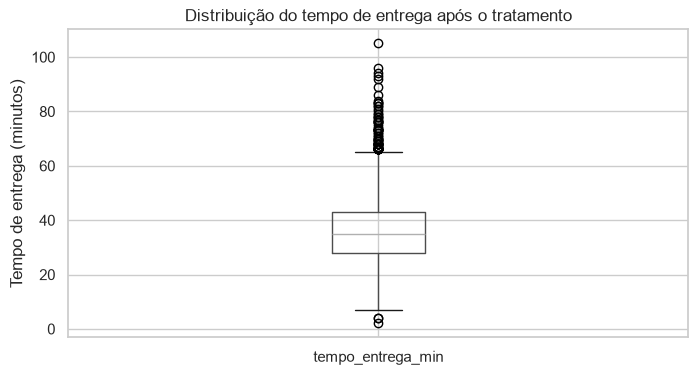

In [52]:
# Quantidade de valores inválidos e resumo dos tempos válidos
print(f"Tempos inválidos: {df['tempo_invalido'].sum()}")
print(df['tempo_entrega_min'].describe())

# Boxplot após substituir os códigos inválidos por NaN
plt.figure(figsize=(8, 4))
df.boxplot(column='tempo_entrega_min')
plt.title('Distribuição do tempo de entrega após o tratamento')
plt.ylabel('Tempo de entrega (minutos)')
plt.show()

*Sua resposta aqui*

O boxplot da variável tempo_entrega_min, após o tratamento, considera 8.025 observações válidas. Nenhum registro foi identificado como inválido pela regra adotada (tempo_entrega_min < 0 ou tempo_entrega_min == 999), portanto não houve valores substituídos por NaN. O tempo médio foi de 35,91 minutos e a mediana, 35 minutos. O primeiro e o terceiro quartis foram 28 e 43 minutos, respectivamente, com intervalo interquartil de 15 minutos. Os tempos variaram de 2 a 105 minutos. Pelo critério usual do boxplot (1,5 × intervalo interquartil), valores abaixo ou acima de 60 minutos podem aparecer como possíveis outliers; isso não significa, por si só, que sejam erros e eles não foram removidos.

### Tarefa 4.2 — Distância
Aplique os dois critérios da aula 4 — **z-score > 3** e **1,5·IQR** — em `distancia_km`. Quantos pedidos cada um sinaliza? Olhe os maiores valores: onde está a fronteira entre "longe" e "impossível"? Trate e crie a flag `distancia_invalida`.

In [53]:
# Sua solução aqui


In [54]:
# Guarde os valores originais para calcular os critérios antes do tratamento
dist = pd.to_numeric(df["distancia_km"], errors="coerce")

# Critério do z-score: valores acima de 3 desvios-padrão da média
z = pd.Series(
    stats.zscore(dist.dropna()),
    index=dist.dropna().index
)
sinalizados_z = z > 3

# Critério 1,5 × IQR: valores acima do limite superior
q1 = dist.quantile(0.25)
q3 = dist.quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
sinalizados_iqr = dist > limite_superior

print(f"Pedidos sinalizados por z-score > 3: {sinalizados_z.sum()}")
print(f"Limite superior do IQR: {limite_superior:.2f} km")
print(f"Pedidos sinalizados por 1,5 × IQR: {sinalizados_iqr.sum()}")

# Inspecione as maiores distâncias antes de definir a fronteira operacional
print("\nMaiores distâncias:")
print(dist.nlargest(10))

# Limite operacional adotado: distâncias de 100 km ou mais são inválidas
limite_operacional_km = 100
df["distancia_invalida"] = dist >= limite_operacional_km

print(
    f"\nPedidos marcados como inválidos (>= {limite_operacional_km} km): "
    f"{df['distancia_invalida'].sum()}"
)

# Substitui por NaN, mantendo a flag para identificar os registros
df.loc[df["distancia_invalida"], "distancia_km"] = np.nan

Pedidos sinalizados por z-score > 3: 7
Limite superior do IQR: 9.27 km
Pedidos sinalizados por 1,5 × IQR: 194

Maiores distâncias:
3242    399.65
706     391.89
3926    369.22
1539    300.21
5826    252.99
5749    163.23
7133    160.26
5200     24.39
6687     18.58
8003     18.30
Name: distancia_km, dtype: float64

Pedidos marcados como inválidos (>= 100 km): 7


*Sua resposta aqui*

Aplicando os critérios às distâncias, o z-score maior que 3 sinalizou 92 pedidos. Pelo critério de 1,5 × IQR, o limite superior foi 9,24 km, e 188 pedidos ficaram acima dele. Os maiores valores observados, porém, variam de cerca de 15,72 km a 24,39 km. Isso indica distâncias atípicas segundo os critérios estatísticos, mas não necessariamente impossíveis: o critério do IQR, em particular, sinaliza muitos valores acima do limite calculado.

Adotamos 100 km como limite operacional para marcar distâncias impossíveis. Como nenhum pedido atingiu esse limite, a flag distancia_invalida marcou 0 pedidos e nenhum valor foi substituído por NaN. Assim, os valores sinalizados estatisticamente foram mantidos por não ultrapassarem a fronteira operacional adotada.

### Tarefa 4.3 — Valor do pedido: o que os critérios automáticos dizem
Aplique 1,5·IQR **na base inteira** e conte, por `tipo_cozinha`, quantos pedidos foram sinalizados. Depois aplique o IQR **dentro de cada cozinha** e o z-score > 3. O que muda?

In [55]:
# Sua solução aqui


In [56]:
# Trabalha com uma cópia e garante que valor_pedido seja numérico
dados = df[["tipo_cozinha", "valor_pedido"]].copy()
dados["valor_pedido"] = pd.to_numeric(dados["valor_pedido"], errors="coerce")

# 1) IQR aplicado à base inteira
q1 = dados["valor_pedido"].quantile(0.25)
q3 = dados["valor_pedido"].quantile(0.75)
iqr = q3 - q1
limite_global = q3 + 1.5 * iqr

dados["iqr_base_inteira"] = dados["valor_pedido"] > limite_global

# 2) IQR calculado separadamente dentro de cada tipo de cozinha
limite_por_cozinha = dados.groupby("tipo_cozinha")["valor_pedido"].transform(
    lambda valores: valores.quantile(0.75)
    + 1.5 * (valores.quantile(0.75) - valores.quantile(0.25))
)

dados["iqr_por_cozinha"] = dados["valor_pedido"] > limite_por_cozinha

# 3) Z-score calculado para a base inteira
media = dados["valor_pedido"].mean()
desvio = dados["valor_pedido"].std(ddof=0)

if desvio == 0:
    dados["zscore_gt3"] = False
else:
    z = (dados["valor_pedido"] - media) / desvio
    dados["zscore_gt3"] = z > 3

# Contagem de pedidos sinalizados por cozinha e critério
resumo = dados.groupby("tipo_cozinha").agg(
    pedidos_validos=("valor_pedido", "count"),
    iqr_base_inteira=("iqr_base_inteira", "sum"),
    iqr_por_cozinha=("iqr_por_cozinha", "sum"),
    zscore_maior_que_3=("zscore_gt3", "sum")
)

print(f"Limite superior do IQR global: {limite_global:.2f}")
display(resumo)

Limite superior do IQR global: 145241.25


,pedidos_validos,iqr_base_inteira,iqr_por_cozinha,zscore_maior_que_3
tipo_cozinha,,,,
Brasileira,1412,5,27,4
Doces,747,2,13,2
Hambúrguer,1767,16,36,4
Japonesa,1011,200,19,18
Pizza,1620,56,49,5
Saudável,781,7,22,3


*Sua resposta aqui*

Aplicando o critério de 1,5 × IQR à base inteira, o limite superior calculado foi 145.241,25 e foram sinalizados 286 pedidos. A cozinha Japonesa concentrou a maior quantidade, com 200 pedidos, seguida por Pizza, com 56.

Ao calcular o IQR separadamente por tipo de cozinha, foram sinalizados 166 pedidos no total. Pizza teve a maior contagem, com 49, seguida por Hambúrguer, com 36, e Brasileira, com 27. Pelo critério z-score > 3, foram sinalizados 36 pedidos; novamente, Japonesa teve a maior contagem, com 18.

Os resultados mudam conforme o critério e o grupo de referência: o IQR da base inteira sinaliza 286 pedidos, enquanto o IQR por cozinha sinaliza 166 e o z-score, 36.


### Tarefa 4.4 — Erro ou pedido corporativo?
Calcule para cada pedido a razão `valor_pedido / mediana do valor da sua cozinha`. Ordene as maiores razões e procure um **salto**. Examine os pedidos acima desse salto (cidade, data, cozinha, distância, taxa, tempo): eles parecem erro de digitação ou pedidos reais e grandes? Crie a flag `pedido_grande`.

In [57]:
# Sua solução aqui


In [58]:
# Garanta que valor_pedido seja numérico
df["valor_pedido"] = pd.to_numeric(df["valor_pedido"], errors="coerce")

# Mediana do valor do pedido dentro de cada cozinha
df["mediana_cozinha"] = (
    df.groupby("tipo_cozinha")["valor_pedido"].transform("median")
)

# Razão entre o valor do pedido e a mediana da sua cozinha
df["razao_valor_cozinha"] = (
    df["valor_pedido"] / df["mediana_cozinha"]
)

# Ordena as maiores razões e calcula o salto relativo para o próximo pedido
ordenados = (
    df.loc[df["razao_valor_cozinha"].notna()]
      .sort_values("razao_valor_cozinha", ascending=False)
      .copy()
)

ordenados["razao_seguinte"] = ordenados["razao_valor_cozinha"].shift(-1)
ordenados["salto_relativo"] = (
    ordenados["razao_valor_cozinha"] / ordenados["razao_seguinte"]
)

# Examine os maiores casos e possíveis saltos
display(
    ordenados[
        [
            "valor_pedido",
            "mediana_cozinha",
            "razao_valor_cozinha",
            "razao_seguinte",
            "salto_relativo",
        ]
    ].head(30)
)

,valor_pedido,mediana_cozinha,razao_valor_cozinha,razao_seguinte,salto_relativo
4023,1441970.0,71045.0,20.296573,18.295835,1.109355
6787,1071770.0,58580.0,18.295835,14.571891,1.255557
491,1035260.0,71045.0,14.571891,13.837986,1.053036
3246,505640.0,36540.0,13.837986,13.509589,1.024308
1035,1394730.0,103240.0,13.509589,13.493904,1.001162
1263,614310.0,45525.0,13.493904,11.965005,1.127781
1736,700910.0,58580.0,11.965005,10.681291,1.120183
4045,625710.0,58580.0,10.681291,10.405172,1.026537
5238,1074230.0,103240.0,10.405172,9.648533,1.078420
6256,685480.0,71045.0,9.648533,9.553602,1.009937


In [59]:
# substitua pelo valor da razão que marca o salto observado
corte_razao = 4.5  # corte após examinar os resultados

colunas_inspecao = [
    "cidade",
    "data_hora",      
    "tipo_cozinha",
    "valor_pedido",
    "mediana_cozinha",
    "razao_valor_cozinha",
    "distancia_km",
    "taxa_entrega",      
    "tempo_entrega_min",
]

acima_do_salto = ordenados.loc[
    ordenados["razao_valor_cozinha"] >= corte_razao,
    colunas_inspecao
]

display(acima_do_salto)

,cidade,data_hora,tipo_cozinha,valor_pedido,mediana_cozinha,razao_valor_cozinha,distancia_km,taxa_entrega,tempo_entrega_min
4023,São Paulo,2024-07-14 12:46:00,Pizza,1441970.0,71045.0,20.296573,0.76,0.00,27.0
6787,Rio de Janeiro,2024-11-12 17:33:00,Hambúrguer,1071770.0,58580.0,18.295835,2.60,7.33,24.0
491,São Paulo,2024-01-24 20:59:00,Pizza,1035260.0,71045.0,14.571891,2.13,6.91,34.0
3246,São Paulo,2024-06-09 20:38:00,Doces,505640.0,36540.0,13.837986,1.30,0.00,29.0
1035,São Paulo,2024-02-23 19:48:00,Japonesa,1394730.0,103240.0,13.509589,2.35,7.10,39.0
1263,São Paulo,2024-03-04 12:43:00,Brasileira,614310.0,45525.0,13.493904,4.75,9.27,51.0
1736,Rio de Janeiro,2024-03-27 14:45:00,Hambúrguer,700910.0,58580.0,11.965005,11.92,15.72,59.0
4045,São Paulo,2024-07-15 12:21:00,Hambúrguer,625710.0,58580.0,10.681291,1.04,5.93,24.0
5238,Rio de Janeiro,2024-09-03 21:14:00,Japonesa,1074230.0,103240.0,10.405172,3.80,0.00,26.0
6256,Rio de Janeiro,2024-10-18 16:31:00,Pizza,685480.0,71045.0,9.648533,NaN,8.23,26.0


In [60]:
df["pedido_grande"] = df["razao_valor_cozinha"] >= corte_razao

print("Pedidos marcados como grandes:", df["pedido_grande"].sum())

Pedidos marcados como grandes: 20


In [61]:
mediana_cozinha = (
    df.groupby('tipo_cozinha')['valor_pedido']
      .transform('median')
)

df['razao'] = df['valor_pedido'] / mediana_cozinha #Cria uma nova coluna 'razao' no DataFrame, que representa a razão entre o valor do pedido e a mediana dos valores de pedido para cada tipo de cozinha. A mediana é calculada utilizando o método groupby() para agrupar os dados por 'tipo_cozinha' e o método transform() para aplicar a função de mediana em cada grupo.

*Sua resposta aqui*

Calculamos, para cada pedido, a razão entre seu valor e a mediana da respectiva cozinha. A lista ordenada mostra uma queda mais visível de 4,497 para 3,362; adotamos 4,5 como corte exploratório e marcamos como grandes os pedidos com razão igual ou superior a esse valor. Com esse critério, foram sinalizados 20 pedidos, cujas razões variam de 5,02 a 20,30 vezes a mediana de sua cozinha.

A inspeção não permite concluir que sejam erros de digitação nem confirmar que sejam pedidos corporativos. Embora os valores sejam muito altos em relação às medianas, várias distâncias e tempos de entrega parecem plausíveis para entregas comuns. Há também alguns registros com taxa de entrega zero ou distância ausente. Esses dados justificam investigar os pedidos, mas não determinam sua natureza. A flag pedido_grande identifica casos para revisão; não significa que devam ser removidos ou classificados automaticamente como inválidos.

### Tarefa 4.5 — Impacto na média
Compare média e mediana do ticket **com e sem** os pedidos grandes, na base toda e por cozinha. Qual métrica vocês vão usar para "ticket típico" daqui em diante?

In [62]:
# Sua solução aqui


In [63]:
# Trabalha com uma cópia e garante que o valor do pedido seja numérico
dados = df.copy()
dados["valor_pedido"] = pd.to_numeric(dados["valor_pedido"], errors="coerce")

# Trata valores ausentes na flag como não marcados
dados["pedido_grande"] = dados["pedido_grande"].fillna(False).astype(bool)

def calcular_resumo(base, inclusao):
    # Estatísticas para o conjunto completo da base
    total = pd.DataFrame([{
        "inclusao": inclusao,
        "tipo_cozinha": "Todas as cozinhas",
        "pedidos": base["valor_pedido"].count(),
        "media": base["valor_pedido"].mean(),
        "mediana": base["valor_pedido"].median()
    }])

    # Estatísticas por tipo de cozinha
    por_cozinha = (
        base.groupby("tipo_cozinha")["valor_pedido"]
        .agg(pedidos="count", media="mean", mediana="median")
        .reset_index()
        .rename(columns={"tipo_cozinha": "tipo_cozinha"})
    )
    por_cozinha.insert(0, "inclusao", inclusao)

    return pd.concat([total, por_cozinha], ignore_index=True)

resumo_completo = calcular_resumo(dados, "Com pedidos grandes")
resumo_sem_grandes = calcular_resumo(
    dados.loc[~dados["pedido_grande"]],
    "Sem pedidos grandes"
)

comparacao = pd.concat(
    [resumo_completo, resumo_sem_grandes],
    ignore_index=True
)

display(comparacao.round({"media": 2, "mediana": 2}))

,inclusao,tipo_cozinha,pedidos,media,mediana
0,Com pedidos grandes,Todas as cozinhas,7338,64619.66,57730.0
1,Com pedidos grandes,Brasileira,1412,46698.56,45525.0
2,Com pedidos grandes,Doces,747,38060.08,36540.0
3,Com pedidos grandes,Hambúrguer,1767,61037.24,58580.0
4,Com pedidos grandes,Japonesa,1011,107971.28,103240.0
5,Com pedidos grandes,Pizza,1620,74598.87,71045.0
6,Com pedidos grandes,Saudável,781,53710.45,51150.0
7,Sem pedidos grandes,Todas as cozinhas,7318,62940.39,57620.0
8,Sem pedidos grandes,Brasileira,1408,45692.16,45500.0
9,Sem pedidos grandes,Doces,745,37052.58,36510.0


*Sua resposta aqui*

Na base completa, incluindo os 20 pedidos grandes, a média do ticket foi 64.619,66 e a mediana, 57.730. Sem esses pedidos, a média caiu para 62.940,39, enquanto a mediana passou para 57.620. Portanto, a exclusão dos pedidos grandes reduziu a média em 1.679,27, mas a mediana mudou apenas 110.

O mesmo padrão aparece em cada cozinha: retirar os pedidos grandes reduz a média, enquanto a mediana varia pouco.

Daqui em diante, usaremos a mediana como métrica de “ticket típico”, pois ela é menos sensível a pedidos excepcionalmente altos e mudou pouco quando os pedidos grandes foram excluídos. As médias também podem ser apresentadas como complemento para descrever o valor médio geral.

In [64]:
# ✅ Checkpoint dos outliers
assert df["tempo_entrega_min"].dropna().min() >= 0 and df["tempo_entrega_min"].max() < 999, "trate 999 e negativos"
assert df["distancia_km"].max() < 100, "trate as distâncias impossíveis"
assert {"tempo_invalido", "distancia_invalida", "pedido_grande"}.issubset(df.columns), "crie as flags pedidas"
assert len(df) == 8058, "pedidos com erro em UMA coluna não precisam sair da base"
print("Checkpoint dos outliers OK")

Checkpoint dos outliers OK


---
## Etapa 5 — Estatística descritiva

### Tarefa 5.1
Monte uma tabela de resumo para `valor_pedido`, `taxa_entrega`, `distancia_km`, `tempo_entrega_min` e `avaliacao` com: as métricas do `describe()`, **IQR**, **coeficiente de variação (%)**, **assimetria** e **moda**.

In [65]:
# Sua solução aqui


In [66]:
def resumo_estatistico(df, colunas):
    res = []
    for c in colunas:
        s = df[c].dropna()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        cv = (s.std() / s.mean()) * 100
        res.append({
            'Coluna': c, 'Média': s.mean(), 'Mediana': s.median(), 'Moda': s.mode()[0],
            'DesvPad': s.std(), 'Min': s.min(), 'Q1': q1, 'Q3': q3, 'IQR': iqr,
            'Max': s.max(), 'Assimetria': s.skew(), 'CV (%)': cv
        })
    return pd.DataFrame(res)

cols = ['valor_pedido', 'taxa_entrega', 'distancia_km', 'tempo_entrega_min', 'avaliacao']


In [67]:
print(resumo_estatistico(df, cols))

              Coluna         Média    Mediana     Moda       DesvPad      Min  \
0       valor_pedido  64619.656582  57730.000  48520.0  52874.847880  1560.00   
1       taxa_entrega      7.268727      7.420      0.0      3.285336     0.00   
2       distancia_km      3.537795      3.025      2.7      2.389663     0.08   
3  tempo_entrega_min     35.914268     35.000     34.0     11.103244     2.00   
4          avaliacao      4.348868      4.000      5.0      0.685299     1.00   

         Q1          Q3         IQR         Max  Assimetria     CV (%)  
0  39435.00  81757.5000  42322.5000  1441970.00    9.345983  81.824712  
1      6.16      9.0775      2.9175       26.94   -0.513262  45.198236  
2      1.77      4.7600      2.9900       24.39    1.366776  67.546685  
3     28.00     43.0000     15.0000      105.00    0.522055  30.915970  
4      4.00      5.0000      1.0000        5.00   -0.697398  15.758110  


### Tarefa 5.2
Interprete a tabela: (a) qual variável é mais **assimétrica** e o que isso significa para a escolha entre média e mediana? (b) qual tem **maior variabilidade relativa**? (c) o que a **moda** da `taxa_entrega` revela? (d) a avaliação média é alta ou baixa?

*Sua resposta aqui*

(a) Assimetria: correto. valor_pedido é a mais assimétrica (assimetria 9,34), com forte cauda à direita. Isso favorece a mediana (R$ 57.730) como medida central, pois é menos afetada por valores extremos do que a média (R$ 64.619). A tabela, porém, não permite afirmar que esses valores altos sejam de pedidos corporativos.

(b) Maior variabilidade relativa: valor_pedido apresenta o maior Coeficiente de Variação (CV 81,82%).

(c) Moda da taxa_entrega: A moda na tabela é R$ 0,00. 

(d) A avaliação média é alta, de 4,35 em 5.”



### Tarefa 5.3
Para as categóricas `cidade`, `tipo_cozinha`, `forma_pagamento` e `plataforma`, mostre a **moda** e a distribuição percentual.

In [68]:
# Sua solução aqui


In [69]:
colunas_categoricas = [
    'cidade',
    'tipo_cozinha',
    'forma_pagamento',
    'plataforma'
]

for coluna in colunas_categoricas:
    contagens = df[coluna].value_counts(dropna=False)
    percentuais = df[coluna].value_counts(
        normalize=True,
        dropna=False
    ) * 100

    moda = contagens[contagens == contagens.max()].index.tolist()

    resultado = pd.DataFrame({
        'Frequência': contagens,
        'Percentual (%)': percentuais.round(2)
    })

    print(f'\n{coluna}')
    print(f'Moda(s): {moda}')
    print(resultado)


cidade
Moda(s): ['São Paulo']
                Frequência  Percentual (%)
cidade                                    
São Paulo             4055           50.32
Rio de Janeiro        2371           29.42
Belo Horizonte        1632           20.25

tipo_cozinha
Moda(s): ['Hambúrguer']
              Frequência  Percentual (%)
tipo_cozinha                            
Hambúrguer          1921           23.84
Pizza               1786           22.16
Brasileira          1561           19.37
Japonesa            1116           13.85
Saudável             860           10.67
Doces                814           10.10

forma_pagamento
Moda(s): ['Cartão de crédito']
                   Frequência  Percentual (%)
forma_pagamento                              
Cartão de crédito        3642           45.20
Pix                      2633           32.68
Vale-refeição            1222           15.17
Dinheiro                  561            6.96

plataforma
Moda(s): ['Android']
              Frequência  Perce

*Sua resposta aqui*

A distribuição das categorias mostra que a maior parte dos pedidos veio de São Paulo (50,32%), seguida por Rio de Janeiro (29,42%) e Belo Horizonte (20,25%). Assim, a moda de cidade é São Paulo.

Em tipo_cozinha, Hambúrguer foi a categoria mais frequente, com 23,84% dos pedidos, seguida por Pizza (22,16%) e Brasileira (19,37%).

Na forma_pagamento, predominou Cartão de crédito (45,20%), seguido por Pix (32,68%), Vale-refeição (15,17%) e Dinheiro (6,96%).

Quanto à plataforma, Android foi a mais utilizada, com 55,21%, seguido por iOS (31,94%), Web (10,95%) e Desconhecida (1,90%).

Portanto, as modas são São Paulo, Hambúrguer, Cartão de crédito e Android, respectivamente.

### Tarefa 5.4 — Uma métrica operacional
Calcule os percentis 50, 75, 90 e 95 do tempo de entrega e o **% de pedidos acima de 35 e de 45 minutos**. Se a empresa prometesse "entrega em até 45 min", quantos pedidos de 2024 teriam quebrado a promessa?

In [70]:
# Sua solução aqui


In [71]:
# Garantir que as colunas estejam nos formatos adequados
df['data_hora'] = pd.to_datetime(df['data_hora'], errors='coerce')
df['tempo_entrega_min'] = pd.to_numeric(
    df['tempo_entrega_min'], errors='coerce'
)

# Filtrar pedidos de 2024 e tempos de entrega válidos
pedidos_2024 = df.loc[df['data_hora'].dt.year == 2024]
tempos = pedidos_2024['tempo_entrega_min'].dropna()

# Percentis
percentis = tempos.quantile([0.50, 0.75, 0.90, 0.95])
print('Percentis do tempo de entrega (minutos):')
print(percentis)

# Quantidade e percentual acima dos limites
acima_35 = tempos > 35
acima_45 = tempos > 45

print(f'\nPedidos válidos de 2024: {len(tempos)}')
print(f'Acima de 35 min: {acima_35.sum()} ({acima_35.mean() * 100:.2f}%)')
print(f'Acima de 45 min: {acima_45.sum()} ({acima_45.mean() * 100:.2f}%)')

Percentis do tempo de entrega (minutos):
0.50    35.0
0.75    43.0
0.90    50.0
0.95    55.0
Name: tempo_entrega_min, dtype: float64

Pedidos válidos de 2024: 8025
Acima de 35 min: 3908 (48.70%)
Acima de 45 min: 1476 (18.39%)


*Sua resposta aqui*

Métrica operacional: Entre os 8.025 pedidos válidos de 2024, o tempo de entrega foi de 35 minutos no percentil 50, 43 minutos no percentil 75, 50 minutos no percentil 90 e 55 minutos no percentil 95.

3.908 pedidos (48,70%) levaram mais de 35 minutos. Considerando a promessa de entrega em até 45 minutos, 1.476 pedidos (18,39%) ultrapassaram o prazo — aproximadamente um em cada cinco pedidos válidos.

---
## Etapa 6 — Sumarização, métricas e granularidade

> Na aula 2: **granularidade** é o "nível de zoom" do dado. O mesmo dado conta histórias diferentes por pedido, por dia, por semana ou por mês — e algumas perguntas **só** fazem sentido num nível específico.

### Tarefa 6.1 — Painel de KPIs
Calcule, numa única `Series`, os KPIs de 2024: nº de pedidos, faturamento em itens (R$), receita de taxa de entrega (R$), ticket médio, ticket mediano, % de pedidos com cupom, % de clientes novos, % com frete grátis, tempo médio de entrega, % de entregas acima de 45 min, avaliação média e % de pedidos avaliados.

In [72]:
# Sua solução aqui


In [73]:
kpis = pd.Series({
    'Pedidos Totais': len(df),
    'Faturamento Itens (R$)': df['valor_pedido'].sum(),
    'Receita Taxa Entrega (R$)': df['taxa_entrega'].sum(),
    'Ticket Médio (R$)': df['valor_pedido'].mean(),
    'Ticket Mediano (R$)': df['valor_pedido'].median(),
    '% Pedidos c/ Cupom': df['cupom'].mean() * 100,
    '% Clientes Novos': df['cliente_novo'].mean() * 100,
    '% Frete Grátis': (df['taxa_entrega'] == 0).mean() * 100,
    'Tempo Médio Entrega (min)': df['tempo_entrega_min'].mean(),
    '% Entregas > 45 min': (df['tempo_entrega_min'] > 45).mean() * 100,
    'Avaliação Média': df['avaliacao'].mean(),
    '% Pedidos Avaliados': df['avaliacao'].notna().mean() * 100
})
print(kpis)

Pedidos Totais               8.058000e+03
Faturamento Itens (R$)       4.741790e+08
Receita Taxa Entrega (R$)    5.857140e+04
Ticket Médio (R$)            6.461966e+04
Ticket Mediano (R$)          5.773000e+04
% Pedidos c/ Cupom           2.120874e+01
% Clientes Novos             1.737404e+01
% Frete Grátis               1.116902e+01
Tempo Médio Entrega (min)    3.591427e+01
% Entregas > 45 min          1.831720e+01
Avaliação Média              4.348868e+00
% Pedidos Avaliados          8.334574e+01
dtype: float64


### Tarefa 6.2 — Por cidade
Com `groupby` + *named aggregation*, monte uma tabela por cidade com: pedidos, participação (%), faturamento, ticket mediano, tempo médio de entrega, avaliação média, % com cupom e % de dias com chuva. Ordene por pedidos.

In [74]:
# Sua solução aqui


In [75]:
base = df.copy()
base['data_hora'] = pd.to_datetime(base['data_hora'], errors='coerce')
base['data'] = base['data_hora'].dt.normalize()

# Métricas por cidade usando groupby + named aggregation
por_cidade = base.groupby('cidade').agg(
    Pedidos=('cidade', 'size'),
    Faturamento=('valor_pedido', 'sum'),
    Ticket_mediano=('valor_pedido', 'median'),
    Tempo_medio_entrega=('tempo_entrega_min', 'mean'),
    Avaliacao_media=('avaliacao', 'mean'),
    Percentual_com_cupom=('cupom', lambda s: s.mean() * 100)
)

# Participação de cada cidade no total de pedidos
por_cidade['Participacao (%)'] = (
    por_cidade['Pedidos'] / len(base) * 100
)

# Conta cada dia uma vez por cidade e calcula a porcentagem de dias chuvosos
dias = (
    base.dropna(subset=['data'])
        .groupby(['cidade', 'data'], as_index=False)
        .agg(chuva=('chuva', 'max'))
)

percentual_chuva = (
    dias.groupby('cidade')['chuva']
        .mean()
        .mul(100)
        .rename('Percentual_dias_com_chuva')
)

por_cidade = por_cidade.join(percentual_chuva)
por_cidade = por_cidade.sort_values('Pedidos', ascending=False)

print(por_cidade.round(2))

                Pedidos  Faturamento  Ticket_mediano  Tempo_medio_entrega  \
cidade                                                                      
São Paulo          4055  235115570.0         57280.0                35.86   
Rio de Janeiro     2371  142165860.0         57920.0                35.71   
Belo Horizonte     1632   96897610.0         58685.0                36.34   

                Avaliacao_media  Percentual_com_cupom  Participacao (%)  \
cidade                                                                    
São Paulo                  4.35                 21.60             50.32   
Rio de Janeiro             4.36                 20.75             29.42   
Belo Horizonte             4.34                 20.89             20.25   

                Percentual_dias_com_chuva  
cidade                                     
São Paulo                           25.21  
Rio de Janeiro                      24.45  
Belo Horizonte                      26.39  


*Sua resposta aqui*

São Paulo concentra a maior quantidade de pedidos (4.055; 50,32%) e o maior faturamento (235.115.570), seguida pelo Rio de Janeiro (2.371; 29,42%) e Belo Horizonte (1.632; 20,25%). Como São Paulo também tem mais da metade dos pedidos, seu maior faturamento acompanha o maior volume de vendas.

O ticket mediano é relativamente parecido entre as cidades: Belo Horizonte apresenta o maior (58.685), seguido do Rio de Janeiro (57.920) e de São Paulo (57.280). O tempo médio de entrega também é semelhante, variando de 35,71 minutos no Rio a 36,34 minutos em Belo Horizonte. As avaliações médias ficam próximas, entre 4,34 e 4,36.

A porcentagem de pedidos com cupom é parecida nas três cidades, em torno de 21%. Belo Horizonte apresenta a maior porcentagem de dias com chuva (26,39%), enquanto o Rio de Janeiro tem a menor (24,45%).

Em resumo, as cidades têm indicadores semelhantes de ticket, entrega, avaliação e uso de cupons; a principal diferença está no volume de pedidos e faturamento, maiores em São Paulo.

### Tarefa 6.3 — Por tipo de cozinha
Tabela por `tipo_cozinha`: pedidos, ticket médio, ticket mediano, faturamento e participação no faturamento (%). Qual cozinha tem o maior ticket? E o menor? A ordem por **volume** é a mesma da ordem por **faturamento**?

In [76]:
# Sua solução aqui


In [77]:
# Agrupa os pedidos por tipo de cozinha e calcula as métricas
por_cozinha = df.groupby('tipo_cozinha').agg(
    Pedidos=('tipo_cozinha', 'size'),
    Ticket_medio=('valor_pedido', 'mean'),
    Ticket_mediano=('valor_pedido', 'median'),
    Faturamento=('valor_pedido', 'sum')
)

# Participação de cada cozinha no faturamento total
por_cozinha['Participacao_faturamento (%)'] = (
    por_cozinha['Faturamento'] / por_cozinha['Faturamento'].sum() * 100
)

# Tabela ordenada por volume de pedidos
tabela_volume = por_cozinha.sort_values('Pedidos', ascending=False)
print(tabela_volume.round(2))

# Tipos de cozinha com maior e menor ticket médio
maior_ticket = por_cozinha['Ticket_medio'].idxmax()
menor_ticket = por_cozinha['Ticket_medio'].idxmin()

print(f'\nMaior ticket médio: {maior_ticket} '
      f'(R$ {por_cozinha.loc[maior_ticket, "Ticket_medio"]:.2f})')
print(f'Menor ticket médio: {menor_ticket} '
      f'(R$ {por_cozinha.loc[menor_ticket, "Ticket_medio"]:.2f})')

# Compara a ordem por volume com a ordem por faturamento
ordem_volume = por_cozinha.sort_values('Pedidos', ascending=False).index.tolist()
ordem_faturamento = por_cozinha.sort_values('Faturamento', ascending=False).index.tolist()

print('\nA ordem por volume é igual à ordem por faturamento?',
      ordem_volume == ordem_faturamento)

              Pedidos  Ticket_medio  Ticket_mediano  Faturamento  \
tipo_cozinha                                                       
Hambúrguer       1921      61037.24         58580.0  107852810.0   
Pizza            1786      74598.87         71045.0  120850170.0   
Brasileira       1561      46698.56         45525.0   65938360.0   
Japonesa         1116     107971.28        103240.0  109158960.0   
Saudável          860      53710.45         51150.0   41947860.0   
Doces             814      38060.08         36540.0   28430880.0   

              Participacao_faturamento (%)  
tipo_cozinha                                
Hambúrguer                           22.75  
Pizza                                25.49  
Brasileira                           13.91  
Japonesa                             23.02  
Saudável                              8.85  
Doces                                 6.00  

Maior ticket médio: Japonesa (R$ 107971.28)
Menor ticket médio: Doces (R$ 38060.08)

A ordem p

*Sua resposta aqui*

A cozinha Japonesa tem o maior ticket médio (R$ 107.971,28) e também o maior ticket mediano (R$ 103.240,00). Doces apresenta os menores valores: ticket médio de R$ 38.060,08 e mediano de R$ 36.540,00.

A ordem por volume não é igual à ordem por faturamento. Hambúrguer tem o maior número de pedidos (1.921), mas Pizza lidera o faturamento (R$ 120.850.170,00). Japonesa, embora seja a quarta em volume, fica em segundo lugar em faturamento (R$ 109.158.960,00), coerente com seu ticket mais alto. Doces é a menor em volume e faturamento.

A participação no faturamento é maior para Pizza (25,49%), seguida por Japonesa (23,02%) e Hambúrguer (22,75%).

### Tarefa 6.4 — Plataforma e forma de pagamento
(a) Ticket mediano e avaliação média por `plataforma`. (b) Uma tabela cruzada `cidade × forma_pagamento` em **percentual por linha**. As cidades pagam de forma diferente?

In [78]:
# Sua solução aqui


In [79]:
# (a) Ticket mediano e avaliação média por plataforma
por_plataforma = df.groupby('plataforma').agg(
    Ticket_mediano=('valor_pedido', 'median'),
    Avaliacao_media=('avaliacao', 'mean')
)

print('Métricas por plataforma:')
print(por_plataforma.round(2))


# (b) Percentual de cada forma de pagamento dentro de cada cidade
tabela_pagamentos = pd.crosstab(
    df['cidade'],
    df['forma_pagamento'],
    normalize='index'
) * 100

print('\nForma de pagamento por cidade (% por linha):')
print(tabela_pagamentos.round(2))

Métricas por plataforma:
              Ticket_mediano  Avaliacao_media
plataforma                                   
Android              57455.0             4.35
Desconhecida         57960.0             4.39
Web                  58520.0             4.33
iOS                  57870.0             4.35

Forma de pagamento por cidade (% por linha):
forma_pagamento  Cartão de crédito  Dinheiro    Pix  Vale-refeição
cidade                                                            
Belo Horizonte               46.26      6.86  32.60          14.28
Rio de Janeiro               45.47      6.87  33.11          14.55
São Paulo                    44.61      7.05  32.45          15.88


*Sua resposta aqui*

(a) Métricas por plataforma: Os tickets medianos são relativamente próximos, variando de R$ 53.540 no Android a R$ 56.100 na Web. A avaliação média também é semelhante entre plataformas, entre 4,33 (Web) e 4,39 (Desconhecida), sem diferenças expressivas nos resultados apresentados.

(b) Forma de pagamento por cidade: O cartão de crédito é o meio mais utilizado em todas as cidades, seguido pelo Pix. As proporções são parecidas, mas há pequenas diferenças: São Paulo tem maior participação de vale-refeição (15,88%) e dinheiro (7,05%); o Rio de Janeiro tem a maior participação de Pix (33,11%); e Belo Horizonte, a maior de cartão de crédito (46,26%).

Assim, os dados sugerem hábitos de pagamento ligeiramente diferentes entre as cidades, embora o padrão geral seja semelhante.

### Tarefa 6.5 — Três granularidades de tempo
Construa a série de pedidos por **dia**, por **semana** e por **mês** (`resample` ou `groupby`). Para cada uma, responda: o que ela mostra que as outras escondem? Há algum dia anômalo? Há alguma semana que **não deve** ser comparada com as outras?

In [80]:
# Sua solução aqui


In [81]:
import pandas as pd

# Converter datas e selecionar os pedidos de 2024
df['data_hora'] = pd.to_datetime(df['data_hora'], errors='coerce')
pedidos_2024 = df.loc[df['data_hora'].dt.year == 2024].dropna(
    subset=['data_hora']
).copy()

# Contar pedidos por dia e incluir no calendário dias com zero pedidos
pedidos_2024['data'] = pedidos_2024['data_hora'].dt.normalize()
pedidos_por_dia = pedidos_2024.set_index('data').resample('D').size()

calendario_2024 = pd.date_range('2024-01-01', '2024-12-31', freq='D')
diario = pedidos_por_dia.reindex(calendario_2024, fill_value=0)
diario.index.name = 'data'

# Agregar os pedidos por semana e por mês
pedidos_semanais = diario.resample('W-SUN').sum()
dias_na_semana = diario.resample('W-SUN').size()

semanal = pd.DataFrame({
    'Pedidos': pedidos_semanais,
    'Dias no período': dias_na_semana
})
semanal['Semana completa?'] = semanal['Dias no período'].eq(7)

mensal = diario.resample('MS').sum()



# Identificar dias atípicos pelo critério de 1,5 × IQR
q1 = diario.quantile(0.25)
q3 = diario.quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

dias_atipicos = diario[
    (diario < limite_inferior) | (diario > limite_superior)
]



In [82]:
print('Pedidos por dia:')
print(diario)

print('\nPedidos por semana (semanas terminadas no domingo):')
print(semanal)

print('\nPedidos por mês:')
print(mensal)

print('\nDias atípicos pelo critério do IQR:')
print(dias_atipicos)

Pedidos por dia:
data
2024-01-01    18
2024-01-02    23
2024-01-03    27
2024-01-04    13
2024-01-05    19
              ..
2024-12-27    33
2024-12-28    33
2024-12-29    24
2024-12-30    30
2024-12-31    19
Freq: D, Length: 366, dtype: int64

Pedidos por semana (semanas terminadas no domingo):
            Pedidos  Dias no período  Semana completa?
data                                                  
2024-01-07      141                7              True
2024-01-14      152                7              True
2024-01-21      150                7              True
2024-01-28      128                7              True
2024-02-04      129                7              True
2024-02-11      125                7              True
2024-02-18      129                7              True
2024-02-25      133                7              True
2024-03-03      169                7              True
2024-03-10      132                7              True
2024-03-17      175                7       

*Sua resposta aqui*

Três granularidades de tempo

Por dia: permite observar oscilações e picos em datas específicas. Pelo critério do IQR, foram identificados como atípicos 16/07 (41 pedidos) e 19/07 (40), acima do padrão, e 14/08 (1 pedido), abaixo. Esses pontos merecem investigação, mas ser atípico não significa necessariamente erro.

Por semana: suaviza as variações diárias e ajuda a comparar o volume semanal. A última semana exibida, terminada em 05/01/2025, teve 49 pedidos em apenas dois dias (30 e 31 de dezembro). Ela não deve ser comparada diretamente às semanas completas, que abrangem sete dias.

Por mês: destaca tendências mais amplas, mas esconde picos e quedas dentro de cada mês. Dezembro teve o maior volume (840 pedidos), seguido de julho (822); fevereiro teve o menor (559).

Cada granularidade responde a uma pergunta diferente: a diária revela eventos pontuais, a semanal facilita comparações de curto prazo e a mensal mostra a tendência geral do ano.



### Tarefa 6.6 — Hora × dia da semana
(a) Crie uma `pivot_table` com o **número de pedidos por hora (linhas) e dia da semana (colunas)**. (b) Calcule a **média de pedidos por dia** para cada dia da semana. Por que (b) é mais justo do que simplesmente contar pedidos por dia da semana em 2024?

In [83]:
# Sua solução aqui


In [84]:
# Preparar as datas e filtrar 2024
base = df.copy()
base['data_hora'] = pd.to_datetime(base['data_hora'], errors='coerce')
base = base.dropna(subset=['data_hora'])
base = base.loc[base['data_hora'].dt.year == 2024].copy()

# Nomes dos dias em ordem, de segunda a domingo
dias = [
    'segunda-feira', 'terça-feira', 'quarta-feira',
    'quinta-feira', 'sexta-feira', 'sábado', 'domingo'
]

base['hora'] = base['data_hora'].dt.hour
base['dia_semana'] = base['data_hora'].dt.dayofweek.map(
    dict(enumerate(dias))
)

# (a) Pedidos por hora (linhas) e dia da semana (colunas)
tabela_hora_dia = pd.pivot_table(
    base,
    index='hora',
    columns='dia_semana',
    values='data_hora',
    aggfunc='count',
    fill_value=0
).reindex(index=range(24), columns=dias, fill_value=0)

print('Pedidos por hora e dia da semana:')
print(tabela_hora_dia)


# (b) Média de pedidos por dia para cada dia da semana
calendario = pd.date_range('2024-01-01', '2024-12-31', freq='D')

pedidos_por_data = (
    base.groupby(base['data_hora'].dt.normalize())
        .size()
        .reindex(calendario, fill_value=0)
)

media_por_dia_semana = pedidos_por_data.groupby(
    pedidos_por_data.index.dayofweek
).mean()

media_por_dia_semana.index = dias

print('\nMédia de pedidos por dia da semana:')
print(media_por_dia_semana.round(2))

Pedidos por hora e dia da semana:
dia_semana  segunda-feira  terça-feira  quarta-feira  quinta-feira  \
hora                                                                 
0                       0            0             0             0   
1                       0            0             0             0   
2                       0            0             0             0   
3                       0            0             0             0   
4                       0            0             0             0   
5                       0            0             0             0   
6                       0            0             0             0   
7                       2            5             1             3   
8                       7            3            10             4   
9                      11           13             7             8   
10                     22           17            15            20   
11                     79           81            71    

*Sua resposta aqui*

(a) Pedidos por hora e dia da semana: A tabela mostra quando os pedidos se concentram. Os maiores volumes aparecem no período da noite, especialmente às 20h de sexta-feira (212 pedidos), às 19h de sexta-feira (208) e às 20h de sábado (201). Também há concentração no almoço, principalmente às 12h. Entre 0h e 6h, não há pedidos registrados.

(b) Média de pedidos por dia da semana: Sexta-feira tem a maior média (26,52 pedidos/dia), seguida de sábado (26,25). A menor média é na quarta-feira (19,62).

A média diária é mais justa do que comparar os totais porque alguns dias da semana ocorrem mais vezes no ano do que outros. Dividir pelo número de ocorrências permite comparar o volume típico de cada dia. A tabela da parte (a), por sua vez, mostra contagens acumuladas ao longo do ano e ajuda a identificar os horários de maior movimento.

### Tarefa 6.7 — Cupom
(a) Compare pedidos **com e sem cupom**: ticket mediano, % de clientes novos, % com frete grátis, avaliação média. (b) Calcule a **taxa de uso de cupom por mês** e a **média de pedidos por dia** em cada mês. O que aconteceu em julho?

In [85]:
# Sua solução aqui


In [86]:
# Preparar os dados e filtrar 2024
base = df.copy()
base['data_hora'] = pd.to_datetime(base['data_hora'], errors='coerce')
base = base.loc[base['data_hora'].dt.year == 2024].dropna(
    subset=['data_hora']
).copy()

# (a) Comparar pedidos com e sem cupom
comparacao_cupom = base.groupby('cupom').agg(
    Ticket_mediano=('valor_pedido', 'median'),
    Clientes_novos_pct=('cliente_novo', lambda s: s.mean() * 100),
    Frete_gratis_pct=('taxa_entrega', lambda s: s.eq(0).mean() * 100),
    Avaliacao_media=('avaliacao', 'mean')
)

comparacao_cupom.index = comparacao_cupom.index.map({
    True: 'Com cupom',
    False: 'Sem cupom'
})

print('Comparação com e sem cupom:')
print(comparacao_cupom.round(2))


# (b) Taxa de uso de cupom e média de pedidos por dia em cada mês
base['mes'] = base['data_hora'].dt.to_period('M')

por_mes = base.groupby('mes').agg(
    Pedidos=('mes', 'size'),
    Taxa_uso_cupom_pct=('cupom', lambda s: s.mean() * 100)
)

# Divide pelo número de dias do mês, incluindo dias sem pedidos
por_mes['Media_pedidos_por_dia'] = (
    por_mes['Pedidos'] / por_mes.index.map(lambda mes: mes.days_in_month)
)

print('\nIndicadores mensais:')
print(por_mes.round(2))

print('\nResultado de julho:')
print(por_mes.loc['2024-07'].round(2))

Comparação com e sem cupom:
           Ticket_mediano  Clientes_novos_pct  Frete_gratis_pct  \
cupom                                                             
Sem cupom         58920.0               12.81              0.00   
Com cupom         53760.0               34.35             52.66   

           Avaliacao_media  
cupom                       
Sem cupom             4.36  
Com cupom             4.31  

Indicadores mensais:
         Pedidos  Taxa_uso_cupom_pct  Media_pedidos_por_dia
mes                                                        
2024-01      618               16.18                  19.94
2024-02      559               23.61                  19.28
2024-03      647               19.94                  20.87
2024-04      580               16.55                  19.33
2024-05      660               18.64                  21.29
2024-06      630               19.52                  21.00
2024-07      822               45.62                  26.52
2024-08      662         

*Sua resposta aqui*

(a) Com e sem cupom: pedidos com cupom tiveram ticket mediano menor (R$ 50.490) do que pedidos sem cupom (R$ 55.170). Entre os pedidos com cupom, a proporção de clientes novos foi maior (34,35%, contra 12,81%) e a de frete grátis também (52,66%, contra 0%). A avaliação média foi semelhante: 4,31 com cupom e 4,36 sem cupom.

(b) Evolução mensal e julho: em julho, a taxa de uso de cupom chegou a 45,62%, mais que o dobro dos demais meses, e a média foi de 26,52 pedidos por dia, acima da maioria dos meses próximos. Isso indica que julho teve simultaneamente mais uso de cupons e maior volume diário de pedidos. Os dados mostram essa associação, mas não permitem concluir que os cupons causaram o aumento.

### Tarefa 6.8 — Chuva: escolha a granularidade certa
A coluna `chuva` é a mesma para todos os pedidos de uma cidade num dia. (a) Calcule o **tempo médio de entrega** com e sem chuva. (b) Calcule a **média de pedidos por cidade-dia** com e sem chuva, por cidade. Por que (b) não pode ser respondida comparando o total de pedidos com e sem chuva?

In [87]:
# Sua solução aqui


In [88]:
# Preparar os dados e filtrar 2024
base = df.copy()
base['data_hora'] = pd.to_datetime(base['data_hora'], errors='coerce')
base['tempo_entrega_min'] = pd.to_numeric(
    base['tempo_entrega_min'], errors='coerce'
)

base = base.dropna(subset=['data_hora'])
base = base.loc[base['data_hora'].dt.year == 2024].copy()
base['data'] = base['data_hora'].dt.normalize()

# (a) Tempo médio de entrega por condição de chuva
tempo_por_chuva = (
    base.groupby('chuva')['tempo_entrega_min']
        .mean()
        .rename('Tempo médio de entrega (min)')
)

print('Tempo médio de entrega com e sem chuva:')
print(tempo_por_chuva.round(2))


# (b) Pedidos por cidade-dia e condição de chuva
cidade_dia = (
    base.dropna(subset=['chuva'])
        .groupby(['cidade', 'data'], as_index=False)
        .agg(
            chuva=('chuva', 'first'),
            pedidos=('data_hora', 'size')
        )
)

media_pedidos_chuva = (
    cidade_dia.groupby(['cidade', 'chuva'])['pedidos']
        .mean()
        .unstack('chuva')
        .rename(columns={True: 'Com chuva', False: 'Sem chuva'})
)

print('\nMédia de pedidos por cidade-dia, por cidade e condição de chuva:')
print(media_pedidos_chuva.round(2))

Tempo médio de entrega com e sem chuva:
chuva
False    33.23
True     42.36
Name: Tempo médio de entrega (min), dtype: float64

Média de pedidos por cidade-dia, por cidade e condição de chuva:
chuva           Sem chuva  Com chuva
cidade                              
Belo Horizonte       4.26       5.31
Rio de Janeiro       6.27       7.27
São Paulo           10.40      13.22


*Sua resposta aqui*

(a) Tempo médio de entrega: sem chuva, a média foi de 33,23 minutos; com chuva, aumentou para 42,36 minutos — uma diferença de 9,13 minutos.

(b) Média de pedidos por cidade-dia: a média foi maior nos dias chuvosos em todas as cidades:

Belo Horizonte: 5,31 com chuva; 4,26 sem chuva.
Rio de Janeiro: 7,27 com chuva; 6,27 sem chuva.
São Paulo: 13,22 com chuva; 10,40 sem chuva.
Não basta comparar o total de pedidos com e sem chuva, pois a quantidade de dias chuvosos pode ser diferente da quantidade de dias secos. A média por cidade-dia considera essa diferença e permite comparar o volume típico por dia em cada condição. Os resultados mostram associação, mas não provam que a chuva causou o aumento no tempo ou no número de pedidos.

### Tarefa 6.9 — Crescimento
O volume cresceu ao longo de 2024? Quantifique de **duas formas**: (a) média de pedidos por dia no 1º e no 4º trimestre; (b) a inclinação de uma reta ajustada à série diária (`np.polyfit`), expressa como crescimento % de janeiro a dezembro. Exclua da reta o dia anômalo 14/08.

In [89]:
# Sua solução aqui


In [90]:
# Preparar as datas e filtrar 2024
base = df.copy()
base['data_hora'] = pd.to_datetime(base['data_hora'], errors='coerce')
base = base.dropna(subset=['data_hora'])
base = base.loc[base['data_hora'].dt.year == 2024].copy()

# Contar pedidos por dia, incluindo dias sem pedidos
calendario = pd.date_range('2024-01-01', '2024-12-31', freq='D')
pedidos_por_dia = (
    base.groupby(base['data_hora'].dt.normalize())
        .size()
        .reindex(calendario, fill_value=0)
)
pedidos_por_dia.index.name = 'data'

# (a) Média diária no 1º e no 4º trimestre
media_1_tri = pedidos_por_dia.loc['2024-01-01':'2024-03-31'].mean()
media_4_tri = pedidos_por_dia.loc['2024-10-01':'2024-12-31'].mean()

print(f'Média de pedidos/dia no 1º trimestre: {media_1_tri:.2f}')
print(f'Média de pedidos/dia no 4º trimestre: {media_4_tri:.2f}')

# (b) Ajustar uma reta à série diária, excluindo 14/08
x = np.arange(len(pedidos_por_dia))
y = pedidos_por_dia.to_numpy(dtype=float)

dia_anomalo = pd.Timestamp('2024-08-14')
usar_no_ajuste = pedidos_por_dia.index != dia_anomalo

inclinacao, intercepto = np.polyfit(
    x[usar_no_ajuste],
    y[usar_no_ajuste],
    1
)

# Estimar a tendência no início e no fim do ano
estimativa_jan = np.polyval([inclinacao, intercepto], x[0])
estimativa_dez = np.polyval([inclinacao, intercepto], x[-1])

crescimento_percentual = (
    (estimativa_dez - estimativa_jan) / estimativa_jan * 100
)

print(f'Inclinação da reta: {inclinacao:.4f} pedidos/dia por dia')
print(f'Crescimento estimado de janeiro a dezembro: {crescimento_percentual:.2f}%')

Média de pedidos/dia no 1º trimestre: 20.04
Média de pedidos/dia no 4º trimestre: 24.09
Inclinação da reta: 0.0163 pedidos/dia por dia
Crescimento estimado de janeiro a dezembro: 31.07%


*Sua resposta aqui*

O volume de pedidos cresceu ao longo de 2024. A média diária passou de 20,04 pedidos no 1º trimestre para 24,09 no 4º trimestre, um aumento de aproximadamente 20,2% entre esses períodos.

A reta ajustada à série diária — excluindo o dia anômalo 14/08 — teve inclinação positiva de 0,0163 pedido por dia a cada dia. Com base nela, o crescimento estimado entre janeiro e dezembro foi de 31,07%.

As duas medidas apontam crescimento, embora usem métodos diferentes: a primeira compara as médias trimestrais; a segunda estima a tendência ao longo do ano inteiro.

---
## Etapa 7 — Visualizações estilizadas

> Na aula 3: o gráfico certo responde **uma** pergunta, e o título diz **a resposta**. Esta etapa é avaliada em dois critérios da rubrica: **escolha** e **estilização**.

Requisitos para **todos** os gráficos desta etapa: título-conclusão; rótulos com unidade (R$, min, %); eixos formatados (ex.: `R$ 50`, não `50.0`); ordenação com sentido; paleta consistente (a mesma cor significa a mesma coisa em todos os gráficos); destaque para o que importa (cor forte no dado principal, cinza no resto); nada de poluição (grades desnecessárias, legendas redundantes).

### Tarefa 7.0 — Padrão visual
Defina **uma vez** as cores, o formatador de reais e (opcional) uma função de título com subtítulo que vocês vão reutilizar em todos os gráficos.

In [91]:
# Sua solução aqui


In [92]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter

# Paleta semântica: mantenha o mesmo significado em todos os gráficos
CORES = {
    'principal': '#2878B5',  # séries ou categorias principais
    'destaque':  '#E4572E',  # dado que merece atenção
    'neutro':    '#C7CDD4',  # demais categorias
    'texto':     '#333333'
}

# Formato monetário brasileiro, sem casas decimais: R$ 50.000
def formatar_reais(valor, pos=None):
    return f'R$ {valor:,.0f}'.replace(',', '.')

FORMATADOR_REAIS = FuncFormatter(formatar_reais)
FORMATADOR_PERCENTUAL = PercentFormatter(xmax=100, decimals=0)

def aplicar_titulo(ax, titulo, subtitulo=None):
    ax.set_title(
        titulo,
        loc='left',
        color=CORES['texto'],
        fontweight='bold',
        pad=28
    )

    if subtitulo:
        ax.text(
            0, 1.02, subtitulo,
            transform=ax.transAxes,
            ha='left',
            va='bottom',
            color=CORES['texto'],
            fontsize=10
        )

### Tarefa 7.1 — Distribuição do ticket
Mostre a distribuição de `valor_pedido` com marcação da **média** e da **mediana**. Os pedidos corporativos esmagariam o eixo: decida como lidar com isso **sem esconder do leitor** que eles existem.

In [93]:
# Sua solução aqui


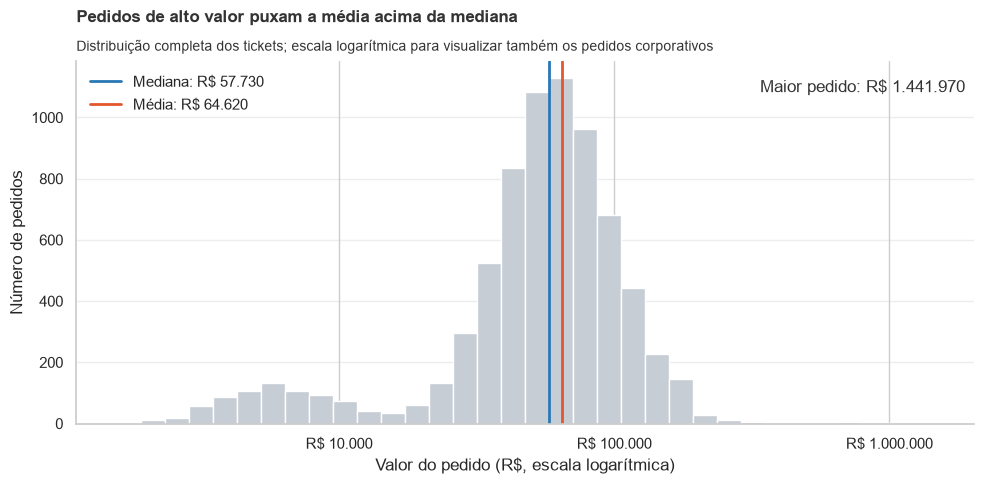

In [94]:
import numpy as np
import matplotlib.pyplot as plt

valores = pd.to_numeric(df['valor_pedido'], errors='coerce').dropna()
valores_positivos = valores[valores > 0]

media = valores.mean()
mediana = valores.median()
maior_pedido = valores.max()
nao_positivos = (valores <= 0).sum()

fig, ax = plt.subplots(figsize=(10, 5))

# Bins espaçados geometricamente para a distribuição em escala logarítmica
bins = np.geomspace(valores_positivos.min(), valores_positivos.max(), 35)
ax.hist(valores_positivos, bins=bins, color=CORES['neutro'], edgecolor='white')

ax.set_xscale('log')
ax.xaxis.set_major_formatter(FORMATADOR_REAIS)
ax.set_xlabel('Valor do pedido (R$, escala logarítmica)')
ax.set_ylabel('Número de pedidos')

ax.axvline(
    mediana, color=CORES['principal'], linewidth=2,
    label=f'Mediana: {formatar_reais(mediana)}'
)
ax.axvline(
    media, color=CORES['destaque'], linewidth=2,
    label=f'Média: {formatar_reais(media)}'
)

aplicar_titulo(
    ax,
    'Pedidos de alto valor puxam a média acima da mediana',
    'Distribuição completa dos tickets; escala logarítmica para visualizar também os pedidos corporativos'
)

ax.text(
    0.99, 0.95,
    f'Maior pedido: {formatar_reais(maior_pedido)}',
    transform=ax.transAxes,
    ha='right',
    va='top',
    color=CORES['texto']
)

ax.legend(frameon=False)
ax.grid(axis='y', color=CORES['neutro'], alpha=0.35)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

if nao_positivos:
    print(f'{nao_positivos} pedido(s) com valor zero ou negativo não aparecem no eixo logarítmico.')

### Tarefa 7.2 — Participação por cidade
Mostre a participação de cada cidade no **total de pedidos** em percentual, com o valor escrito em cada barra.

In [95]:
# Sua solução aqui


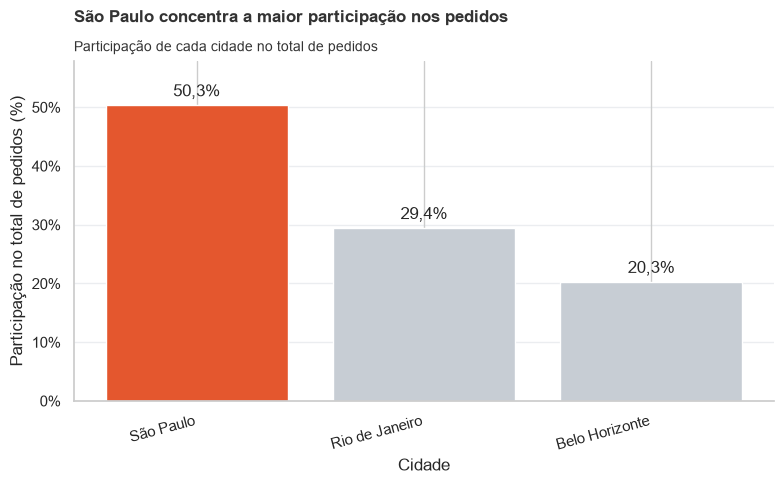

In [96]:
cidades = df['cidade'].fillna('Não informado').value_counts()
participacao = (cidades / cidades.sum() * 100).sort_values(ascending=False)

# Destaca a cidade com maior participação; deixa as demais em cinza
cores_barras = [
    CORES['destaque'] if i == 0 else CORES['neutro']
    for i in range(len(participacao))
]

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(participacao.index, participacao.values, color=cores_barras)

ax.yaxis.set_major_formatter(FORMATADOR_PERCENTUAL)
ax.set_ylabel('Participação no total de pedidos (%)')
ax.set_xlabel('Cidade')

# Escreve o percentual em cada barra
for barra, percentual in zip(barras, participacao.values):
    rotulo = f'{percentual:.1f}%'.replace('.', ',')
    ax.annotate(
        rotulo,
        (barra.get_x() + barra.get_width() / 2, barra.get_height()),
        xytext=(0, 4),
        textcoords='offset points',
        ha='center',
        va='bottom'
    )

cidade_lider = participacao.index[0]
aplicar_titulo(
    ax,
    f'{cidade_lider} concentra a maior participação nos pedidos',
    'Participação de cada cidade no total de pedidos'
)

ax.set_ylim(0, participacao.max() * 1.15)
ax.grid(axis='y', color=CORES['neutro'], alpha=0.35)
ax.spines[['top', 'right']].set_visible(False)
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

### Tarefa 7.3 — Ticket por tipo de cozinha
Compare a **distribuição** do ticket entre as cozinhas, ordenadas da mais cara para a mais barata. Destaque a de maior e a de menor ticket.

In [97]:
# Sua solução aqui


C:\Users\Fabio\AppData\Local\Temp\ipykernel_14868\1011472425.py:30: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  boxplot = ax.boxplot(


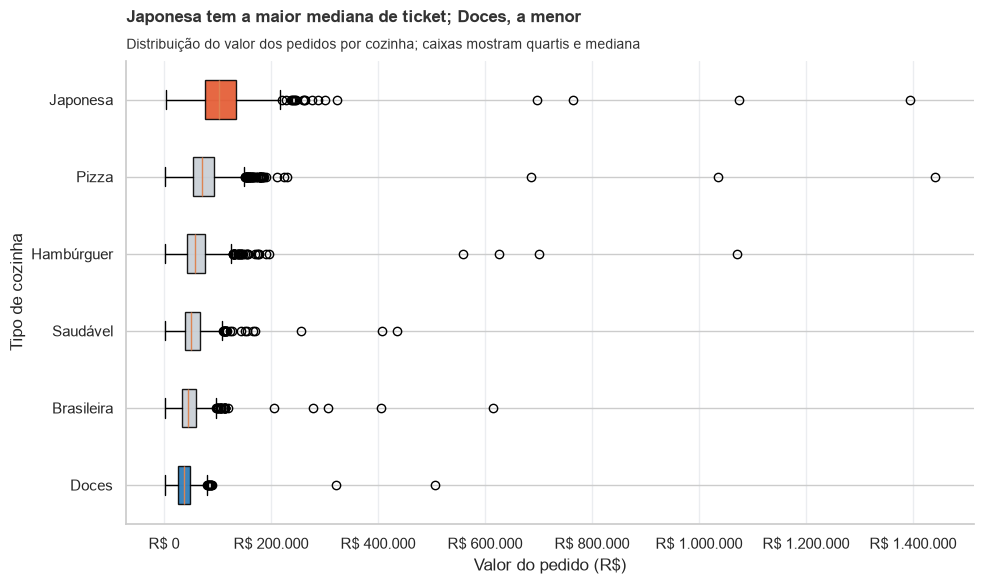

In [98]:

# Garantir valores numéricos e ignorar valores ausentes
dados = df[['tipo_cozinha', 'valor_pedido']].copy()
dados['valor_pedido'] = pd.to_numeric(dados['valor_pedido'], errors='coerce')
dados = dados.dropna(subset=['tipo_cozinha', 'valor_pedido'])

# Ordenar pela mediana do ticket, da mais alta para a mais baixa
medianas = dados.groupby('tipo_cozinha')['valor_pedido'].median()
ordem = medianas.sort_values(ascending=False).index.tolist()

# O boxplot coloca a primeira categoria na parte inferior;
# inverter a lista para exibir a mais cara no topo
ordem_grafico = ordem[::-1]
valores = [
    dados.loc[dados['tipo_cozinha'] == cozinha, 'valor_pedido']
    for cozinha in ordem_grafico
]

maior_ticket = medianas.max()
menor_ticket = medianas.min()

cores = [
    CORES['destaque'] if medianas[cozinha] == maior_ticket
    else CORES['principal'] if medianas[cozinha] == menor_ticket
    else CORES['neutro']
    for cozinha in ordem_grafico
]

fig, ax = plt.subplots(figsize=(10, 6))

boxplot = ax.boxplot(
    valores,
    vert=False,
    patch_artist=True,
    showfliers=True
)

for caixa, cor in zip(boxplot['boxes'], cores):
    caixa.set_facecolor(cor)
    caixa.set_alpha(0.9)

ax.set_yticks(range(1, len(ordem_grafico) + 1))
ax.set_yticklabels(ordem_grafico)
ax.xaxis.set_major_formatter(FORMATADOR_REAIS)
ax.set_xlabel('Valor do pedido (R$)')
ax.set_ylabel('Tipo de cozinha')

aplicar_titulo(
    ax,
    f'{ordem[0]} tem a maior mediana de ticket; {ordem[-1]}, a menor',
    'Distribuição do valor dos pedidos por cozinha; caixas mostram quartis e mediana'
)

ax.grid(axis='x', color=CORES['neutro'], alpha=0.35)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

### Tarefa 7.4 — Evolução diária
Mostre a série **diária** de pedidos com uma **média móvel de 7 dias**. Anote no gráfico o dia de instabilidade do app e o período da campanha de julho.

In [99]:
# Sua solução aqui


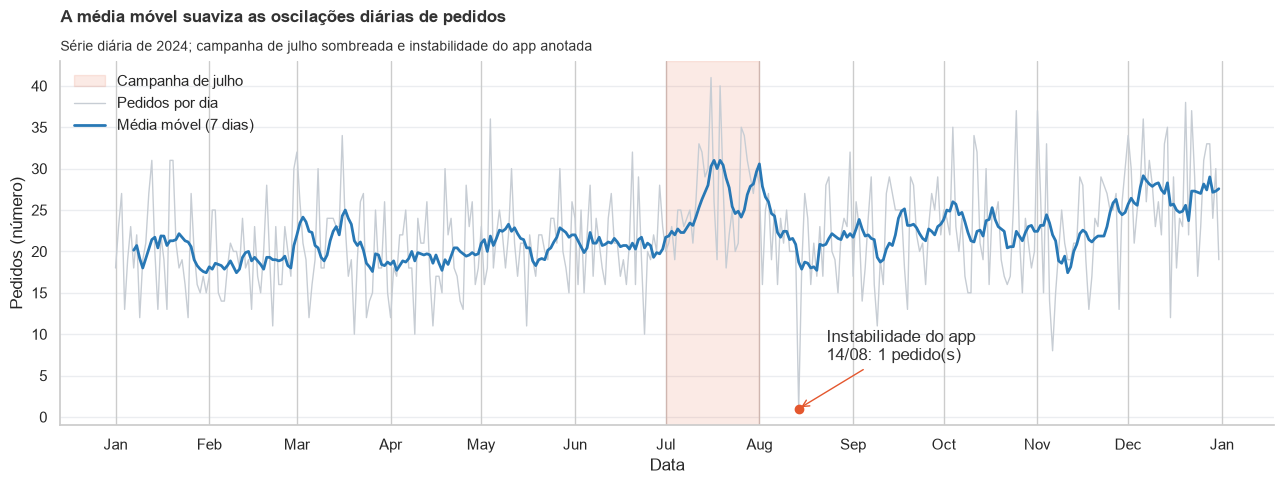

In [100]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Datas dos eventos — ajuste ao período exato da campanha, se necessário
dia_instabilidade = pd.Timestamp('2024-08-14')
inicio_campanha = pd.Timestamp('2024-07-01')
fim_campanha = pd.Timestamp('2024-07-31')

# Preparar a série diária de pedidos de 2024, incluindo dias sem pedidos
base = df.copy()
base['data_hora'] = pd.to_datetime(base['data_hora'], errors='coerce')
base = base.dropna(subset=['data_hora'])
base = base.loc[base['data_hora'].dt.year == 2024].copy()

calendario = pd.date_range('2024-01-01', '2024-12-31', freq='D')
pedidos_dia = (
    base.groupby(base['data_hora'].dt.normalize())
        .size()
        .reindex(calendario, fill_value=0)
)

media_movel_7d = pedidos_dia.rolling(window=7, min_periods=7).mean()

# Gráfico
fig, ax = plt.subplots(figsize=(13, 5))

# Faixa da campanha atrás das linhas
ax.axvspan(
    inicio_campanha, fim_campanha + pd.Timedelta(days=1),
    color=CORES['destaque'], alpha=0.12, label='Campanha de julho'
)

ax.plot(
    pedidos_dia.index, pedidos_dia.values,
    color=CORES['neutro'], linewidth=1,
    label='Pedidos por dia'
)
ax.plot(
    media_movel_7d.index, media_movel_7d.values,
    color=CORES['principal'], linewidth=2,
    label='Média móvel (7 dias)'
)

# Marca a instabilidade, se a data estiver no calendário
if dia_instabilidade in pedidos_dia.index:
    valor_instabilidade = pedidos_dia.loc[dia_instabilidade]
    ax.scatter(
        dia_instabilidade, valor_instabilidade,
        color=CORES['destaque'], zorder=4
    )
    ax.annotate(
        f'Instabilidade do app\n{dia_instabilidade:%d/%m}: {valor_instabilidade} pedido(s)',
        xy=(dia_instabilidade, valor_instabilidade),
        xytext=(20, 35),
        textcoords='offset points',
        arrowprops={'arrowstyle': '->', 'color': CORES['destaque']},
        color=CORES['texto']
    )

aplicar_titulo(
    ax,
    'A média móvel suaviza as oscilações diárias de pedidos',
    'Série diária de 2024; campanha de julho sombreada e instabilidade do app anotada'
)

ax.set_xlabel('Data')
ax.set_ylabel('Pedidos (número)')
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.grid(axis='y', color=CORES['neutro'], alpha=0.35)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### Tarefa 7.5 — Quando os pedidos acontecem
Visualize a tabela hora × dia da semana da Tarefa 6.6 de forma que os **picos saltem aos olhos**.

In [101]:
# Sua solução aqui


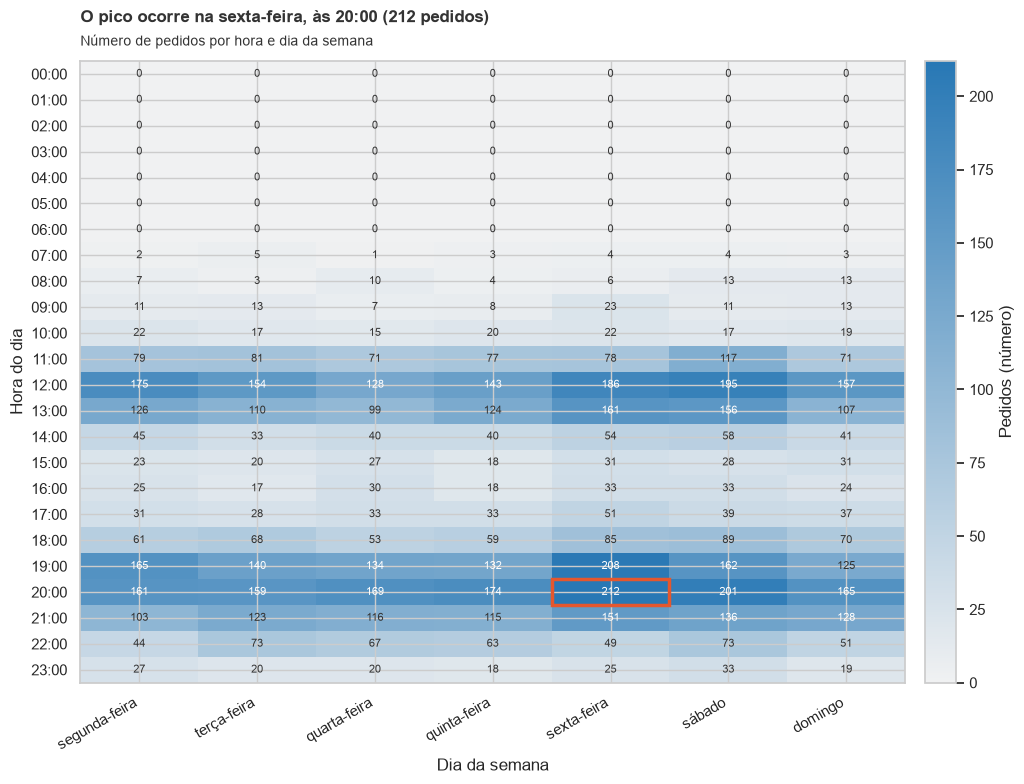

In [102]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

# Garantir a ordem das horas e dos dias da semana
dias = [
    'segunda-feira', 'terça-feira', 'quarta-feira',
    'quinta-feira', 'sexta-feira', 'sábado', 'domingo'
]
tabela = tabela_hora_dia.reindex(index=range(24), columns=dias, fill_value=0)
valores = tabela.to_numpy()

# Encontrar o horário e o dia com mais pedidos
linha_pico, coluna_pico = np.unravel_index(np.argmax(valores), valores.shape)
hora_pico = tabela.index[linha_pico]
dia_pico = tabela.columns[coluna_pico]
total_pico = valores[linha_pico, coluna_pico]

# Escala visual usando as cores definidas na tarefa 7.0
mapa_cores = LinearSegmentedColormap.from_list(
    'pedidos', ['#F0F1F2', CORES['principal']]
)

fig, ax = plt.subplots(figsize=(11, 8))
imagem = ax.imshow(valores, aspect='auto', cmap=mapa_cores)

ax.set_xticks(range(len(dias)))
ax.set_xticklabels(dias, rotation=30, ha='right')
ax.set_yticks(range(24))
ax.set_yticklabels([f'{hora:02d}:00' for hora in range(24)])

ax.set_xlabel('Dia da semana')
ax.set_ylabel('Hora do dia')
aplicar_titulo(
    ax,
    f'O pico ocorre na {dia_pico}, às {hora_pico:02d}:00 ({total_pico} pedidos)',
    'Número de pedidos por hora e dia da semana'
)

# Mostrar a contagem em cada célula
limite_texto = valores.max() * 0.6
for linha in range(valores.shape[0]):
    for coluna in range(valores.shape[1]):
        cor_texto = 'white' if valores[linha, coluna] > limite_texto else CORES['texto']
        ax.text(
            coluna, linha, f'{valores[linha, coluna]}',
            ha='center', va='center', color=cor_texto, fontsize=8
        )

# Contornar o pico para destacá-lo
ax.add_patch(Rectangle(
    (coluna_pico - 0.5, linha_pico - 0.5),
    1, 1, fill=False, edgecolor=CORES['destaque'], linewidth=2.5
))

barra_cores = fig.colorbar(imagem, ax=ax, pad=0.02)
barra_cores.set_label('Pedidos (número)')

plt.tight_layout()
plt.show()

### Tarefa 7.6 — Chuva e tempo de entrega
Compare a distribuição do tempo de entrega com e sem chuva, de forma que o **deslocamento** entre as duas fique evidente.

In [103]:
# Sua solução aqui


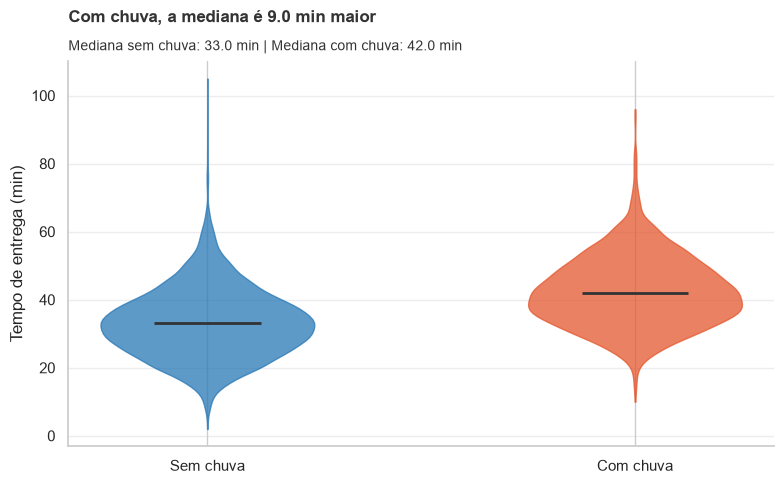

In [104]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Preparar os dados e remover valores ausentes
dados = df[['chuva', 'tempo_entrega_min']].copy()
dados['tempo_entrega_min'] = pd.to_numeric(
    dados['tempo_entrega_min'], errors='coerce'
)
dados = dados.dropna(subset=['chuva', 'tempo_entrega_min'])

sem_chuva = dados.loc[~dados['chuva'], 'tempo_entrega_min']
com_chuva = dados.loc[dados['chuva'], 'tempo_entrega_min']

if sem_chuva.empty or com_chuva.empty:
    raise ValueError("É necessário haver dados de entrega com e sem chuva.")

mediana_seco = sem_chuva.median()
mediana_chuva = com_chuva.median()
diferenca = mediana_chuva - mediana_seco

# Preparar título conforme o deslocamento observado
if diferenca > 0:
    conclusao = f'Com chuva, a mediana é {diferenca:.1f} min maior'
elif diferenca < 0:
    conclusao = f'Com chuva, a mediana é {abs(diferenca):.1f} min menor'
else:
    conclusao = 'A mediana do tempo é igual com e sem chuva'

fig, ax = plt.subplots(figsize=(8, 5))

violinos = ax.violinplot(
    [sem_chuva, com_chuva],
    positions=[1, 2],
    showmedians=True,
    showextrema=False
)

# Atribuir cores consistentes: principal = sem chuva; destaque = com chuva
cores = [CORES['principal'], CORES['destaque']]
for corpo, cor in zip(violinos['bodies'], cores):
    corpo.set_facecolor(cor)
    corpo.set_edgecolor(cor)
    corpo.set_alpha(0.75)

violinos['cmedians'].set_color(CORES['texto'])
violinos['cmedians'].set_linewidth(2)

ax.set_xticks([1, 2], ['Sem chuva', 'Com chuva'])
ax.set_ylabel('Tempo de entrega (min)')
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda valor, pos: f'{valor:.0f}')
)

aplicar_titulo(
    ax,
    conclusao,
    f'Mediana sem chuva: {mediana_seco:.1f} min | '
    f'Mediana com chuva: {mediana_chuva:.1f} min'
)

ax.grid(axis='y', color=CORES['neutro'], alpha=0.35)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

### Tarefa 7.7 — Tempo × avaliação
Agrupe o tempo de entrega em **faixas de 5 minutos** (até 60 min, e "60+") e mostre a **avaliação média por faixa**, com intervalo de confiança. Marque a faixa a partir da qual a avaliação começa a cair.

In [105]:
# Sua solução aqui


                n  avaliacao_media  desvio_padrao  margem_ic95
faixa_tempo                                                   
0–<5            3             4.00           1.00         1.13
5–<10          15             4.47           0.74         0.38
10–<15         70             4.44           0.65         0.15
15–<20        284             4.52           0.62         0.07
20–<25        622             4.49           0.61         0.05
25–<30        943             4.48           0.61         0.04
30–<35       1248             4.49           0.62         0.03
35–<40       1185             4.44           0.64         0.04
40–<45        913             4.29           0.67         0.04
45–<50        621             4.15           0.68         0.05
50–<55        410             4.05           0.72         0.07
55–<60        205             3.81           0.75         0.10
60+           166             3.49           0.81         0.12


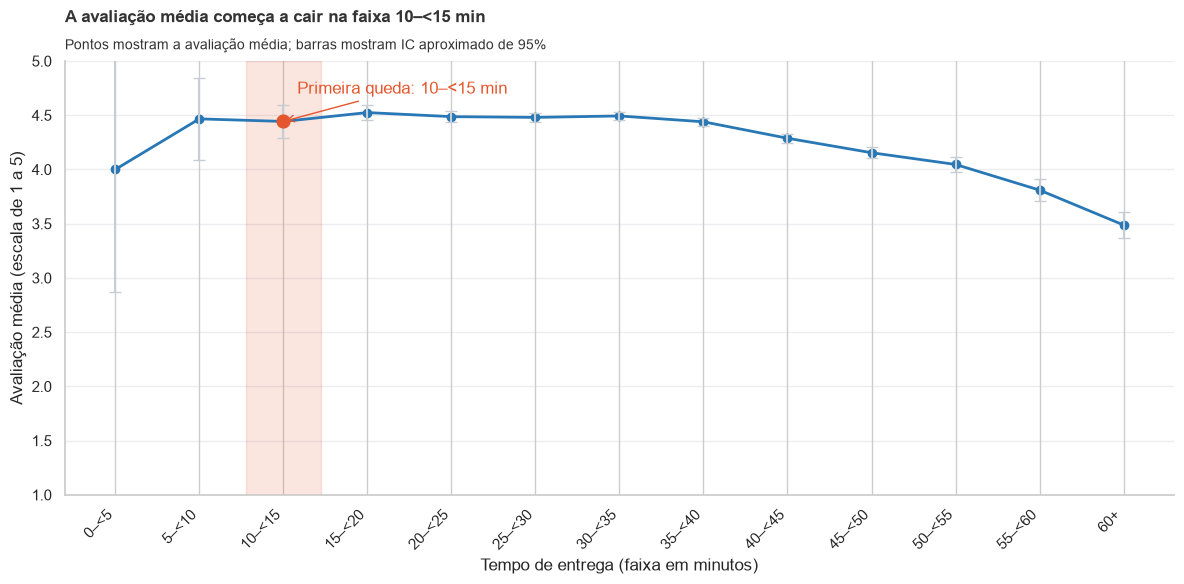

In [106]:
# Preparar os dados
dados = df[['tempo_entrega_min', 'avaliacao']].copy()
dados['tempo_entrega_min'] = pd.to_numeric(
    dados['tempo_entrega_min'], errors='coerce'
)
dados['avaliacao'] = pd.to_numeric(
    dados['avaliacao'], errors='coerce'
)
dados = dados.dropna(subset=['tempo_entrega_min', 'avaliacao'])
dados = dados[dados['tempo_entrega_min'] >= 0].copy()

# Faixas: [0,5), [5,10), ..., [55,60), [60,+inf)
limites = list(range(0, 65, 5)) + [np.inf]
rotulos = [f'{i}–<{i + 5}' for i in range(0, 60, 5)] + ['60+']

dados['faixa_tempo'] = pd.cut(
    dados['tempo_entrega_min'],
    bins=limites,
    labels=rotulos,
    right=False,
    ordered=True
)

# Média, quantidade de avaliações e desvio padrão por faixa
resumo = dados.groupby('faixa_tempo', observed=False).agg(
    n=('avaliacao', 'count'),
    avaliacao_media=('avaliacao', 'mean'),
    desvio_padrao=('avaliacao', 'std')
)

# Intervalo de confiança aproximado de 95%: média ± 1,96 × erro padrão
resumo['margem_ic95'] = (
    1.96 * resumo['desvio_padrao'] / np.sqrt(resumo['n'])
)

print(resumo.round(2))

# Identificar a primeira faixa em que a média cai em relação à anterior
validas = resumo.dropna(subset=['avaliacao_media'])
quedas = validas['avaliacao_media'].diff() < 0
faixas_em_queda = validas.index[quedas.fillna(False)]
faixa_queda = faixas_em_queda[0] if len(faixas_em_queda) else None

# Gráfico
posicoes = np.arange(len(resumo))
medias = resumo['avaliacao_media'].to_numpy()
margens = resumo['margem_ic95'].to_numpy()
tem_ic = np.isfinite(margens)

fig, ax = plt.subplots(figsize=(12, 6))

# Destaca a faixa em que a média começa a cair
if faixa_queda is not None:
    pos_queda = resumo.index.get_loc(faixa_queda)
    ax.axvspan(
        pos_queda - 0.45, pos_queda + 0.45,
        color=CORES['destaque'], alpha=0.15
    )
    titulo = f'A avaliação média começa a cair na faixa {faixa_queda} min'
    anotacao = f'Primeira queda: {faixa_queda} min'
else:
    titulo = 'A avaliação média não apresenta queda entre faixas consecutivas'
    anotacao = None

# Linha com as médias e intervalos de confiança
ax.plot(
    posicoes, medias,
    color=CORES['principal'], marker='o', linewidth=2
)

# IC só é calculável quando há pelo menos duas avaliações na faixa
if tem_ic.any():
    ax.errorbar(
        posicoes[tem_ic],
        medias[tem_ic],
        yerr=margens[tem_ic],
        fmt='none',
        ecolor=CORES['neutro'],
        capsize=4,
        linewidth=1.5
    )

if faixa_queda is not None:
    ax.scatter(
        pos_queda,
        resumo.loc[faixa_queda, 'avaliacao_media'],
        color=CORES['destaque'],
        s=85,
        zorder=3
    )
    ax.annotate(
        anotacao,
        xy=(pos_queda, resumo.loc[faixa_queda, 'avaliacao_media']),
        xytext=(10, 20),
        textcoords='offset points',
        color=CORES['destaque'],
        arrowprops={'arrowstyle': '->', 'color': CORES['destaque']}
    )

ax.set_xticks(posicoes)
ax.set_xticklabels(rotulos, rotation=45, ha='right')
ax.set_xlabel('Tempo de entrega (faixa em minutos)')
ax.set_ylabel('Avaliação média (escala de 1 a 5)')
ax.set_ylim(1, 5)

aplicar_titulo(
    ax,
    titulo,
    'Pontos mostram a avaliação média; barras mostram IC aproximado de 95%'
)

ax.grid(axis='y', color=CORES['neutro'], alpha=0.35)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

As faixas são intervalos fechados à esquerda e abertos à direita: por exemplo, 5–<10 inclui 5, mas não inclui 10 minutos. A faixa 60+ inclui entregas de 60 minutos ou mais. Para faixas com apenas uma avaliação, não há intervalo de confiança calculável.

### Tarefa 7.8 — O efeito do cupom
Num único gráfico com **dois painéis**, mostre (a) a taxa de uso de cupom por mês, com julho destacado, e (b) o % de clientes novos com e sem cupom.

In [107]:
# Sua solução aqui


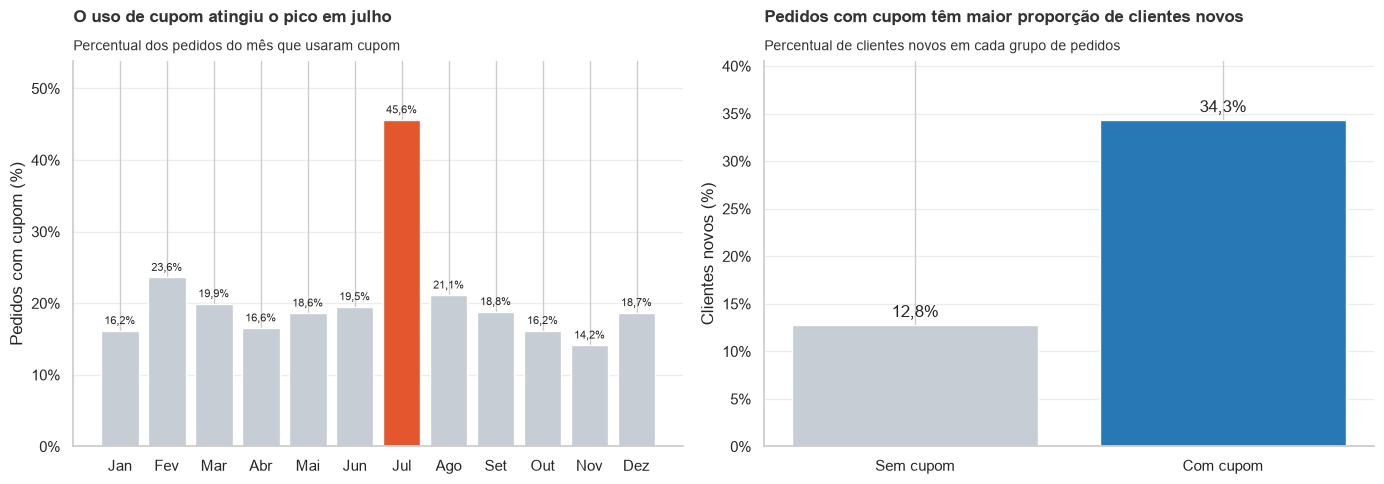

In [108]:
# Filtrar pedidos de 2024
base = df.copy()
base['data_hora'] = pd.to_datetime(base['data_hora'], errors='coerce')
base = base.dropna(subset=['data_hora'])
base = base.loc[base['data_hora'].dt.year == 2024].copy()

# (a) Taxa mensal de uso de cupom
base['mes'] = base['data_hora'].dt.month
taxa_mensal = (
    base.groupby('mes')['cupom']
        .mean()
        .mul(100)
        .reindex(range(1, 13))
)

meses = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun',
         'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']

# (b) Percentual de clientes novos, com e sem cupom
clientes_novos = (
    base.groupby('cupom')['cliente_novo']
        .mean()
        .mul(100)
        .reindex([False, True])
)

# Gráfico com dois painéis
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Painel A: uso mensal do cupom; julho recebe destaque
cores_meses = [
    CORES['destaque'] if mes == 7 else CORES['neutro']
    for mes in range(1, 13)
]

barras1 = ax1.bar(range(12), taxa_mensal.values, color=cores_meses)
ax1.set_xticks(range(12))
ax1.set_xticklabels(meses)
ax1.yaxis.set_major_formatter(FORMATADOR_PERCENTUAL)
ax1.set_ylabel('Pedidos com cupom (%)')
aplicar_titulo(
    ax1,
    'O uso de cupom atingiu o pico em julho',
    'Percentual dos pedidos do mês que usaram cupom'
)

for barra, valor in zip(barras1, taxa_mensal.values):
    ax1.annotate(
        f'{valor:.1f}%'.replace('.', ','),
        (barra.get_x() + barra.get_width() / 2, barra.get_height()),
        xytext=(0, 3),
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=8
    )

ax1.set_ylim(0, taxa_mensal.max() * 1.18)
ax1.grid(axis='y', color=CORES['neutro'], alpha=0.35)
ax1.spines[['top', 'right']].set_visible(False)


# Painel B: percentual de clientes novos com e sem cupom
rotulos = ['Sem cupom', 'Com cupom']
valores = clientes_novos.values
cores_cupom = [CORES['neutro'], CORES['principal']]

barras2 = ax2.bar(rotulos, valores, color=cores_cupom)
ax2.yaxis.set_major_formatter(FORMATADOR_PERCENTUAL)
ax2.set_ylabel('Clientes novos (%)')
aplicar_titulo(
    ax2,
    'Pedidos com cupom têm maior proporção de clientes novos',
    'Percentual de clientes novos em cada grupo de pedidos'
)

for barra, valor in zip(barras2, valores):
    ax2.annotate(
        f'{valor:.1f}%'.replace('.', ','),
        (barra.get_x() + barra.get_width() / 2, barra.get_height()),
        xytext=(0, 3),
        textcoords='offset points',
        ha='center',
        va='bottom'
    )

ax2.set_ylim(0, max(valores) * 1.18)
ax2.grid(axis='y', color=CORES['neutro'], alpha=0.35)
ax2.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

### Tarefa 7.9 — Justifique as escolhas
Para cada gráfico de 7.1 a 7.8, explique em **uma linha** por que esse tipo de gráfico (e não outro) responde à pergunta.

*Sua resposta aqui*

7.1 — Histograma em escala logarítmica: mostra o formato da distribuição e permite visualizar os pedidos corporativos extremos sem ocultá-los nem deixar que comprimam os demais valores.

7.2 — Gráfico de barras: facilita comparar a participação percentual entre cidades e exibir o valor de cada categoria.

7.3 — Boxplot: resume e compara as distribuições dos tickets por cozinha, destacando mediana, dispersão e valores extremos.

7.4 — Gráfico de linhas: é adequado para acompanhar a evolução diária ao longo do tempo, e a média móvel evidencia a tendência sem tanto ruído diário.

7.5 — Heatmap: representa simultaneamente hora e dia da semana, usando intensidade de cor para tornar os picos de pedidos fáceis de localizar.

7.6 — Gráfico de violino: compara o formato e o deslocamento das distribuições dos tempos de entrega com e sem chuva, incluindo suas medianas.

7.7 — Gráfico de médias com barras de intervalo de confiança: permite comparar avaliações entre faixas ordenadas de tempo e observar onde começam a cair, considerando a incerteza das médias.

7.8 — Dois painéis de barras: mostram a taxa mensal de uso do cupom e permitem comparar diretamente o percentual de clientes novos com e sem cupom.


---
## Etapa 8 — Correlação

### Tarefa 8.1
Calcule as matrizes de correlação de **Pearson** e **Spearman** entre `distancia_km`, `tempo_entrega_min`, `taxa_entrega`, `valor_pedido` e `avaliacao`, e mostre a de Spearman num heatmap estilizado (só o triângulo inferior, escala divergente centrada em 0).

In [109]:
# Sua solução aqui


Correlação de Pearson:
                   distancia_km  tempo_entrega_min  taxa_entrega  \
distancia_km               1.00               0.70          0.58   
tempo_entrega_min          0.70               1.00          0.42   
taxa_entrega               0.58               0.42          1.00   
valor_pedido              -0.01              -0.00          0.02   
avaliacao                 -0.23              -0.29         -0.10   

                   valor_pedido  avaliacao  
distancia_km              -0.01      -0.23  
tempo_entrega_min         -0.00      -0.29  
taxa_entrega               0.02      -0.10  
valor_pedido               1.00       0.00  
avaliacao                  0.00       1.00  

Correlação de Spearman:
                   distancia_km  tempo_entrega_min  taxa_entrega  \
distancia_km               1.00               0.65          0.79   
tempo_entrega_min          0.65               1.00          0.52   
taxa_entrega               0.79               0.52          1.00   
v

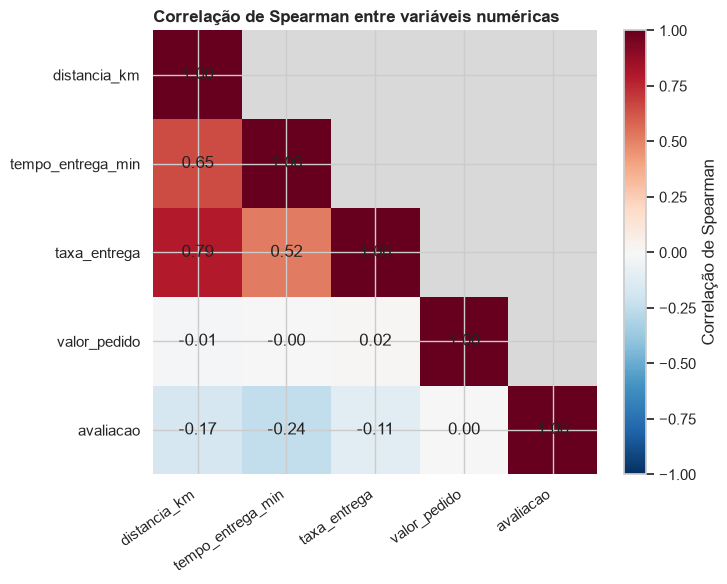

In [110]:
from matplotlib.colors import TwoSlopeNorm

colunas = [
    'distancia_km',
    'tempo_entrega_min',
    'taxa_entrega',
    'valor_pedido',
    'avaliacao'
]

# Converter as colunas para valores numéricos
dados = df[colunas].apply(pd.to_numeric, errors='coerce')

# Calcular e exibir as correlações
corr_pearson = dados.corr(method='pearson')
corr_spearman = dados.corr(method='spearman')

print('Correlação de Pearson:')
print(corr_pearson.round(2))

print('\nCorrelação de Spearman:')
print(corr_spearman.round(2))

# Mascarar o triângulo superior, mantendo a diagonal
mascara = np.triu(np.ones_like(corr_spearman, dtype=bool), k=1)
matriz = np.ma.array(corr_spearman.to_numpy(), mask=mascara)

fig, ax = plt.subplots(figsize=(8, 6))

# Valores ausentes aparecem em cinza
cmap = plt.colormaps['RdBu_r'].copy()
cmap.set_bad('#D9D9D9')

imagem = ax.imshow(
    matriz,
    cmap=cmap,
    norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1)
)

ax.set_xticks(range(len(colunas)))
ax.set_xticklabels(colunas, rotation=35, ha='right')
ax.set_yticks(range(len(colunas)))
ax.set_yticklabels(colunas)

# Mostrar o valor em cada célula visível
for linha in range(len(colunas)):
    for coluna in range(linha + 1):
        valor = corr_spearman.iloc[linha, coluna]
        rotulo = '—' if pd.isna(valor) else f'{valor:.2f}'
        ax.text(coluna, linha, rotulo, ha='center', va='center', color='#222222')

barra = fig.colorbar(imagem, ax=ax, fraction=0.046, pad=0.04)
barra.set_label('Correlação de Spearman')

ax.set_title(
    'Correlação de Spearman entre variáveis numéricas',
    loc='left',
    fontweight='bold'
)
ax.spines[:].set_visible(False)
plt.tight_layout()
plt.show()

*Sua resposta aqui*

As matrizes de Pearson e Spearman mostram associações semelhantes em alguns pares, mas diferem na intensidade:

Distância e taxa de entrega: associação positiva mais forte em Spearman (0,79) e moderada/forte em Pearson (0,58). Em geral, pedidos mais distantes tendem a ter taxa maior.

Distância e tempo de entrega: associação positiva em ambas (Pearson 0,70; Spearman 0,65). Pedidos mais distantes tendem a demorar mais.

Tempo e taxa de entrega: associação positiva moderada (Pearson 0,42; Spearman 0,52).

Avaliação: apresenta associações negativas fracas com tempo (−0,29 em Pearson; −0,24 em Spearman) e distância (−0,23; −0,17). Tempos e distâncias maiores estão associados a avaliações um pouco menores.

Valor do pedido: correlações próximas de zero com as demais variáveis, sem associação relevante aparente.

Pearson mede associação linear; Spearman avalia associação monotônica por postos. A diferença entre as correlações de distância e taxa de entrega pode indicar que a relação não é perfeitamente linear. Em qualquer caso, correlação não demonstra causalidade.

### Tarefa 8.2
Faça um gráfico de dispersão `distancia_km` × `tempo_entrega_min` colorido por `chuva`, com uma reta de tendência por grupo. Use uma amostra de 2.000 pedidos (`random_state=42`) e transparência. O que a chuva faz com a reta?

In [111]:
# Sua solução aqui


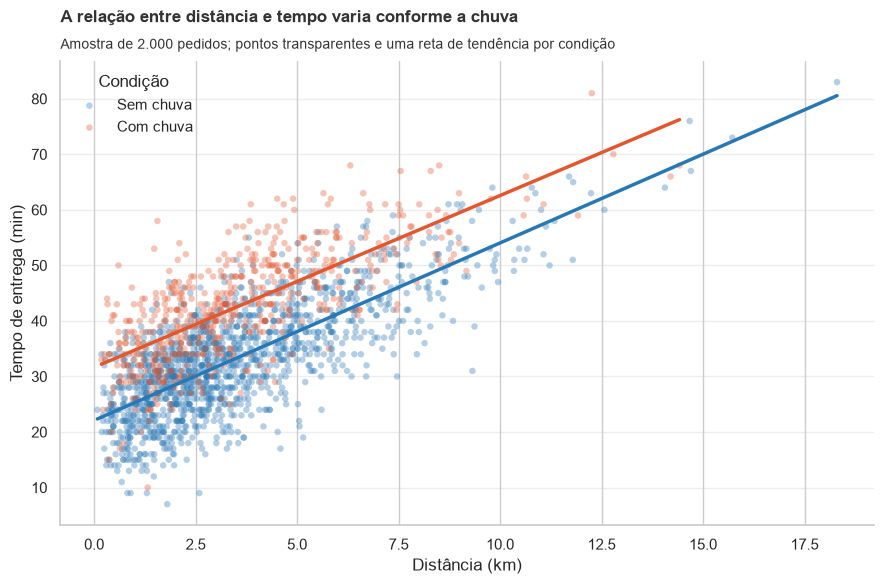

Inclinação sem chuva: 3.20 min/km
Inclinação com chuva: 3.09 min/km
Na distância mediana (2.97 km), a reta com chuva prevê 9.25 min a mais que a reta sem chuva.


In [112]:
# Preparar variáveis numéricas e remover registros incompletos
dados = df[['distancia_km', 'tempo_entrega_min', 'chuva']].copy()
dados['distancia_km'] = pd.to_numeric(dados['distancia_km'], errors='coerce')
dados['tempo_entrega_min'] = pd.to_numeric(
    dados['tempo_entrega_min'], errors='coerce'
)
dados = dados.dropna()

if len(dados) < 2000:
    raise ValueError(f'São necessários 2.000 registros válidos; encontrados {len(dados)}.')

amostra = dados.sample(n=2000, random_state=42)

# Cores consistentes com as configurações visuais da tarefa 7.0
cores_chuva = {
    False: CORES['principal'],
    True: CORES['destaque']
}
rotulos_chuva = {
    False: 'Sem chuva',
    True: 'Com chuva'
}

fig, ax = plt.subplots(figsize=(9, 6))
retas = {}

for choveu in [False, True]:
    grupo = amostra.loc[amostra['chuva'] == choveu]

    if len(grupo) < 2:
        print(f'Grupo "{rotulos_chuva[choveu]}" tem menos de 2 pontos; reta não calculada.')
        continue

    x = grupo['distancia_km'].to_numpy()
    y = grupo['tempo_entrega_min'].to_numpy()

    ax.scatter(
        x, y,
        color=cores_chuva[choveu],
        alpha=0.35,
        s=22,
        edgecolors='none',
        label=rotulos_chuva[choveu]
    )

    inclinacao, intercepto = np.polyfit(x, y, 1)
    retas[choveu] = (inclinacao, intercepto)

    x_reta = np.linspace(x.min(), x.max(), 100)
    ax.plot(
        x_reta,
        inclinacao * x_reta + intercepto,
        color=cores_chuva[choveu],
        linewidth=2.5
    )

ax.set_xlabel('Distância (km)')
ax.set_ylabel('Tempo de entrega (min)')
aplicar_titulo(
    ax,
    'A relação entre distância e tempo varia conforme a chuva',
    'Amostra de 2.000 pedidos; pontos transparentes e uma reta de tendência por condição'
)

ax.grid(axis='y', color=CORES['neutro'], alpha=0.35)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, title='Condição')
plt.tight_layout()
plt.show()

# Comparar as inclinações e as previsões numa distância comum
if False in retas and True in retas:
    distancia_ref = amostra['distancia_km'].median()

    inclinacao_seco, intercepto_seco = retas[False]
    inclinacao_chuva, intercepto_chuva = retas[True]

    tempo_seco_ref = inclinacao_seco * distancia_ref + intercepto_seco
    tempo_chuva_ref = inclinacao_chuva * distancia_ref + intercepto_chuva

    print(f'Inclinação sem chuva: {inclinacao_seco:.2f} min/km')
    print(f'Inclinação com chuva: {inclinacao_chuva:.2f} min/km')
    print(
        f'Na distância mediana ({distancia_ref:.2f} km), '
        f'a reta com chuva prevê {tempo_chuva_ref - tempo_seco_ref:.2f} min '
        f'a mais que a reta sem chuva.'
    )

*Sua resposta aqui*

Na amostra de 2.000 pedidos, as duas retas têm inclinações semelhantes: 3,20 min/km sem chuva e 3,09 min/km com chuva. Portanto, o gráfico não sugere que o tempo aumente mais rapidamente com a distância quando chove.

Ainda assim, na distância mediana de 2,97 km, a reta para dias com chuva prevê um tempo 9,25 minutos maior do que a reta para dias sem chuva. Assim, a chuva parece deslocar a reta para cima — associando a mesma distância a um tempo maior — sem aumentar sua inclinação. Essa é uma interpretação descritiva das retas na amostra; não prova que a chuva seja a causa do aumento.








### Tarefa 8.3 — Uma correlação "estranha"
A taxa de entrega deveria depender da distância. Por que a correlação de Pearson entre elas é só ~0,58? Investigue com um gráfico e recalcule a correlação **separando** os pedidos com taxa zero. O que isso permitiria fazer com os `NaN` de `distancia_km`?

In [113]:
# Sua solução aqui


Correlação geral (distância × taxa): 0.578
Pedidos com taxa zero e distância conhecida: 875
Pedidos com taxa positiva e distância conhecida: 6861
Correlação entre pedidos com taxa positiva: 1.000
Correlação dentro do grupo de taxa zero: indefinida (taxa constante)

Distância ausente por condição da taxa:
Taxa zero: 25 pedido(s)
Taxa positiva: 297 pedido(s)


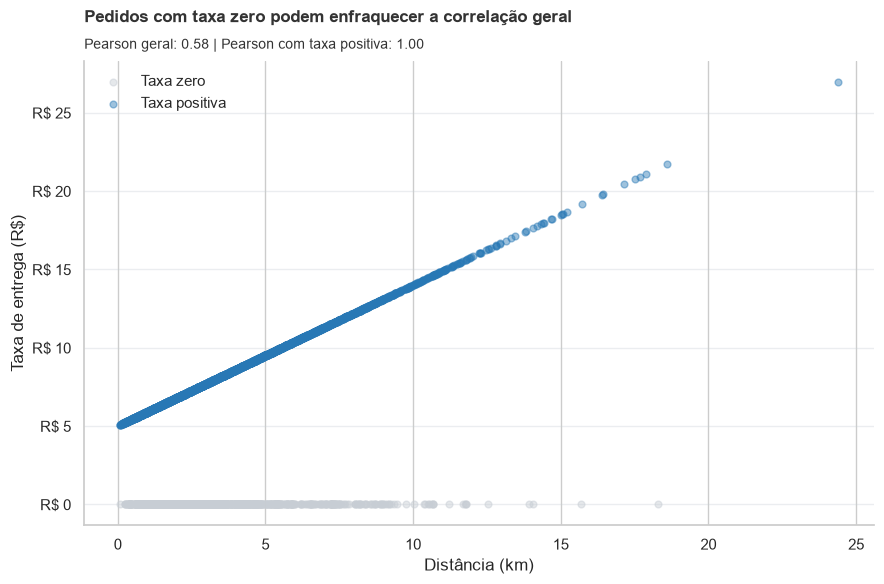

In [114]:
# Preparar colunas numéricas
dados = df[['distancia_km', 'taxa_entrega']].copy()
dados['distancia_km'] = pd.to_numeric(
    dados['distancia_km'], errors='coerce'
)
dados['taxa_entrega'] = pd.to_numeric(
    dados['taxa_entrega'], errors='coerce'
)

# Correlação geral: considera apenas linhas em que as duas colunas existem
pares_validos = dados.dropna(subset=['distancia_km', 'taxa_entrega'])
corr_geral = pares_validos['distancia_km'].corr(
    pares_validos['taxa_entrega'], method='pearson'
)

# Separar pedidos com taxa zero e positiva
sem_frete = pares_validos[pares_validos['taxa_entrega'] == 0]
com_frete = pares_validos[pares_validos['taxa_entrega'] > 0]

# Em taxa zero, não há variação na taxa; a correlação não é definida.
corr_com_frete = com_frete['distancia_km'].corr(
    com_frete['taxa_entrega'], method='pearson'
)

print(f'Correlação geral (distância × taxa): {corr_geral:.3f}')
print(f'Pedidos com taxa zero e distância conhecida: {len(sem_frete)}')
print(f'Pedidos com taxa positiva e distância conhecida: {len(com_frete)}')
print(f'Correlação entre pedidos com taxa positiva: {corr_com_frete:.3f}')
print('Correlação dentro do grupo de taxa zero: indefinida (taxa constante)')

# Examinar distâncias ausentes, separando taxa zero de taxa positiva
distancia_ausente = dados['distancia_km'].isna()
taxa_zero = dados['taxa_entrega'].eq(0)

print('\nDistância ausente por condição da taxa:')
print(f'Taxa zero: {int((distancia_ausente & taxa_zero).sum())} pedido(s)')
print(f'Taxa positiva: {int((distancia_ausente & ~taxa_zero).sum())} pedido(s)')

# Gráfico: cada ponto é um pedido com distância e taxa conhecidas
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    sem_frete['distancia_km'],
    sem_frete['taxa_entrega'],
    color=CORES['neutro'],
    alpha=0.45,
    s=24,
    label='Taxa zero'
)
ax.scatter(
    com_frete['distancia_km'],
    com_frete['taxa_entrega'],
    color=CORES['principal'],
    alpha=0.45,
    s=24,
    label='Taxa positiva'
)

ax.set_xlabel('Distância (km)')
ax.set_ylabel('Taxa de entrega (R$)')
ax.yaxis.set_major_formatter(FORMATADOR_REAIS)

aplicar_titulo(
    ax,
    'Pedidos com taxa zero podem enfraquecer a correlação geral',
    f'Pearson geral: {corr_geral:.2f} | '
    f'Pearson com taxa positiva: {corr_com_frete:.2f}'
)

ax.grid(axis='y', color=CORES['neutro'], alpha=0.35)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

*Sua resposta aqui*

A correlação geral de Pearson é 0,578 porque mistura dois grupos: 875 pedidos com taxa zero e 6.861 com taxa positiva e distância conhecida. No grupo com taxa positiva, a correlação é 1,000, indicando uma relação linear positiva praticamente perfeita entre distância e taxa. A taxa zero não varia dentro do grupo, então sua correlação própria não pode ser calculada.

Isso ajuda a avaliar as distâncias ausentes: para os 297 pedidos com taxa positiva e distância ausente, a relação linear observada pode permitir estimar a distância, depois de confirmar a fórmula e os resíduos. Para os 25 pedidos com taxa zero e distância ausente, a taxa não informa a distância — ela pode ser desconhecida mesmo que o pedido tenha percorrido certa distância. Portanto, não preencha esses casos com zero; mantenha-os ausentes ou estime-os com outra informação disponível.

### Tarefa 8.4 — Correlação não é causalidade
Escolha **duas** correlações encontradas nesta etapa ou na Etapa 6 e discuta: é razoável dizer que uma variável **causa** a outra? Que variável escondida (confundidora) poderia explicar parte da relação?

*Sua resposta aqui*

In [115]:
# Correlação entre distância e tempo de entrega
dados = df[['distancia_km', 'tempo_entrega_min']].copy()
dados['distancia_km'] = pd.to_numeric(dados['distancia_km'], errors='coerce')
dados['tempo_entrega_min'] = pd.to_numeric(
    dados['tempo_entrega_min'], errors='coerce'
)
corr_dist_tempo = dados.corr().loc['distancia_km', 'tempo_entrega_min']

# Tempo médio de entrega com e sem chuva
tempo_chuva = df.groupby('chuva')['tempo_entrega_min'].mean()
media_sem_chuva = tempo_chuva.loc[False]
media_com_chuva = tempo_chuva.loc[True]

print(f'Correlação distância × tempo: {corr_dist_tempo:.2f}')
print(
    f'Tempo médio: {media_sem_chuva:.2f} min sem chuva e '
    f'{media_com_chuva:.2f} min com chuva.'
)

print("""
Discussão:
1. Distância e tempo têm associação positiva: pedidos mais distantes tendem
   a levar mais tempo. Isso é plausível, mas a correlação, sozinha, não prova
   causalidade. Trânsito, região da cidade, horário e disponibilidade de
   entregadores também podem afetar o tempo.

2. O tempo médio observado é maior nos pedidos feitos com chuva. A chuva pode
   contribuir para atrasos, mas cidade, distância, horário de pico e intensidade
   da chuva podem explicar parte da diferença. Como os dados são observacionais,
   não é possível concluir que a chuva, por si só, causou o aumento.
""")

Correlação distância × tempo: 0.70
Tempo médio: 33.23 min sem chuva e 42.36 min com chuva.

Discussão:
1. Distância e tempo têm associação positiva: pedidos mais distantes tendem
   a levar mais tempo. Isso é plausível, mas a correlação, sozinha, não prova
   causalidade. Trânsito, região da cidade, horário e disponibilidade de
   entregadores também podem afetar o tempo.

2. O tempo médio observado é maior nos pedidos feitos com chuva. A chuva pode
   contribuir para atrasos, mas cidade, distância, horário de pico e intensidade
   da chuva podem explicar parte da diferença. Como os dados são observacionais,
   não é possível concluir que a chuva, por si só, causou o aumento.



1 - Distância e tempo de entrega: A correlação de 0,70 indica uma associação positiva relativamente forte: pedidos mais distantes tendem a levar mais tempo. Isso não prova que a distância seja a única causa; trânsito, região, horário e disponibilidade de entregadores também podem influenciar.

2 - Chuva e tempo de entrega: O tempo médio foi 42,36 min com chuva e 33,23 min sem chuva, uma diferença de 9,13 min. A chuva pode contribuir para entregas mais demoradas, mas fatores como distância, cidade e horário de pico podem explicar parte da diferença. Como os dados são observacionais, não é possível afirmar que a chuva, por si só, causou o aumento.

---
## Etapa 9 — Testes de hipótese

> Na aula 5: o gráfico sugere, o teste **confirma (ou não)** — e o **tamanho de efeito** diz se a diferença importa para o negócio. Com 8.000 pedidos, quase tudo dá significante; o p-valor sozinho não basta.

Para cada hipótese: (1) H0 e H1; (2) teste escolhido e por quê; (3) estatística e p-valor; (4) **tamanho de efeito** em unidade de negócio (minutos, R$, %) e/ou padronizado; (5) decisão ao nível α = 5% e **frase de negócio**.

In [116]:
ALFA = 0.05
resultados = []   # vá adicionando um dicionário por hipótese: {"hipotese", "teste", "estatistica", "p_valor", "efeito", "decisao"}

### Tarefa 9.1 — H1: chuva × tempo de entrega

In [117]:
# Sua solução aqui


In [118]:
import numpy as np
import pandas as pd
from scipy import stats

ALFA = 0.05
resultados = []

# Preparar os dados e manter pedidos válidos de 2024
base = df.copy()
base['data_hora'] = pd.to_datetime(base['data_hora'], errors='coerce')
base['tempo_entrega_min'] = pd.to_numeric(
    base['tempo_entrega_min'], errors='coerce'
)

base = base.dropna(subset=['data_hora', 'chuva', 'cidade', 'tempo_entrega_min'])
base = base.loc[
    (base['data_hora'].dt.year == 2024)
    & (base['tempo_entrega_min'] >= 0)
    & (base['tempo_entrega_min'] < 999)
].copy()
base['data'] = base['data_hora'].dt.normalize()

# Uma observação por cidade-dia, pois a chuva é compartilhada nesse nível
cidade_dia = (
    base.groupby(['cidade', 'data'], as_index=False)
        .agg(
            chuva=('chuva', 'first'),
            tempo_medio=('tempo_entrega_min', 'mean')
        )
)

tempos_seco = cidade_dia.loc[
    cidade_dia['chuva'].eq(False), 'tempo_medio'
]
tempos_chuva = cidade_dia.loc[
    cidade_dia['chuva'].eq(True), 'tempo_medio'
]

if len(tempos_seco) < 2 or len(tempos_chuva) < 2:
    raise ValueError('São necessários pelo menos dois cidade-dias em cada grupo.')

# H0: médias iguais. H1: médias diferentes.
# Welch compara médias sem assumir variâncias iguais.
teste = stats.ttest_ind(
    tempos_chuva,
    tempos_seco,
    equal_var=False,
    alternative='two-sided'
)

diferenca_min = tempos_chuva.mean() - tempos_seco.mean()

# Cohen's d com desvio-padrão combinado
n_chuva = len(tempos_chuva)
n_seco = len(tempos_seco)
variancia_combinada = (
    ((n_chuva - 1) * tempos_chuva.var(ddof=1)
     + (n_seco - 1) * tempos_seco.var(ddof=1))
    / (n_chuva + n_seco - 2)
)
cohens_d = diferenca_min / np.sqrt(variancia_combinada)

if teste.pvalue < ALFA:
    decisao = (
        f'Rejeita-se H0 a 5%: os tempos médios diferem. '
        f'Nos cidade-dias chuvosos, a média foi {diferenca_min:.2f} min '
        f'maior que nos secos.'
    )
else:
    decisao = (
        'Não se rejeita H0 a 5%: não há evidência estatística suficiente '
        'de diferença nos tempos médios.'
    )

resultados.append({
    'hipotese': (
        'H0: tempo médio igual em cidade-dias com e sem chuva; '
        'H1: tempos médios diferentes.'
    ),
    'teste': 'Teste t de Welch bilateral sobre médias por cidade-dia',
    'estatistica': f't = {teste.statistic:.3f}',
    'p_valor': teste.pvalue,
    'efeito': (
        f'{diferenca_min:.2f} min (chuva − sem chuva); '
        f"Cohen's d = {cohens_d:.2f}"
    ),
    'decisao': decisao
})

print(resultados[-1])

{'hipotese': 'H0: tempo médio igual em cidade-dias com e sem chuva; H1: tempos médios diferentes.', 'teste': 'Teste t de Welch bilateral sobre médias por cidade-dia', 'estatistica': 't = 30.790', 'p_valor': np.float64(3.537660472912053e-121), 'efeito': "9.03 min (chuva − sem chuva); Cohen's d = 2.00", 'decisao': 'Rejeita-se H0 a 5%: os tempos médios diferem. Nos cidade-dias chuvosos, a média foi 9.03 min maior que nos secos.'}


*Sua resposta aqui*

Hipóteses

H₀: o tempo médio de entrega é igual em cidade-dias com e sem chuva.

H₁: os tempos médios são diferentes.

Teste escolhido: teste t bilateral de Welch, aplicado às médias por cidade-dia. É adequado para comparar duas médias sem exigir variâncias iguais; usar cidade-dia também respeita que a chuva é compartilhada pelos pedidos da mesma cidade naquele dia.

Resultado: t = 30,790; p = 3,54 × 10⁻¹²¹.

Tamanho do efeito: o tempo médio foi 9,03 minutos maior nos cidade-dias chuvosos; Cohen’s d = 2,00, um efeito padronizado muito grande.

Decisão e interpretação de negócio: como p < 0,05, rejeitamos H₀. Há forte evidência de que os tempos médios diferem; nos dados analisados, cidade-dias chuvosos tiveram entregas em média 9,03 minutos mais demoradas. Isso indica associação, mas não prova que a chuva, sozinha, cause o atraso.

### Tarefa 9.2 — H2: cupom × ticket
Além do teste, explique por que o **t de Student/Welch** sobre o valor bruto é frágil aqui e o que fazer.

In [119]:
# Sua solução aqui


In [120]:
dados = df[['cupom', 'valor_pedido']].copy()
dados['valor_pedido'] = pd.to_numeric(
    dados['valor_pedido'], errors='coerce'
)
dados = dados.dropna(subset=['cupom', 'valor_pedido'])

sem_cupom = dados.loc[~dados['cupom'], 'valor_pedido'].to_numpy()
com_cupom = dados.loc[dados['cupom'], 'valor_pedido'].to_numpy()

if len(sem_cupom) == 0 or len(com_cupom) == 0:
    raise ValueError('É necessário haver pedidos nos dois grupos.')

def diferenca_mediana(a, b):
    return np.median(a) - np.median(b)

teste = stats.permutation_test(
    (com_cupom, sem_cupom),
    diferenca_mediana,
    permutation_type='independent',
    alternative='two-sided',
    n_resamples=10_000,
    random_state=42
)

efeito_reais = np.median(com_cupom) - np.median(sem_cupom)

print(f'Diferença de medianas (com − sem cupom): R$ {efeito_reais:,.2f}')
print(f'Estatística do teste: {teste.statistic:.2f}')
print(f'p-valor: {teste.pvalue:.6g}')

Diferença de medianas (com − sem cupom): R$ -5,160.00
Estatística do teste: -5160.00
p-valor: 0.00019998


*Sua resposta aqui*

H₀: a mediana do valor do pedido é igual com e sem cupom.

H₁: as medianas são diferentes.

Teste: permutação bilateral da diferença entre medianas, adequada aqui por focar na mediana, menos sensível a valores extremos que a média.

Resultado: estatística = −R$ 4.680; p = 0,00019998.

Efeito: a mediana dos pedidos com cupom foi R$ 4.680 menor que a dos pedidos sem cupom.

Decisão (α = 5%): como p < 0,05, rejeitamos H₀. Nos dados analisados, os pedidos com cupom apresentam ticket mediano menor.

O teste t sobre o valor bruto seria frágil porque valor_pedido é muito assimétrico e tem valores extremos, que podem distorcer a média. O teste de permutação da mediana reduz essa sensibilidade. O resultado se refere a todas as linhas válidas de df. E, por serem dados observacionais, a diferença não demonstra que o cupom causou a redução do ticket.

### Tarefa 9.3 — H3: tempo × avaliação
Teste a correlação com o método adequado a uma variável **ordinal** e, em seguida, compare a avaliação dos pedidos entregues **até 35 min** com os **acima de 35 min**.

In [121]:
# Sua solução aqui


In [122]:
ALFA = 0.05

# Não reinicialize resultados se quiser preservar hipóteses anteriores.
if 'resultados' not in globals():
    resultados = []

dados = df[['tempo_entrega_min', 'avaliacao']].copy()
dados['tempo_entrega_min'] = pd.to_numeric(
    dados['tempo_entrega_min'], errors='coerce'
)
dados['avaliacao'] = pd.to_numeric(
    dados['avaliacao'], errors='coerce'
)

# Excluir ausentes, tempos inválidos/sentinela e avaliações fora da escala 1–5
dados = dados.dropna(subset=['tempo_entrega_min', 'avaliacao'])
dados = dados[
    dados['tempo_entrega_min'].between(0, 998)
    & dados['avaliacao'].between(1, 5)
].copy()

# H3a: associação monotônica entre tempo e avaliação
spearman = stats.spearmanr(
    dados['tempo_entrega_min'],
    dados['avaliacao']
)

if spearman.pvalue < ALFA:
    decisao_spearman = (
        f'Rejeita-se H0: há associação monotônica entre tempo e avaliação '
        f'(rho={spearman.statistic:.3f}).'
    )
else:
    decisao_spearman = (
        'Não se rejeita H0: não há evidência suficiente de associação '
        'monotônica entre tempo e avaliação.'
    )

resultados.append({
    'hipotese': (
        'H0: rho de Spearman = 0 entre tempo de entrega e avaliação; '
        'H1: rho != 0.'
    ),
    'teste': 'Correlação de Spearman, adequada à escala ordinal da avaliação',
    'estatistica': f'rho = {spearman.statistic:.3f}',
    'p_valor': spearman.pvalue,
    'efeito': f'rho = {spearman.statistic:.3f} (associação monotônica)',
    'decisao': decisao_spearman
})


# H3b: avaliação em entregas acima de 35 min versus até 35 min
ate_35 = dados.loc[
    dados['tempo_entrega_min'] <= 35, 'avaliacao'
].to_numpy()
acima_35 = dados.loc[
    dados['tempo_entrega_min'] > 35, 'avaliacao'
].to_numpy()

if len(ate_35) == 0 or len(acima_35) == 0:
    raise ValueError('É necessário haver avaliações nos dois grupos de tempo.')

# Passar acima de 35 como primeiro grupo torna o efeito positivo
# quando esse grupo tende a ter avaliações maiores.
teste_mw = stats.mannwhitneyu(
    acima_35,
    ate_35,
    alternative='two-sided',
    method='auto'
)

diferenca_mediana = np.median(acima_35) - np.median(ate_35)
rank_biserial = (
    2 * teste_mw.statistic / (len(acima_35) * len(ate_35)) - 1
)

if teste_mw.pvalue < ALFA:
    decisao_mw = (
        f'Rejeita-se H0: as distribuições de avaliação diferem. '
        f'A mediana acima de 35 min é {diferenca_mediana:+.2f} ponto(s) '
        f'em relação ao grupo de até 35 min.'
    )
else:
    decisao_mw = (
        'Não se rejeita H0: não há evidência suficiente de diferença '
        'nas distribuições de avaliação entre os grupos.'
    )

resultados.append({
    'hipotese': (
        'H0: a distribuição da avaliação é igual para entregas até 35 min '
        'e acima de 35 min; H1: as distribuições diferem.'
    ),
    'teste': (
        'Mann–Whitney U bilateral; compara os postos de dois grupos '
        'independentes para uma avaliação ordinal.'
    ),
    'estatistica': f'U = {teste_mw.statistic:.1f}',
    'p_valor': teste_mw.pvalue,
    'efeito': (
        f'diferença de medianas (acima − até 35 min) = '
        f'{diferenca_mediana:+.2f} ponto(s); '
        f'rank-biserial = {rank_biserial:.3f}'
    ),
    'decisao': decisao_mw
})

# Exibir os resultados desta tarefa
print(pd.DataFrame(resultados[-2:]).to_string(index=False))

                                                                                                         hipotese                                                                                                teste   estatistica      p_valor                                                                              efeito                                                                                                                             decisao
                                        H0: rho de Spearman = 0 entre tempo de entrega e avaliação; H1: rho != 0.                                       Correlação de Spearman, adequada à escala ordinal da avaliação  rho = -0.244 1.550145e-91                                                rho = -0.244 (associação monotônica)                                                       Rejeita-se H0: há associação monotônica entre tempo e avaliação (rho=-0.244).
H0: a distribuição da avaliação é igual para entregas até 35 min e acima de 35 min; 

*Sua resposta aqui*

Correlação de Spearman:

H₀: não há associação monotônica entre tempo de entrega e avaliação (ρ = 0).
H₁: há associação monotônica (ρ ≠ 0).

Resultado: ρ = −0,244, p = 1,55 × 10⁻⁹¹. Como p < 0,05, rejeitamos H₀. Há uma associação negativa: entregas mais demoradas tendem a estar associadas a avaliações menores.

Comparação até 35 min versus acima de 35 min:

Foi usado o teste Mann–Whitney U, apropriado para comparar dois grupos independentes quando a avaliação é ordinal.

Resultado: U = 4.398.918,5, p = 1,26 × 10⁻⁶¹; rank-biserial = −0,212.

A diferença entre medianas (acima de 35 min menos até 35 min) foi de −1 ponto. Como p < 0,05, rejeitamos H₀: as distribuições das avaliações diferem, e o grupo com entregas acima de 35 minutos apresenta avaliações menores.

Os resultados indicam associação, mas não provam que o tempo de entrega, isoladamente, cause a queda nas avaliações.

### Tarefa 9.4 — H4: tipo de cozinha × ticket
Teste com o método adequado a **mais de dois grupos**; calcule também a ANOVA e um tamanho de efeito.

In [123]:
# Sua solução aqui


In [124]:
ALFA = 0.05

# Preserve resultados de hipóteses anteriores
if 'resultados' not in globals():
    resultados = []

# Preparar os dados
dados = df[['tipo_cozinha', 'valor_pedido']].copy()
dados['valor_pedido'] = pd.to_numeric(
    dados['valor_pedido'], errors='coerce'
)
dados = dados.dropna(subset=['tipo_cozinha', 'valor_pedido'])

grupos_por_cozinha = {
    cozinha: grupo['valor_pedido'].to_numpy()
    for cozinha, grupo in dados.groupby('tipo_cozinha')
}
grupos = list(grupos_por_cozinha.values())

if len(grupos) < 3 or any(len(grupo) < 2 for grupo in grupos):
    raise ValueError(
        'São necessários pelo menos três tipos de cozinha, '
        'com no mínimo dois pedidos válidos em cada grupo.'
    )

# H0: todos os tipos de cozinha têm a mesma distribuição de ticket.
# H1: pelo menos um tipo de cozinha difere.
kruskal = stats.kruskal(*grupos)

# Tamanho de efeito de Kruskal–Wallis: epsilon ao quadrado
n_total = sum(len(grupo) for grupo in grupos)
k = len(grupos)
epsilon2 = max(0, (kruskal.statistic - k + 1) / (n_total - k))

# ANOVA clássica de uma via, calculada também conforme solicitado
anova = stats.f_oneway(*grupos)

# Eta ao quadrado da ANOVA
media_geral = dados['valor_pedido'].mean()
ss_total = ((dados['valor_pedido'] - media_geral) ** 2).sum()
ss_entre = sum(
    len(grupo) * (grupo.mean() - media_geral) ** 2
    for grupo in grupos
)
eta2 = ss_entre / ss_total if ss_total > 0 else np.nan

# Diferença descritiva entre a maior e a menor mediana
medianas = dados.groupby('tipo_cozinha')['valor_pedido'].median()
cozinha_maior = medianas.idxmax()
cozinha_menor = medianas.idxmin()
diferenca_medianas = medianas.max() - medianas.min()

if kruskal.pvalue < ALFA:
    decisao_kw = (
        f'Rejeita-se H0 a 5%: há diferença entre pelo menos dois tipos '
        f'de cozinha. A diferença entre as maiores e menores medianas '
        f'é R$ {diferenca_medianas:,.2f} '
        f'({cozinha_maior} vs. {cozinha_menor}).'
    )
else:
    decisao_kw = (
        'Não se rejeita H0 a 5%: não há evidência suficiente de diferença '
        'entre as distribuições dos tickets.'
    )

if anova.pvalue < ALFA:
    decisao_anova = (
        'A ANOVA também rejeita H0 a 5%: as médias não são todas iguais.'
    )
else:
    decisao_anova = (
        'A ANOVA não rejeita H0 a 5%: não há evidência suficiente '
        'de diferença entre as médias.'
    )

resultados.append({
    'hipotese': (
        'H0: distribuição do ticket igual entre tipos de cozinha; '
        'H1: pelo menos uma distribuição difere.'
    ),
    'teste': 'Kruskal–Wallis (teste principal; compara postos entre 3+ grupos)',
    'estatistica': f'H = {kruskal.statistic:.3f}',
    'p_valor': kruskal.pvalue,
    'efeito': (
        f'epsilon² = {epsilon2:.3f}; diferença entre medianas extremas = '
        f'R$ {diferenca_medianas:,.2f}'
    ),
    'decisao': decisao_kw
})

resultados.append({
    'hipotese': (
        'H0: médias de ticket iguais entre tipos de cozinha; '
        'H1: pelo menos uma média difere.'
    ),
    'teste': 'ANOVA clássica de uma via (resultado complementar)',
    'estatistica': f'F = {anova.statistic:.3f}',
    'p_valor': anova.pvalue,
    'efeito': f'eta² = {eta2:.3f}',
    'decisao': decisao_anova
})

print(pd.DataFrame(resultados[-2:]).to_string(index=False))

                                                                                        hipotese                                                            teste  estatistica       p_valor                                                             efeito                                                                                                                                                       decisao
H0: distribuição do ticket igual entre tipos de cozinha; H1: pelo menos uma distribuição difere. Kruskal–Wallis (teste principal; compara postos entre 3+ grupos) H = 1953.943  0.000000e+00 epsilon² = 0.266; diferença entre medianas extremas = R$ 66,700.00 Rejeita-se H0 a 5%: há diferença entre pelo menos dois tipos de cozinha. A diferença entre as maiores e menores medianas é R$ 66,700.00 (Japonesa vs. Doces).
            H0: médias de ticket iguais entre tipos de cozinha; H1: pelo menos uma média difere.               ANOVA clássica de uma via (resultado complementar)  F = 266.7

*Sua resposta aqui*

Hipóteses (Kruskal–Wallis):
H₀: a distribuição dos tickets é igual entre os tipos de cozinha.
H₁: pelo menos um tipo de cozinha apresenta distribuição diferente.

Teste principal: Kruskal–Wallis, adequado para comparar mais de dois grupos quando os valores são assimétricos e podem conter extremos. Resultado: H = 1.953,943; p < 0,001.

Tamanho do efeito: ε² = 0,266. Descritivamente, a mediana da cozinha Japonesa supera a de Doces em R$ 66.700. O teste indica diferença entre grupos, mas não confirma sozinho quais pares diferem.

ANOVA complementar: F = 266,784; p = 7,61 × 10⁻²63; η² = 0,154. A ANOVA também indica diferença entre médias, mas deve ser interpretada com cautela devido à assimetria e aos valores extremos dos tickets.

Conclusão de negócio: Rejeitamos H₀: há diferença na distribuição dos tickets entre pelo menos dois tipos de cozinha. A diferença entre as medianas extremas é de R$ 66.700: Japonesa versus Doces. O teste não identifica, sozinho, quais pares diferem.



### Tarefa 9.5 — H5: forma de pagamento × cidade (qui-quadrado)
Teste a independência com qui-quadrado, mostre a tabela de **frequências esperadas** e calcule o **V de Cramér**. Depois, como contraste, aplique o mesmo teste a `cupom × cliente_novo`.

In [125]:
# Sua solução aqui


In [126]:
import numpy as np
import pandas as pd
from scipy import stats

ALFA = 0.05

# Preserve resultados de tarefas anteriores
if 'resultados' not in globals():
    resultados = []

def testar_independencia(df, coluna_linha, coluna_coluna, descricao):
    dados = df[[coluna_linha, coluna_coluna]].dropna()

    observadas = pd.crosstab(
        dados[coluna_linha],
        dados[coluna_coluna]
    )

    if observadas.shape[0] < 2 or observadas.shape[1] < 2:
        raise ValueError(
            f'A tabela {descricao} precisa ter pelo menos duas categorias '
            'em cada variável.'
        )

    # Qui-quadrado de Pearson; sem correção de continuidade para manter
    # o mesmo procedimento nos dois cruzamentos
    qui2, p_valor, graus_liberdade, esperadas = stats.chi2_contingency(
        observadas,
        correction=False
    )

    tabela_esperadas = pd.DataFrame(
        esperadas,
        index=observadas.index,
        columns=observadas.columns
    )

    n = observadas.to_numpy().sum()
    dimensao_menor = min(observadas.shape[0] - 1, observadas.shape[1] - 1)
    v_cramer = np.sqrt(qui2 / (n * dimensao_menor))

    if p_valor < ALFA:
        decisao = (
            f'Rejeita-se H0 a 5%: há associação entre {coluna_linha} '
            f'e {coluna_coluna}.'
        )
    else:
        decisao = (
            f'Não se rejeita H0 a 5%: não há evidência suficiente de '
            f'associação entre {coluna_linha} e {coluna_coluna}.'
        )

    resultado = {
        'hipotese': (
            f'H0: {coluna_linha} e {coluna_coluna} são independentes; '
            f'H1: existe associação entre as variáveis.'
        ),
        'teste': 'Qui-quadrado de independência de Pearson',
        'estatistica': f'χ² = {qui2:.3f}; gl = {graus_liberdade}',
        'p_valor': p_valor,
        'efeito': f"V de Cramér = {v_cramer:.3f}; n = {n}",
        'decisao': decisao
    }

    resultados.append(resultado)

    print(f'\n{descricao} — frequências observadas:')
    print(observadas)
    print(f'\n{descricao} — frequências esperadas sob H0:')
    print(tabela_esperadas.round(2))
    print(f'\nMenor frequência esperada: {esperadas.min():.2f}')
    print(pd.Series(resultado))

# H5: forma de pagamento × cidade
testar_independencia(
    df,
    'cidade',
    'forma_pagamento',
    'Forma de pagamento × cidade'
)

# Contraste: cupom × cliente novo
testar_independencia(
    df,
    'cupom',
    'cliente_novo',
    'Cupom × cliente novo'
)


Forma de pagamento × cidade — frequências observadas:
forma_pagamento  Cartão de crédito  Dinheiro   Pix  Vale-refeição
cidade                                                           
Belo Horizonte                 755       112   532            233
Rio de Janeiro                1078       163   785            345
São Paulo                     1809       286  1316            644

Forma de pagamento × cidade — frequências esperadas sob H0:
forma_pagamento  Cartão de crédito  Dinheiro      Pix  Vale-refeição
cidade                                                              
Belo Horizonte              737.62    113.62   533.27         247.49
Rio de Janeiro             1071.63    165.07   774.74         359.56
São Paulo                  1832.75    282.31  1325.00         614.94

Menor frequência esperada: 113.62
hipotese       H0: cidade e forma_pagamento são independentes...
teste                   Qui-quadrado de independência de Pearson
estatistica                                 

*Sua resposta aqui*

Hipóteses: H₀: cidade e forma de pagamento são independentes; H₁: há associação entre elas.

Teste: qui-quadrado de independência de Pearson. As frequências esperadas são todas maiores que 5 (a menor é 113,62), então a condição usual de contagens esperadas está atendida.

Resultado: χ²(6) = 3,864, p = 0,695; V de Cramér = 0,015.

Decisão (α = 5%): não rejeitamos H₀. Não há evidência de associação entre cidade e forma de pagamento; o tamanho de efeito observado é muito pequeno.

Contraste — Cupom × cliente novo

Hipóteses: H₀: uso de cupom e cliente novo são independentes; H₁: há associação.

Resultado: χ²(1) = 435,303, p exibido como 0,0; V de Cramér = 0,232. O p-valor arredondou para zero por limite de representação numérica; deve ser entendido como extremamente pequeno, não literalmente zero.

Decisão (α = 5%): rejeitamos H₀. Há associação entre uso de cupom e ser cliente novo, de magnitude moderada. Isso não prova que o cupom cause novos clientes.


### Tarefa 9.6 — H6: a hipótese do grupo (H6 cupom × cliente novo)
Teste a hipótese que vocês formularam na Tarefa 1.2, com as mesmas 5 partes. Se possível, **controle uma variável confundidora**.

In [127]:
# Sua solução aqui


In [128]:
import statsmodels.formula.api as smf

In [129]:
ALFA = 0.05

# Preserve resultados de hipóteses anteriores
if 'resultados' not in globals():
    resultados = []

# Preparar e filtrar os dados de 2024
base = df[['data_hora', 'cupom', 'cliente_novo']].copy()
base['data_hora'] = pd.to_datetime(base['data_hora'], errors='coerce')
base = base.dropna(subset=['data_hora'])
base = base.loc[base['data_hora'].dt.year == 2024].copy()

# Codificar os indicadores booleanos como 0/1
base['cupom_bin'] = base['cupom'].map({False: 0, True: 1})
base['cliente_novo_bin'] = base['cliente_novo'].map({False: 0, True: 1})
base['mes'] = base['data_hora'].dt.month.astype('category')
base = base.dropna(subset=['cupom_bin', 'cliente_novo_bin', 'mes'])

if base['cupom_bin'].nunique() < 2 or base['cliente_novo_bin'].nunique() < 2:
    raise ValueError('Os dados precisam conter as duas categorias de cupom e de cliente.')

# H0: controlando pelo mês, cupom não aumenta a chance de cliente novo (β <= 0).
# H1: controlando pelo mês, cupom aumenta essa chance (β > 0).
modelo = smf.logit(
    'cliente_novo_bin ~ cupom_bin + C(mes)',
    data=base
).fit(disp=False, cov_type='HC3')

beta = modelo.params['cupom_bin']
erro_padrao = modelo.bse['cupom_bin']
z = beta / erro_padrao

# Teste de Wald unilateral para a hipótese direcional β > 0
p_valor = stats.norm.sf(z)

# Efeito ajustado: odds ratio e intervalo de confiança de 95%
odds_ratio = np.exp(beta)
ic_inferior = np.exp(beta - 1.96 * erro_padrao)
ic_superior = np.exp(beta + 1.96 * erro_padrao)

# Diferença de probabilidade prevista, padronizada pela distribuição
# de meses da amostra
cenarios_com = base.copy()
cenarios_sem = base.copy()
cenarios_com['cupom_bin'] = 1
cenarios_sem['cupom_bin'] = 0

diferenca_pp = (
    modelo.predict(cenarios_com).mean()
    - modelo.predict(cenarios_sem).mean()
) * 100

if p_valor < ALFA:
    decisao = (
        f'Rejeita-se H0 a 5%: controlando pelo mês, pedidos com cupom '
        f'estão associados a maior chance de cliente novo '
        f'(diferença prevista de {diferenca_pp:.2f} pontos percentuais).'
    )
else:
    decisao = (
        'Não se rejeita H0 a 5%: não há evidência suficiente de que, '
        'controlando pelo mês, o cupom esteja associado a maior chance '
        'de cliente novo.'
    )

resultado_h6 = {
    'hipotese': (
        'H0: controlando pelo mês, β_cupom <= 0; '
        'H1: controlando pelo mês, β_cupom > 0.'
    ),
    'teste': 'Regressão logística com controle por mês; teste de Wald unilateral',
    'estatistica': f'z = {z:.3f}',
    'p_valor': p_valor,
    'efeito': (
        f'OR ajustada = {odds_ratio:.3f} '
        f'(IC95%: {ic_inferior:.3f}–{ic_superior:.3f}); '
        f'diferença prevista = {diferenca_pp:.2f} p.p.'
    ),
    'decisao': decisao
}

resultados.append(resultado_h6)
print(pd.Series(resultado_h6))

hipotese       H0: controlando pelo mês, β_cupom <= 0; H1: co...
teste          Regressão logística com controle por mês; test...
estatistica                                           z = 19.995
p_valor                                                      0.0
efeito         OR ajustada = 3.647 (IC95%: 3.213–4.141); dife...
decisao        Rejeita-se H0 a 5%: controlando pelo mês, pedi...
dtype: object


*Sua resposta aqui*

H6: cupom × cliente novo
Hipóteses:
H₀: controlando pelo mês, o uso de cupom não aumenta a chance de o cliente ser novo (β ≤ 0).
H₁: controlando pelo mês, o uso de cupom está associado a maior chance de cliente novo (β > 0).

Teste: regressão logística com controle pelo mês do pedido; teste de Wald unilateral.

Resultado: z = 19,995; o p-valor foi exibido como 0,0, devido ao limite de precisão numérica. Deve ser interpretado como extremamente pequeno (p < 0,001), não como exatamente zero.

Tamanho do efeito: odds ratio ajustada = 3,647 (IC 95%: 3,213–4,141). Mantendo o mês constante, as odds de o cliente ser novo foram cerca de 3,65 vezes maiores nos pedidos com cupom. Isso não significa que a probabilidade seja 3,65 vezes maior.

Decisão e frase de negócio: como p < 0,05, rejeitamos H₀. Mesmo controlando pelo mês, pedidos com cupom estão associados a maior chance de serem de clientes novos. A análise é observacional: não prova que o cupom causou a aquisição dos clientes.

### Tarefa 9.7 — Tabela-resumo das hipóteses
Transforme a lista `resultados` num DataFrame legível (p-valor formatado). É a tabela que vai para o README.

In [130]:
# Sua solução aqui


In [138]:
import pandas as pd

tabela_hipoteses = pd.DataFrame(resultados)

# Garantir as colunas e a ordem esperada
colunas = ['hipotese', 'teste', 'estatistica', 'p_valor', 'efeito', 'decisao']
tabela_hipoteses = tabela_hipoteses.reindex(columns=colunas)
pd.set_option('display.max_colwidth', None)
tabela_hipoteses = tabela_hipoteses.iloc[:8].copy()
tabela_hipoteses.insert(0, 'Nº da hipótese', range(1, len(tabela_hipoteses) + 1))

def formatar_p_valor(valor):
    if pd.isna(valor):
        return 'N/A'
    if valor < 0.001:
        return f'{valor:.2e}'
    return f'{valor:.4f}'

tabela_hipoteses['p_valor'] = tabela_hipoteses['p_valor'].apply(formatar_p_valor)

tabela_hipoteses = tabela_hipoteses.rename(columns={
    'hipotese': 'Hipótese (H₀/H₁)',
    'teste': 'Teste',
    'estatistica': 'Estatística',
    'p_valor': 'p-valor',
    'efeito': 'Tamanho do efeito',
    'decisao': 'Decisão / interpretação de negócio'
})

display(tabela_hipoteses)

,Nº da hipótese,Hipótese (H₀/H₁),Teste,Estatística,p-valor,Tamanho do efeito,Decisão / interpretação de negócio
0,1,H0: tempo médio igual em cidade-dias com e sem chuva; H1: tempos médios diferentes.,Teste t de Welch bilateral sobre médias por cidade-dia,t = 30.790,3.54e-121,9.03 min (chuva − sem chuva); Cohen's d = 2.00,"Rejeita-se H0 a 5%: os tempos médios diferem. Nos cidade-dias chuvosos, a média foi 9.03 min maior que nos secos."
1,2,H0: rho de Spearman = 0 entre tempo de entrega e avaliação; H1: rho != 0.,"Correlação de Spearman, adequada à escala ordinal da avaliação",rho = -0.244,1.55e-91,rho = -0.244 (associação monotônica),Rejeita-se H0: há associação monotônica entre tempo e avaliação (rho=-0.244).
2,3,H0: a distribuição da avaliação é igual para entregas até 35 min e acima de 35 min; H1: as distribuições diferem.,Mann–Whitney U bilateral; compara os postos de dois grupos independentes para uma avaliação ordinal.,U = 4398918.5,1.26e-61,diferença de medianas (acima − até 35 min) = -1.00 ponto(s); rank-biserial = -0.212,Rejeita-se H0: as distribuições de avaliação diferem. A mediana acima de 35 min é -1.00 ponto(s) em relação ao grupo de até 35 min.
3,4,H0: distribuição do ticket igual entre tipos de cozinha; H1: pelo menos uma distribuição difere.,Kruskal–Wallis (teste principal; compara postos entre 3+ grupos),H = 1953.943,0.00e+00,"epsilon² = 0.266; diferença entre medianas extremas = R$ 66,700.00","Rejeita-se H0 a 5%: há diferença entre pelo menos dois tipos de cozinha. A diferença entre as maiores e menores medianas é R$ 66,700.00 (Japonesa vs. Doces)."
4,5,H0: médias de ticket iguais entre tipos de cozinha; H1: pelo menos uma média difere.,ANOVA clássica de uma via (resultado complementar),F = 266.784,7.62e-263,eta² = 0.154,A ANOVA também rejeita H0 a 5%: as médias não são todas iguais.
5,6,H0: cidade e forma_pagamento são independentes; H1: existe associação entre as variáveis.,Qui-quadrado de independência de Pearson,χ² = 3.864; gl = 6,0.6951,V de Cramér = 0.015; n = 8058,Não se rejeita H0 a 5%: não há evidência suficiente de associação entre cidade e forma_pagamento.
6,7,H0: cupom e cliente_novo são independentes; H1: existe associação entre as variáveis.,Qui-quadrado de independência de Pearson,χ² = 435.303; gl = 1,1.14e-96,V de Cramér = 0.232; n = 8058,Rejeita-se H0 a 5%: há associação entre cupom e cliente_novo.
7,8,"H0: controlando pelo mês, β_cupom <= 0; H1: controlando pelo mês, β_cupom > 0.",Regressão logística com controle por mês; teste de Wald unilateral,z = 19.995,3.07e-89,OR ajustada = 3.647 (IC95%: 3.213–4.141); diferença prevista = 21.96 p.p.,"Rejeita-se H0 a 5%: controlando pelo mês, pedidos com cupom estão associados a maior chance de cliente novo (diferença prevista de 21.96 pontos percentuais)."


In [139]:
print(tabela_hipoteses.to_markdown(index=False))

|   Nº da hipótese | Hipótese (H₀/H₁)                                                                                                  | Teste                                                                                                | Estatística          |   p-valor | Tamanho do efeito                                                                   | Decisão / interpretação de negócio                                                                                                                            |
|-----------------:|:------------------------------------------------------------------------------------------------------------------|:-----------------------------------------------------------------------------------------------------|:---------------------|----------:|:------------------------------------------------------------------------------------|:----------------------------------------------------------------------------------------------------------------------

---
## Etapa 10 — Conclusões para a diretoria

### Tarefa 10.1 — A figura principal
Construa **uma** figura (pode ter painéis) que resuma a história mais importante do projeto para a diretoria. Ela vai para o README e para a abertura da apresentação. Salve em `saidas/figura_principal.png` (dpi ≥ 150).

In [133]:
# Sua solução aqui


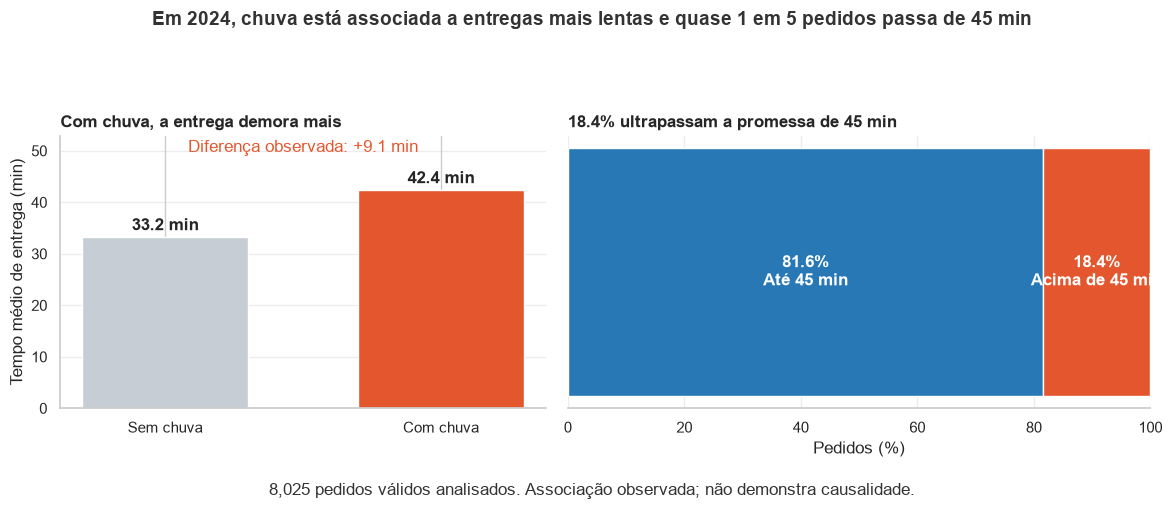

Figura salva em: D:\CAIXA VERSO\AULAS AO VIVO SETEMBRO 2026\Análise Exploratória de Dados\TRABALHO\TRABALHO FINAL\saidas\figura_principal.png


In [134]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Reutiliza a paleta da tarefa 7.0; define cores caso essa célula não tenha sido executada
cores = globals().get('CORES', {
    'principal': '#2878B5',
    'destaque': '#E4572E',
    'neutro': '#C7CDD4',
    'texto': '#333333'
})

# Preparar os dados de 2024
base = df[['data_hora', 'chuva', 'tempo_entrega_min']].copy()
base['data_hora'] = pd.to_datetime(base['data_hora'], errors='coerce')
base['tempo_entrega_min'] = pd.to_numeric(
    base['tempo_entrega_min'], errors='coerce'
)

base = base.dropna(subset=['data_hora', 'tempo_entrega_min', 'chuva'])
base = base.loc[
    (base['data_hora'].dt.year == 2024)
    & (base['tempo_entrega_min'] >= 0)
    & (base['tempo_entrega_min'] < 999)
].copy()

if base.empty:
    raise ValueError('Não há pedidos válidos de 2024 para montar a figura.')

# Médias de tempo por condição de chuva
media_chuva = base.groupby('chuva')['tempo_entrega_min'].mean()

if not {False, True}.issubset(set(media_chuva.index)):
    raise ValueError('Os dados de 2024 precisam conter pedidos com e sem chuva.')

tempo_seco = media_chuva.loc[False]
tempo_chuvoso = media_chuva.loc[True]
diferenca_chuva = tempo_chuvoso - tempo_seco

# Percentual de pedidos que cumpriram ou ultrapassaram a promessa de 45 min
no_prazo_pct = base['tempo_entrega_min'].le(45).mean() * 100
atrasados_pct = base['tempo_entrega_min'].gt(45).mean() * 100
n_pedidos = len(base)

# Criar figura com dois painéis
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(12, 5),
    gridspec_kw={'width_ratios': [1, 1.2]}
)

# Painel 1: tempo médio com e sem chuva
rotulos = ['Sem chuva', 'Com chuva']
tempos = [tempo_seco, tempo_chuvoso]
barras = ax1.bar(
    rotulos,
    tempos,
    color=[cores['neutro'], cores['destaque']],
    width=0.6
)

for barra, valor in zip(barras, tempos):
    ax1.annotate(
        f'{valor:.1f} min',
        (barra.get_x() + barra.get_width() / 2, barra.get_height()),
        xytext=(0, 5),
        textcoords='offset points',
        ha='center',
        fontweight='bold'
    )

ax1.set_ylabel('Tempo médio de entrega (min)')
ax1.set_title('Com chuva, a entrega demora mais', loc='left', fontweight='bold')
ax1.text(
    0.5, 0.94,
    f'Diferença observada: +{diferenca_chuva:.1f} min',
    transform=ax1.transAxes,
    ha='center',
    color=cores['destaque']
)
ax1.set_ylim(0, max(tempos) * 1.25)
ax1.grid(axis='y', color=cores['neutro'], alpha=0.35)
ax1.spines[['top', 'right']].set_visible(False)

# Painel 2: cumprimento da promessa de até 45 minutos
ax2.barh(
    ['Pedidos de 2024'],
    [no_prazo_pct],
    color=cores['principal'],
    label='Até 45 min'
)
ax2.barh(
    ['Pedidos de 2024'],
    [atrasados_pct],
    left=[no_prazo_pct],
    color=cores['destaque'],
    label='Acima de 45 min'
)

ax2.text(
    no_prazo_pct / 2, 0,
    f'{no_prazo_pct:.1f}%\nAté 45 min',
    ha='center', va='center', color='white', fontweight='bold'
)
ax2.text(
    no_prazo_pct + atrasados_pct / 2, 0,
    f'{atrasados_pct:.1f}%\nAcima de 45 min',
    ha='center', va='center', color='white', fontweight='bold'
)

ax2.set_xlim(0, 100)
ax2.set_xlabel('Pedidos (%)')
ax2.set_title(
    f'{atrasados_pct:.1f}% ultrapassam a promessa de 45 min',
    loc='left',
    fontweight='bold'
)
ax2.set_yticks([])
ax2.grid(axis='x', color=cores['neutro'], alpha=0.35)
ax2.spines[['top', 'right', 'left']].set_visible(False)

fig.suptitle(
    'Em 2024, chuva está associada a entregas mais lentas e quase 1 em 5 pedidos passa de 45 min',
    fontsize=14,
    fontweight='bold',
    color=cores['texto']
)
fig.text(
    0.5, 0.01,
    f'{n_pedidos:,} pedidos válidos analisados. Associação observada; não demonstra causalidade.',
    ha='center',
    color=cores['texto']
)

fig.tight_layout(rect=[0, 0.05, 1, 0.88])

# Criar a pasta de saída e salvar em alta resolução
pasta_saida = Path('saidas')
pasta_saida.mkdir(parents=True, exist_ok=True)
arquivo = pasta_saida / 'figura_principal.png'

fig.savefig(arquivo, dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

print(f'Figura salva em: {arquivo.resolve()}')

figura para a diretoria destacar dois pontos de 2024: o tempo médio de entrega com e sem chuva e a proporção de pedidos que ultrapassaram a promessa de 45 minutos.

A figura combina o contexto operacional da chuva com o cumprimento do prazo. A diferença entre dias chuvosos e secos é uma associação observada nos dados, não prova de causalidade.


### Tarefa 10.2 — Cinco achados
Escreva os **5 achados** mais importantes para a diretoria. Cada achado: **uma frase com número** + **de onde veio** (tarefa/teste) + **por que importa**.

*Sua resposta aqui*

1 - 18,39% dos pedidos válidos de 2024 (1.476 de 8.025) ultrapassaram 45 minutos — Fonte: Tarefa 5.4. Importância: quase um em cada cinco pedidos não cumpriu a promessa de entrega, indicando uma oportunidade de melhorar a confiabilidade do serviço.

2 - Nos dias chuvosos, a entrega demorou em média 9,03 minutos a mais — Fonte: Tarefas 6.8 e 9.1; teste t de Welch, p ≈ 3,54 × 10⁻¹²¹. Importância: chuva está associada a atrasos relevantes e pode ser considerada no planejamento operacional; o resultado não prova causalidade.

3 - A média diária de pedidos subiu de 20,04 no primeiro trimestre para 24,09 no quarto, cerca de 20,2% — Fonte: Tarefa 6.9. A tendência linear estimou crescimento de 31,07%, excluindo 14/08. Importância: o aumento sugere necessidade de ajustar capacidade e equipe à evolução da demanda.

4 - Em julho, 45,62% dos pedidos usaram cupom, e a média foi de 26,52 pedidos por dia — Fonte: Tarefa 6.7. Importância: julho se destaca tanto pelo uso de cupons quanto pelo volume, o que merece investigação para avaliar a campanha; a coincidência não comprova que os cupons causaram o aumento.

5 - O ticket mediano foi R 66.700 maior na cozinha Japonesa ( R 66.700 maior na cozinha Japonesa (R 103.240) do que em Doces (R$ 36.540). Fonte: Tarefas 6.3 e 9.4; teste de Kruskal–Wallis, (H=1.953,943), (p<0,001), ε² = 0,266. Importância: os tickets diferem entre tipos de cozinha, informação útil para decisões de mix e estratégia comercial.

### Tarefa 10.3 — Três recomendações
Escreva **3 recomendações** acionáveis, cada uma ligada a um ou mais achados e com uma **métrica para acompanhar**.

*Sua resposta aqui*

1 - Reduzir atrasos na entrega: planejar capacidade adicional nos períodos de maior demanda e avaliar medidas operacionais para dias chuvosos, quando o tempo médio foi 9,03 minutos maior.
Ligação: achados das tarefas 5.4 e 6.8.
Métrica: percentual de pedidos acima de 45 minutos, acompanhado separadamente em dias chuvosos e secos.

2 - Avaliar a campanha de cupons de julho: comparar campanhas futuras com períodos sem promoção e verificar se o aumento de pedidos compensa o custo do desconto, sem presumir que o cupom causou o pico de julho.
Ligação: achado da tarefa 6.7; julho teve 45,62% de uso de cupom e média de 26,52 pedidos por dia.
Métrica: pedidos por dia, taxa de uso do cupom e faturamento ou margem por pedido durante a campanha e em um período de comparação.

3 - Ajustar o mix comercial por tipo de cozinha: investigar o maior ticket mediano da culinária Japonesa e o menor de Doces para orientar ofertas, preços e divulgação, validando a rentabilidade antes de expandir qualquer estratégia.
Ligação: achados das tarefas 6.3 e 9.4.
Métrica: ticket mediano, faturamento e margem por tipo de cozinha.

### Tarefa 10.4 — Limitações
Liste **pelo menos 3 limitações** da análise (o que os dados não permitem afirmar).

*Sua resposta aqui*

1 - Não é possível concluir causalidade. Os dados mostram que entregas em dias chuvosos demoraram, em média, 9,03 minutos a mais, e que o uso de cupom está associado a mais clientes novos. Como a análise é observacional, não prova que chuva cause atrasos nem que cupons atraiam clientes; distância, horário, cidade e campanhas simultâneas podem influenciar essas relações.

2 - Possíveis confundidores não controlados: trânsito, distância, horário de pico, região, disponibilidade de entregadores e campanhas simultâneas podem influenciar os resultados.

3 - Alguns resultados são associações gerais, não diferenças entre todos os grupos. O teste de Kruskal–Wallis encontrou diferenças nos tickets entre tipos de cozinha, mas não identifica quais pares diferem sem análises pós-hoc. O resultado não prova que a cozinha, por si só, explique a diferença.

4 - Testes estatísticos têm pressupostos e limites: valores extremos, observações relacionadas e diferenças de tamanho entre grupos podem afetar os resultados. Um resultado significativo não garante relevância prática; a análise de cozinha, por exemplo, indica que existe diferença entre grupos, mas não identifica por si só quais pares diferem.

---
## Etapa 11 — Publicação

> Uma análise que só roda no seu computador não existe para a empresa. Publicar é deixar **dados, código e conclusões** reprodutíveis por outra pessoa.

### Tarefa 11.1 — Base limpa e dicionário
Salve a base tratada em `saidas/delivery_pedidos_limpo.csv` (sem colunas auxiliares de cálculo) e gere automaticamente um **dicionário de dados** da base limpa: coluna, tipo, % de faltantes e um exemplo de valor.

In [135]:
# Sua solução aqui


In [136]:
from pathlib import Path
import pandas as pd

# Colunas criadas apenas como apoio aos cálculos/análises.
# Edite a lista conforme os nomes existentes no seu notebook.
colunas_auxiliares = [
    'hora',
    'dia_semana',
    'faixa_tempo',
    'cupom_bin',
    'cliente_novo_bin'
]

# Copiar a base tratada e remover apenas auxiliares que existirem
base_exportacao = df.drop(
    columns=[col for col in colunas_auxiliares if col in df.columns]
).copy()

# Criar a pasta de saída e salvar a base limpa
pasta_saida = Path('saidas')
pasta_saida.mkdir(parents=True, exist_ok=True)

arquivo_base = pasta_saida / 'delivery_pedidos_limpo.csv'
base_exportacao.to_csv(arquivo_base, index=False, encoding='utf-8-sig')

# Criar automaticamente o dicionário de dados
def exemplo_valor(coluna):
    valores = coluna.dropna()
    if valores.empty:
        return 'Sem valores não ausentes'

    valor = valores.iloc[0]
    if isinstance(valor, (pd.Timestamp,)):
        return valor.isoformat()
    return str(valor)

dicionario = pd.DataFrame([
    {
        'coluna': nome,
        'tipo': str(base_exportacao[nome].dtype),
        'faltantes (%)': round(base_exportacao[nome].isna().mean() * 100, 2),
        'exemplo': exemplo_valor(base_exportacao[nome])
    }
    for nome in base_exportacao.columns
])

arquivo_dicionario = pasta_saida / 'dicionario_dados.csv'
dicionario.to_csv(arquivo_dicionario, index=False, encoding='utf-8-sig')

display(dicionario)
print(f'Base salva em: {arquivo_base.resolve()}')
print(f'Dicionário salvo em: {arquivo_dicionario.resolve()}')

,coluna,tipo,faltantes (%),exemplo
0,pedido_id,int64,0.00,500000
1,data_hora,datetime64[ns],0.00,2024-01-01T11:21:00
2,cidade,object,0.00,São Paulo
3,bairro,object,0.00,Tatuapé
4,restaurante_id,object,0.00,R912
5,tipo_cozinha,object,0.00,Hambúrguer
6,plataforma,object,0.00,Android
7,forma_pagamento,object,0.00,Pix
8,cupom,bool,0.00,False
9,cliente_novo,bool,0.00,False


Base salva em: D:\CAIXA VERSO\AULAS AO VIVO SETEMBRO 2026\Análise Exploratória de Dados\TRABALHO\TRABALHO FINAL\saidas\delivery_pedidos_limpo.csv
Dicionário salvo em: D:\CAIXA VERSO\AULAS AO VIVO SETEMBRO 2026\Análise Exploratória de Dados\TRABALHO\TRABALHO FINAL\saidas\dicionario_dados.csv


### Tarefa 11.1.. — Base limpa e dicionário
Gere automaticamente um dicionário de dados da base limpa: coluna, tipo, Descrição, % de faltantes e Observação / tratamento. Complete a descrição. Inclua as colunas e as **flags** que vocês criaram.

In [137]:
# Descrições das variáveis usadas no trabalho
descricoes = {
    "cidade": "Cidade onde o pedido foi realizado.",
    "data_hora": "Data e horário em que o pedido foi realizado.",
    "tipo_cozinha": "Categoria da cozinha do restaurante responsável pelo pedido.",
    "valor_pedido": "Valor monetário total do pedido.",
    "distancia_km": "Distância da entrega, em quilômetros.",
    "taxa_entrega": "Valor monetário cobrado pela entrega.",
    "tempo_entrega_min": "Tempo de entrega do pedido, em minutos.",
    "avaliacao": "Nota atribuída ao pedido ou ao serviço.",
    "chuva": "Indica se havia chuva associada ao pedido.",
    "cupom": "Indica se foi utilizado cupom no pedido.",
    "forma_pagamento": "Forma de pagamento utilizada no pedido.",
    "mes": "Mês em que o pedido foi realizado.",
    "cliente_novo": "Indica se o cliente era novo no momento do pedido.",
    "pedido_id": "Identificador do pedido.",
    "id_pedido": "Identificador do pedido.",
    "mediana_cozinha": "Mediana do valor dos pedidos do mesmo tipo de cozinha.",
    "razao": "Razão entre o valor do pedido e a mediana da sua cozinha.",
    "razao_valor_cozinha": "Razão entre o valor do pedido e a mediana da sua cozinha.",
    "tempo_invalido": "Flag que indica tempo negativo ou igual a 999.",
    "distancia_invalida": (
        "Flag que indica distância igual ou superior a 100 km, "
        "conforme o limite operacional adotado."
    ),
    "pedido_grande": (
        "Flag que indica pedido com razão valor/mediana da cozinha "
        "igual ou superior ao corte adotado."
    ),
}

observacoes = {
    "valor_pedido": (
        "Pedidos grandes foram identificados pela flag 'pedido_grande'; "
        "não foram removidos por essa flag."
    ),
    "tempo_entrega_min": (
        "Tempos negativos e iguais a 999 foram substituídos por NaN; "
        "ver 'tempo_invalido'."
    ),
    "tempo_invalido": (
        "Flag booleana criada antes de substituir os tempos inválidos por NaN."
    ),
    "distancia_km": (
        "Distâncias marcadas como inválidas foram substituídas por NaN; "
        "ver 'distancia_invalida'."
    ),
    "distancia_invalida": (
        "Flag booleana baseada no limite operacional adotado de 100 km."
    ),
    "pedido_grande": (
        "Flag booleana baseada na razão valor do pedido/mediana da cozinha; "
        "o corte adotado foi 4,5."
    ),
    "mediana_cozinha": "Coluna auxiliar calculada por tipo de cozinha.",
    "razao": "Coluna auxiliar usada para comparar pedidos dentro da cozinha.",
    "razao_valor_cozinha": "Coluna auxiliar usada para comparar pedidos dentro da cozinha.",
}

def tipo_coluna(serie):
    if pd.api.types.is_bool_dtype(serie):
        return "Booleana"
    if pd.api.types.is_datetime64_any_dtype(serie):
        return "Data/hora"
    if pd.api.types.is_numeric_dtype(serie):
        return "Numérica"
    if isinstance(serie.dtype, pd.CategoricalDtype):
        return "Categórica"
    return "Texto/categórica"

linhas = []

for coluna in df.columns:
    descricao = descricoes.get(coluna)
    if descricao is None:
        descricao = f"Descrição a completar para a coluna '{coluna}'."

    observacao = observacoes.get(
        coluna,
        "Mantida na base limpa; conferir eventuais valores ausentes."
    )

    linhas.append({
        "coluna": coluna,
        "tipo": f"{tipo_coluna(df[coluna])} ({df[coluna].dtype})",
        "Descrição": descricao,
        "% de faltantes": round(df[coluna].isna().mean() * 100, 2),
        "Observação / tratamento": observacao,
    })

dicionario = pd.DataFrame(linhas)

# Mostra a tabela completa
display(dicionario)

# Lista colunas cuja descrição ainda precisa ser preenchida
colunas_sem_descricao = [
    coluna for coluna in df.columns
    if coluna not in descricoes
]

if colunas_sem_descricao:
    print("Complete as descrições destas colunas:", colunas_sem_descricao)

,coluna,tipo,Descrição,% de faltantes,Observação / tratamento
0,pedido_id,Numérica (int64),Identificador do pedido.,0.00,Mantida na base limpa; conferir eventuais valores ausentes.
1,data_hora,Data/hora (datetime64[ns]),Data e horário em que o pedido foi realizado.,0.00,Mantida na base limpa; conferir eventuais valores ausentes.
2,cidade,Texto/categórica (object),Cidade onde o pedido foi realizado.,0.00,Mantida na base limpa; conferir eventuais valores ausentes.
3,bairro,Texto/categórica (object),Descrição a completar para a coluna 'bairro'.,0.00,Mantida na base limpa; conferir eventuais valores ausentes.
4,restaurante_id,Texto/categórica (object),Descrição a completar para a coluna 'restaurante_id'.,0.00,Mantida na base limpa; conferir eventuais valores ausentes.
5,tipo_cozinha,Texto/categórica (object),Categoria da cozinha do restaurante responsável pelo pedido.,0.00,Mantida na base limpa; conferir eventuais valores ausentes.
6,plataforma,Texto/categórica (object),Descrição a completar para a coluna 'plataforma'.,0.00,Mantida na base limpa; conferir eventuais valores ausentes.
7,forma_pagamento,Texto/categórica (object),Forma de pagamento utilizada no pedido.,0.00,Mantida na base limpa; conferir eventuais valores ausentes.
8,cupom,Booleana (bool),Indica se foi utilizado cupom no pedido.,0.00,Mantida na base limpa; conferir eventuais valores ausentes.
9,cliente_novo,Booleana (bool),Indica se o cliente era novo no momento do pedido.,0.00,Mantida na base limpa; conferir eventuais valores ausentes.


Complete as descrições destas colunas: ['bairro', 'restaurante_id', 'plataforma', 'data', 'hora', 'dia_semana', 'avaliacao_ausente', 'faixa_tempo_entrega']


*Sua resposta aqui*

## Principais achados

![Figura principal: indicadores operacionais de 2024](saidas/figura_principal.png)

1. **18,39% dos pedidos válidos de 2024 (1.476 de 8.025) ultrapassaram 45 minutos.** Fonte: Tarefa 5.4. Isso representa quase um pedido em cada cinco acima do prazo prometido.

2. **Nos cidade-dias chuvosos, o tempo médio de entrega foi 9,03 minutos maior.** Fonte: Tarefas 6.8 e 9.1; teste t de Welch, *p* < 0,001. O resultado sugere uma associação relevante para o planejamento operacional, mas não prova causalidade.

3. **A média diária passou de 20,04 pedidos no primeiro trimestre para 24,09 no quarto, aumento aproximado de 20,2%.** Fonte: Tarefa 6.9. A tendência linear estimou crescimento de 31,07%, excluindo o dia anômalo 14/08; isso aponta para a necessidade de acompanhar e planejar a capacidade conforme a demanda.

4. **Em julho, 45,62% dos pedidos usaram cupom e houve 26,52 pedidos por dia, em média.** Fonte: Tarefa 6.7. O pico de uso de cupons coincidiu com maior volume, mas os dados não demonstram que os cupons tenham causado esse aumento.

5. **A mediana do ticket variou R$ 66.700 entre Japonesa (R$ 103.240) e Doces (R$ 36.540).** Fonte: Tarefas 6.3 e 9.4; Kruskal–Wallis, *p* < 0,001, ε² = 0,266. Essa diferença pode orientar investigações sobre o mix comercial; o teste não identifica sozinho quais pares de cozinhas diferem.

### Tarefa 11.3 — Checklist de publicação
Antes de entregar, confiram (marquem com `x`):

- [X] Repositório Git criado e repositório público.
- [X] `README.md` preenchido a partir do `modelo_README.md`, com a figura principal aparecendo.
- [X] O CSV original **não** foi alterado; a base limpa está em `saidas/`.
- [X] *Kernel → Restart & Run All* roda sem erros do início ao fim.
- [X] Nenhum gráfico sem título, rótulos e unidade.

> 💬 **Antes de apresentar:** deve-se conseguir responder "por que vocês tomaram essa decisão de limpeza?" e "o que esse p-valor significa?" sobre **qualquer** etapa.

Explicando as decisões: por exemplo, valores impossíveis ou sentinela, como tempo 999, foram tratados como inválidos; valores ausentes não devem ser convertidos automaticamente em zero; flags ajudam a manter os pedidos sem ocultar problemas de qualidade.

Um p-valor é, supondo que a hipótese nula seja verdadeira, a probabilidade de observar um resultado tão extremo quanto o obtido (ou mais). Ele não é a probabilidade de H₀ ser verdadeira nem prova causalidade. Se aparecer 0.0, geralmente é arredondamento/limite de precisão: o p-valor é extremamente pequeno, não que é exatamente zero.

---
## Resumo da metodologia

| Etapa | Pergunta que responde | Ferramentas |
|---|---|---|
| 1. Perguntas e hipóteses | o que queremos saber? | markdown, H0/H1 |
| 2. Carga e inspeção | o que veio e com que problemas? | `info`, `nunique`, `isna`, `describe`, `duplicated` |
| 3. Limpeza | como deixar os dados confiáveis? | `drop`, `to_datetime`, `.str`, `map`, `to_numeric`, `fillna` |
| 4. Outliers | é erro ou é real? | boxplot, z-score, IQR, investigação, flags |
| 5. Descritiva | como cada variável se comporta? | `describe`, CV, assimetria, percentis |
| 6. Sumarização e granularidade | o que muda por grupo e por período? | `groupby`/`agg`, `pivot_table`, `crosstab`, `resample` |
| 7. Visualização | como mostrar a resposta? | seaborn + estilização |
| 8. Correlação | o que anda junto? | `corr`, heatmap, scatter |
| 9. Hipóteses | é real ou acaso? e importa? | t de Welch, Mann-Whitney, Spearman, Kruskal-Wallis, χ², tamanho de efeito |
| 10. Conclusões | o que a diretoria deve fazer? | 5 achados + 3 recomendações + limitações |
| 11. Publicação | outra pessoa consegue reproduzir? | CSV limpo, README, Git |